# READ FIRST: what to run and what not to run

**Never use "Run all".** 30 cells in this notebook write files. A full run on 30 Oct rewrote 18 frozen files and raised the test-access count to 3.

## Run only this
- **The last two cells: "Summary for the panel (loads saved files)".** They only read saved files from Drive. They change nothing.
- Block 59 (latency): run once, after the Summary. It prints timings and writes no files.
- Block 60 (voice demo): run once after Block 59. It loads a speech model and writes no files. Needs cbse_demo_questions_v1.csv in project_s_qa/processed/ on Drive.
- Blocks 61 and 62 (diagnostics): run once after Block 60. They load models, print results and write no files. Paste the printed output to Jigar's notes.

## Do not run (everything else)
All other cells are one-time producers of saved results. Re-running them rewrites frozen files.

- **Data and splits (Blocks 1 to 11):** results are already saved.
- **Block 17 (LLM scorer, uses the Anthropic API):** dev-only side result, not part of the deployed scorer. Needs an API key. Do not run.
- **Model training and comparison (Blocks 18 to 21, including Block 19 fine-tune and Block 26 RoBERTa record):** already trained and saved. Block 26 is the only record of the RoBERTa run.
- **Freeze check and test evaluation (Blocks 22 to 24):** running these raises the test-access count.
- **Bootstrap, seeds and ablations (Blocks 41 and 42):** already saved. Block 49 reads the Block 42 seed summary.
- **Demo and parity check (demo cells, `A_predict.py`):** already generated on 31 Oct.
- **Reporting blocks (47 to 49 and 58):** replaced by the Summary section. Keep them collapsed as the archive.

## If you must re-run one block
1. Copy the project folder on Drive first.
2. Run only that one block, never the ones around it.
3. Check the file list afterwards: frozen files must keep their old timestamps.

## If the Summary prints "MISSING"
A file name differs from what the cell expects. Do not re-run any producer cell. Fix the name in the Summary cell instead.

### Run history note (30 Oct 2026)
The whole notebook was run end to end on 30 Oct 2026. The deployed scorer's dev results did not change (QWK 0.432 overall, 0.630 seen, 0.317 unseen). The Block 30 manifest check lists 18 frozen v1 files as changed, and the test-access log now reads 3 evaluations (it read 2 before), so test results stay exploratory. SBERT embeddings were recomputed in Block 15; legacy comparison tables moved by 0.006 or less in the rows checked. Block 26 (RoBERTa-base) must not be re-run: its weights were never saved.

# Phase 1 — Prepare the curriculum dataset

- Before teaching a system to evaluate students’ answers, we first need to prepare examples of questions, correct answers, student answers, and their expected scores. Phase 1 organizes these examples so the system can learn and be tested fairly.


## Group 1: Setup, load, unify

- gather all the answer sheets into one register

### Block 1: install, config, folders
----
ALGORITHM Setup
INPUT : none
OUTPUT: reproducible environment, 4 folders, dataset names, expected counts

1. Install libraries: datasets, pandas, scikit-learn, pyarrow
2. SEED ← 42
   Fix the random seed for Python and NumPy      (same result on every run)
3. ROOT ← "project_s_qa"
   FOR each name IN {raw, interim, processed, reports}
       create folder ROOT/name
4. HF_IDS ← { scientsbank → "nkazi/SciEntsBank",
              beetle      → "nkazi/Beetle" }
5. EXPECTED ← official row count of every split from the dataset cards
       scientsbank : train 4969, test_ua 540, test_uq 733, test_ud 4562
       beetle      : train 3941, test_ua 439, test_uq 819
6. Print the folder paths
END

In [ ]:
!pip -q install datasets pandas scikit-learn pyarrow

import os, json, hashlib, random, datetime
import numpy as np
import pandas as pd
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Optional: keep files after the runtime resets
# from google.colab import drive; drive.mount('/content/drive')
# ROOT = "/content/drive/MyDrive/project_s_qa"
ROOT = "project_s_qa"

DIRS = {k: f"{ROOT}/{k}" for k in ["raw", "interim", "processed", "reports"]}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

HF_IDS = {"scientsbank": "nkazi/SciEntsBank", "beetle": "nkazi/Beetle"}

# Counts from the dataset cards, used only as a sanity check
EXPECTED = {
    "scientsbank": {"train": 4969, "test_ua": 540, "test_uq": 733, "test_ud": 4562},
    "beetle": {"train": 3941, "test_ua": 439, "test_uq": 819},
}
print("Folders:", DIRS)

Folders: {'raw': 'project_s_qa/raw', 'interim': 'project_s_qa/interim', 'processed': 'project_s_qa/processed', 'reports': 'project_s_qa/reports'}


### Block 2: load both datasets and check counts
---
ALGORITHM LoadAndVerify
INPUT : HF_IDS, EXPECTED
OUTPUT: raw (both datasets, every split)

1. FOR each dataset in HF_IDS
       raw[dataset] ← download from Hugging Face
2. FOR each dataset, FOR each split
       IF rows = EXPECTED THEN print "OK"
       ELSE print "MISMATCH (expected N)"
3. PRINT column names and the 5 label names

In [ ]:
raw = {name: load_dataset(hf_id) for name, hf_id in HF_IDS.items()}

for name, dsd in raw.items():
    print(f"\n=== {name} ===")
    for split, d in dsd.items():
        exp = EXPECTED[name].get(split)
        status = "OK" if exp == len(d) else f"MISMATCH (expected {exp})"
        print(f"{split:8s} rows={len(d):6d}  {status}")
    print("columns:", dsd["train"].column_names)
    print("label names:", dsd["train"].features["label"].names)

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

data/train-00001.parquet: reconstructing file:   0%|          |  0.00B /  233kB            

data/train-00001.parquet: downloading bytes:           |  0.00B            

data/test-ua-00001.parquet: reconstructing file:   0%|          |  0.00B / 52.7kB            

data/test-ua-00001.parquet: downloading bytes:           |  0.00B            

data/test-uq-00001.parquet: reconstructing file:   0%|          |  0.00B / 35.7kB            

... (14 outputs left out)

Generating train split:   0%|          | 0/3941 [00:00<?, ? examples/s]

Generating test_ua split:   0%|          | 0/439 [00:00<?, ? examples/s]

Generating test_uq split:   0%|          | 0/819 [00:00<?, ? examples/s]


=== scientsbank ===
train    rows=  4969  OK
test_ua  rows=   540  OK
test_uq  rows=   733  OK
test_ud  rows=  4562  OK
columns: ['id', 'question', 'reference_answer', 'student_answer', 'label']
label names: ['correct', 'contradictory', 'partially_correct_incomplete', 'irrelevant', 'non_domain']

=== beetle ===
train    rows=  3941  OK
test_ua  rows=   439  OK
test_uq  rows=   819  OK
columns: ['id', 'question', 'reference_answer', 'student_answer', 'label']
label names: ['correct', 'contradictory', 'partially_correct_incomplete', 'irrelevant', 'non_domain']


### Block 3: one shared table
---
ALGORITHM Unify
INPUT : raw
OUTPUT: sra_unified_raw.parquet (one table, 16,003 rows)

1. FUNCTION make_qid(dataset, question, reference)
       RETURN prefix + first 8 chars of MD5(question + "||" + reference)
2. FOR each dataset, FOR each split
       convert to a table
       label5 ← label number turned back into its text name
       rename id → source_id
       ADD dataset, orig_split
3. STACK all tables into one
4. Trim spaces in question, reference, student answer; fill missing with ""
5. question_id ← make_qid(...) for every row
6. uid ← dataset-split-rownumber
7. SAVE to raw/ and print counts per split, unique questions, empty answers

In [ ]:
def make_qid(ds_name, question, reference):
    key = (question.strip() + "||" + reference.strip()).encode("utf-8")
    return ds_name[:3].upper() + "-" + hashlib.md5(key).hexdigest()[:8]

frames = []
for ds_name, dsd in raw.items():
    for split, d in dsd.items():
        df = d.to_pandas()
        feat = d.features["label"]
        df["label5"] = df["label"].map(lambda i: feat.int2str(int(i)))
        df = df.rename(columns={"id": "source_id"})
        df["dataset"] = ds_name
        df["orig_split"] = split
        frames.append(df)

data = pd.concat(frames, ignore_index=True)

for c in ["question", "reference_answer", "student_answer"]:
    data[c] = data[c].fillna("").astype(str).str.strip()

data["question_id"] = [
    make_qid(r.dataset, r.question, r.reference_answer) for r in data.itertuples()
]
data.insert(0, "uid", data["dataset"] + "-" + data["orig_split"] + "-" + data.index.astype(str))
data = data[["uid", "dataset", "orig_split", "source_id", "question_id",
             "question", "reference_answer", "student_answer", "label5"]]

data.to_parquet(f"{DIRS['raw']}/sra_unified_raw.parquet", index=False)

print("Total rows:", len(data))
print(data.groupby(["dataset", "orig_split"]).size())
print("\nUnique questions per dataset (expect about 197 and 56):")
print(data.groupby("dataset")["question_id"].nunique())
print("Unique question TEXTS per dataset:")
print(data.groupby("dataset")["question"].nunique())
print("Empty student answers:", (data["student_answer"] == "").sum())
display(data.sample(5, random_state=SEED))

Total rows: 16003
dataset      orig_split
beetle       test_ua        439
             test_uq        819
             train         3941
scientsbank  test_ua        540
             test_ud       4562
             test_uq        733
             train         4969
dtype: int64

Unique questions per dataset (expect about 197 and 56):
dataset
beetle          52
scientsbank    196
Name: question_id, dtype: int64
Unique question TEXTS per dataset:
dataset
beetle          42
scientsbank    195
Name: question, dtype: int64
Empty student answers: 0


,uid,dataset,orig_split,source_id,question_id,question,reference_answer,student_answer,label5
5970,scientsbank-test_uq-5970,scientsbank,test_uq,PS.2b.468.1,SCI-2dc90e27,What happens to the volume of the sound if you...,The volume increases. The sound is louder.,It will make a loud sound.,correct
6560,scientsbank-test_ud-6560,scientsbank,test_ud,EV.8c.165.1,SCI-15fdbd91,Rachael tried to hatch brine shrimp under a ra...,Rachael could put the unhatched eggs in a salt...,She could add more salt to the 0 milliliters s...,correct
7580,scientsbank-test_ud-7580,scientsbank,test_ud,HB.6a.533.1,SCI-b3385142,What is the main job of muscles in the body?,The main job of muscles is to move bones.,To help the body move.,partially_correct_incomplete
304,scientsbank-train-304,scientsbank,train,EM.26.354.1,SCI-fe737fe0,Salt crystals form when the water evaporates f...,The salt crystals are squares with Xs on top.,It was while you could see through square.,irrelevant
8242,scientsbank-test_ud-8242,scientsbank,test_ud,HB.42b.430.1,SCI-bc55d290,Sam and Jasmine were sitting on a park bench e...,Sam's response was to slap the mosquito.,Sam's response was to say sorry.,irrelevant


# Phase 2 — Build the baseline

## Group 2: Labels, distributions, quality checks

### Block 4: label mappings
---
ALGORITHM MapLabels
INPUT : unified table with label5 (5 original teacher grades)
OUTPUT: 5 new label columns + incorrect_reason

1. ASSERT every label5 value is one of
   {correct, contradictory, partially_correct_incomplete, irrelevant, non_domain}
2. OFFICIAL_3 ← { correct → correct, contradictory → contradictory,
                  partially_correct, irrelevant, non_domain → incorrect }
3. OURS_3     ← { correct → correct, partially_correct → partial,
                  contradictory, irrelevant, non_domain → incorrect }
4. SCORE      ← { incorrect = 0, partial = 1, correct = 2 }
5. ADD columns: label5_id, label3_official, label2 (correct vs not),
                label3_ours, score_ours
6. incorrect_reason ← label5 IF label3_ours = incorrect ELSE ""
7. ASSERT no label is unmapped; PRINT label5 × label3_ours table

In [ ]:
LABEL5_ORDER = ["correct", "contradictory", "partially_correct_incomplete",
                "irrelevant", "non_domain"]
assert set(data["label5"].unique()) <= set(LABEL5_ORDER), data["label5"].unique()

# Official SemEval 3-way: correct / contradictory / incorrect
OFFICIAL_3 = {"correct": "correct", "contradictory": "contradictory",
              "partially_correct_incomplete": "incorrect",
              "irrelevant": "incorrect", "non_domain": "incorrect"}

# Our project scheme (ordinal): incorrect < partial < correct
OURS_3 = {"correct": "correct", "partially_correct_incomplete": "partial",
          "contradictory": "incorrect", "irrelevant": "incorrect",
          "non_domain": "incorrect"}
SCORE = {"incorrect": 0, "partial": 1, "correct": 2}

data["label5_id"] = data["label5"].map({l: i for i, l in enumerate(LABEL5_ORDER)})
data["label3_official"] = data["label5"].map(OFFICIAL_3)
data["label2"] = np.where(data["label5"] == "correct", "correct", "incorrect")
data["label3_ours"] = data["label5"].map(OURS_3)
data["score_ours"] = data["label3_ours"].map(SCORE)
# Keep why an answer is "incorrect" (needed later for NLI / contradiction analysis)
data["incorrect_reason"] = np.where(data["label3_ours"] == "incorrect", data["label5"], "")

label_cols = ["label5_id", "label3_official", "label2", "label3_ours", "score_ours"]
assert data[label_cols].notna().all().all(), "unmapped labels found"

print(pd.crosstab(data["label5"], data["label3_ours"]))

label3_ours                   correct  incorrect  partial
label5                                                   
contradictory                       0       2442        0
correct                          6644          0        0
irrelevant                          0       2812        0
non_domain                          0        304        0
partially_correct_incomplete        0          0     3801


### Block 5: label distribution and per-question report
---
ALGORITHM LabelReport
INPUT : labelled table
OUTPUT: distribution tables, per-question stats, saved CSVs

1. COUNT answers per (dataset, split) for each label5
2. COUNT and PERCENT answers per (dataset, split) for each label3_ours
3. FOR each question
       n ← number of answers
       pct_correct, pct_partial, pct_incorrect
4. PRINT answers-per-question statistics per dataset
5. COUNT questions with fewer than 10 answers
6. COUNT questions that are 100% correct or 100% incorrect
7. SAVE the tables to reports/

In [ ]:
dist5 = pd.crosstab([data["dataset"], data["orig_split"]], data["label5"])
dist3_n = pd.crosstab([data["dataset"], data["orig_split"]], data["label3_ours"])
dist3_pct = (pd.crosstab([data["dataset"], data["orig_split"]], data["label3_ours"],
                         normalize="index") * 100).round(1)

print("5-way counts:\n", dist5, "\n")
print("Our 3-level counts:\n", dist3_n, "\n")
print("Our 3-level %:\n", dist3_pct)

pq = (data.groupby(["dataset", "question_id"])
      .agg(n=("uid", "size"),
           pct_correct=("score_ours", lambda s: (s == 2).mean()),
           pct_partial=("score_ours", lambda s: (s == 1).mean()),
           pct_incorrect=("score_ours", lambda s: (s == 0).mean()))
      .reset_index())

print("\nAnswers per question:")
print(pq.groupby("dataset")["n"].describe().round(1))
print("\nQuestions with fewer than 10 answers:", (pq["n"] < 10).sum())
print("Questions with 100% correct or 100% incorrect:",
      ((pq.pct_correct == 1) | (pq.pct_incorrect == 1)).sum())

dist5.to_csv(f"{DIRS['reports']}/label5_distribution.csv")
dist3_n.to_csv(f"{DIRS['reports']}/label3_ours_distribution.csv")
pq.to_csv(f"{DIRS['reports']}/per_question_stats.csv", index=False)

5-way counts:
 label5                  contradictory  correct  irrelevant  non_domain  \
dataset     orig_split                                                   
beetle      test_ua               111      176          17          23   
            test_uq               244      344          19          40   
            train                1049     1665         113         195   
scientsbank test_ua                58      233         133           3   
            test_ud               417     1917        1222          20   
            test_uq                64      301         193           0   
            train                 499     2008        1115          23   

label5                  partially_correct_incomplete  
dataset     orig_split                                
beetle      test_ua                              112  
            test_uq                              172  
            train                                919  
scientsbank test_ua                        

### Block 6: data-quality and leakage checks, then save
---
ALGORITHM QualityCheck
INPUT : labelled table
OUTPUT: quality report (JSON) + saved labelled file

1. norm_answer ← lowercase, collapse spaces, trim
2. COUNT empty answers and one-word answers
3. COUNT question texts that have more than one reference answer
4. COUNT (question, answer) duplicates that carry different labels
5. FOR each test split
       COUNT rows whose (question, answer) also appears in train
6. FOR each dataset and test split
       COUNT rows whose question appears in train
7. COMPUTE answer length (words) per dataset
8. SAVE sra_unified_labeled.parquet and data_quality_report.json

In [ ]:
report = {}
data["norm_answer"] = (data["student_answer"].str.lower()
                       .str.replace(r"\s+", " ", regex=True).str.strip())

# 1. Empty or very short answers
report["empty_answers"] = int((data["norm_answer"] == "").sum())
report["one_word_answers"] = int((data["norm_answer"].str.split().str.len() <= 1).sum())

# 2. Same question text with more than one reference answer
multi_ref = (data.groupby(["dataset", "question"])["reference_answer"].nunique() > 1).sum()
report["question_texts_with_multiple_references"] = int(multi_ref)

# 3. Duplicate answers with conflicting labels (label noise)
g = data.groupby(["dataset", "question_id", "norm_answer"])["label5"].nunique()
report["duplicate_answers_with_conflicting_labels"] = int((g > 1).sum())

# 4. Answer leakage: test rows whose (question, answer) also appears in train
train_keys = set(zip(data.loc[data.orig_split == "train", "question_id"],
                     data.loc[data.orig_split == "train", "norm_answer"]))
for s in ["test_ua", "test_uq", "test_ud"]:
    sub = data[data.orig_split == s]
    report[f"{s}_answers_also_in_train"] = int(
        sum((q, a) in train_keys for q, a in zip(sub.question_id, sub.norm_answer)))

# 5. Question leakage: unseen splits should share no questions with train
for ds in data.dataset.unique():
    tq = set(data[(data.dataset == ds) & (data.orig_split == "train")].question_id)
    for s in ["test_ua", "test_uq", "test_ud"]:
        sub = data[(data.dataset == ds) & (data.orig_split == s)]
        if len(sub):
            report[f"{ds}_{s}_questions_in_train"] = (
                f"{sub.question_id.isin(tq).sum()} of {len(sub)} rows")

# 6. Length statistics
data["answer_words"] = data["student_answer"].str.split().str.len()
report["answer_words_by_dataset"] = (data.groupby("dataset")["answer_words"]
                                     .describe().round(1).to_dict("index"))

for k, v in report.items():
    print(f"{k}: {v}")

data.drop(columns=["norm_answer"]).to_parquet(
    f"{DIRS['processed']}/sra_unified_labeled.parquet", index=False)
with open(f"{DIRS['reports']}/data_quality_report.json", "w") as f:
    json.dump(report, f, indent=2, default=str)
print("\nSaved labeled table and quality report.")

empty_answers: 0
one_word_answers: 271
question_texts_with_multiple_references: 2
duplicate_answers_with_conflicting_labels: 13
test_ua_answers_also_in_train: 28
test_uq_answers_also_in_train: 8
test_ud_answers_also_in_train: 0
scientsbank_test_ua_questions_in_train: 540 of 540 rows
scientsbank_test_uq_questions_in_train: 0 of 733 rows
scientsbank_test_ud_questions_in_train: 0 of 4562 rows
beetle_test_ua_questions_in_train: 439 of 439 rows
beetle_test_uq_questions_in_train: 60 of 819 rows
answer_words_by_dataset: {'beetle': {'count': 5199.0, 'mean': 9.8, 'std': 6.2, 'min': 1.0, '25%': 6.0, '50%': 9.0, '75%': 12.0, 'max': 103.0}, 'scientsbank': {'count': 10804.0, 'mean': 12.0, 'std': 7.9, 'min': 1.0, '25%': 6.0, '50%': 10.0, '75%': 16.0, 'max': 110.0}}

Saved labeled table and quality report.


## Group 3: Source register, question bank, rubrics

### Block 7: source register (Step 1) and CBSE syllabus hook
---
ALGORITHM SourceRegister
INPUT : unified table, optional syllabus.csv
OUTPUT: source_register.csv

1. today ← current date
2. sources ← one record per data source:
     SRC-01 SciEntsBank (loaded, 10,804 rows)
     SRC-02 Beetle      (loaded, 5,199 rows)
     SRC-03 ScAA        (deferred, Hindi/Marathi, out of scope)
   each with: location, license, language, citation, status, notes
3. IF syllabus.csv exists
       topic_id ← class-subject_code-chapter_no
       ADD one CBSE/NCERT row per textbook, status = pending_official_url_check
   ELSE PRINT "not found, continuing without it"
4. access_date ← today
5. SAVE source_register.csv

In [ ]:
today = datetime.date.today().isoformat()
CITE = "Dzikovska et al. 2013, SemEval-2013 Task 7 (aclanthology.org/S13-2045)"

sources = [
    dict(source_id="SRC-01", name="SciEntsBank (SRA corpus)", kind="public_dataset",
         location="huggingface.co/datasets/nkazi/SciEntsBank", license="CC-BY-4.0",
         language="en", rows=int((data.dataset == "scientsbank").sum()),
         citation=CITE + "; footnote the HF page", status="loaded",
         notes="Grades 3-6 science; splits train/test_ua/test_uq/test_ud"),
    dict(source_id="SRC-02", name="Beetle (SRA corpus)", kind="public_dataset",
         location="huggingface.co/datasets/nkazi/Beetle", license="CC-BY-4.0",
         language="en", rows=int((data.dataset == "beetle").sum()),
         citation=CITE + "; footnote the HF page", status="loaded",
         notes="Basic electricity tutoring; splits train/test_ua/test_uq; best reference answer only"),
    dict(source_id="SRC-03", name="ScAA (Pratham)", kind="public_dataset",
         location="github.com/PrathamOrg/ScAA-Dataset", license="not checked",
         language="hi/mr", rows=None, citation="Agarwal et al. 2020 (ICON)",
         status="deferred", notes="Hindi/Marathi, out of scope (English-only)"),
]

# ---- CBSE hook: reads syllabus.csv if you uploaded it ----
SUBJ_CODE = {"English": "ENG", "Mathematics": "MAT", "Science": "SCI",
             "Social Science": "SOC", "Science + Social Science": "WAU"}
if os.path.exists("syllabus.csv"):
    syl = pd.read_csv("syllabus.csv")
    syl["topic_id"] = syl.apply(
        lambda r: f"{r['class']}-{SUBJ_CODE[r['subject_track']]}-{int(r['chapter_no']):02d}", axis=1)
    syl.to_csv(f"{DIRS['interim']}/syllabus_with_ids.csv", index=False)
    tb = (syl.groupby(["class", "subject", "textbook"])
          .agg(chapters=("chapter_no", "count"),
               needs_check=("source_status", lambda s: int((s == "needs_check").sum())))
          .reset_index())
    for i, r in tb.iterrows():
        sources.append(dict(
            source_id=f"CBSE-{i+1:02d}",
            name=f"NCERT Class {r['class']} {r['subject']}: {r['textbook']}",
            kind="textbook_syllabus", location="",
            license="NCERT copyright: keep PDFs private, no redistribution",
            language="en", rows=int(r["chapters"]), citation="NCERT",
            status="pending_official_url_check",
            notes=f"{r['needs_check']} chapter titles need check"))
    print("CBSE syllabus loaded:", len(syl), "chapters")
else:
    print("syllabus.csv not found. Upload it to add CBSE rows. Continuing without it.")

sr = pd.DataFrame(sources)
sr["access_date"] = today
sr.to_csv(f"{DIRS['processed']}/source_register.csv", index=False)
display(sr)

syllabus.csv not found. Upload it to add CBSE rows. Continuing without it.


,source_id,name,kind,location,license,language,rows,citation,status,notes,access_date
0,SRC-01,SciEntsBank (SRA corpus),public_dataset,huggingface.co/datasets/nkazi/SciEntsBank,CC-BY-4.0,en,10804.0,"Dzikovska et al. 2013, SemEval-2013 Task 7 (ac...",loaded,Grades 3-6 science; splits train/test_ua/test_...,2026-10-30
1,SRC-02,Beetle (SRA corpus),public_dataset,huggingface.co/datasets/nkazi/Beetle,CC-BY-4.0,en,5199.0,"Dzikovska et al. 2013, SemEval-2013 Task 7 (ac...",loaded,Basic electricity tutoring; splits train/test_...,2026-10-30
2,SRC-03,ScAA (Pratham),public_dataset,github.com/PrathamOrg/ScAA-Dataset,not checked,hi/mr,NaN,Agarwal et al. 2020 (ICON),deferred,"Hindi/Marathi, out of scope (English-only)",2026-10-30


### Block 8: question bank


---
ALGORITHM QuestionBank
INPUT : sra_unified_labeled.parquet
OUTPUT: question_bank.csv, empty CBSE template

1. LOAD labelled table from Drive
2. module_code, question_code ← parsed from source_id
3. FOR each (dataset, question_id)
       store question text, reference answer, n_answers,
             splits it appears in, pct_correct
4. question_type ← keyword rule
       why/explain/because → explain
       how/describe/compare → describe_apply
       what/which/who/name → recall
5. difficulty ← pct_correct ≥ 0.65 easy, ≤ 0.35 hard, else medium
6. held_out_type ← seen (in train) | unseen_question | unseen_domain
7. SAVE question_bank.csv and an empty CBSE template (same columns)


In [ ]:
import os, re
import numpy as np, pandas as pd
from google.colab import drive

drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/project_s_qa"
DIRS = {k: f"{ROOT}/{k}" for k in ["raw", "interim", "processed", "reports"]}
for d_ in DIRS.values():
    os.makedirs(d_, exist_ok=True)

src = f"{DIRS['processed']}/sra_unified_labeled.parquet"
assert os.path.exists(src), "sra_unified_labeled.parquet is missing. Run the recovery block first."
data = pd.read_parquet(src)

d = data.copy()
d["module_code"] = d["source_id"].str.split(".").str[0]
d["question_code"] = d["source_id"].str.split(".").str[:2].str.join(".")

def qtype(q):
    t = q.lower()
    if re.search(r"\b(why|explain|because|reason)\b", t): return "explain"
    if re.search(r"\b(how|describe|compare|what happens|predict)\b", t): return "describe_apply"
    if re.search(r"\b(what|which|who|name|list|where|when)\b", t): return "recall"
    return "other"

def difficulty(p):
    return "easy" if p >= 0.65 else ("hard" if p <= 0.35 else "medium")

qb = (d.groupby(["dataset", "question_id"])
      .agg(question_text=("question", "first"),
           reference_answer=("reference_answer", "first"),
           module_code=("module_code", "first"),
           question_code=("question_code", "first"),
           n_answers=("uid", "size"),
           splits=("orig_split", lambda s: ",".join(sorted(set(s)))),
           pct_correct=("score_ours", lambda s: round(float((s == 2).mean()), 3)))
      .reset_index())

qb["question_type"] = qb["question_text"].map(qtype)
qb["type_basis"] = "auto_keyword_rule"
qb["difficulty"] = qb["pct_correct"].map(difficulty)
qb["difficulty_basis"] = "empirical_pct_correct (descriptive only, never a model feature)"
qb["held_out_type"] = np.where(qb.splits.str.contains("train"), "seen",
                      np.where(qb.splits.str.contains("test_uq"), "unseen_question",
                               "unseen_domain"))
qb["subject"] = "Science"
qb["language"] = "en"
qb["status"] = "imported"
qb["version"] = "v0.1"

QB_COLUMNS = ["question_id", "dataset", "topic_id", "subject", "class", "question_text",
              "reference_answer", "question_type", "difficulty", "language",
              "source_page", "drafted_by", "reviewer", "status", "version"]
qb["topic_id"] = qb["module_code"]
qb["class"] = None
qb["source_page"] = ""
qb["drafted_by"] = "SemEval-2013 authors"
qb["reviewer"] = ""

pd.DataFrame(columns=QB_COLUMNS).to_csv(
    f"{DIRS['processed']}/cbse_question_bank_template.csv", index=False)
qb.to_csv(f"{DIRS['processed']}/question_bank.csv", index=False)

print("Saved:", f"{DIRS['processed']}/question_bank.csv")
print("Questions:", len(qb), "(expect about 253)")
print(qb.groupby("dataset").size(), "\n")
print(pd.crosstab(qb.dataset, qb.question_type), "\n")
print(pd.crosstab(qb.dataset, qb.difficulty), "\n")
print(pd.crosstab(qb.dataset, qb.held_out_type))

Mounted at /content/drive
Saved: /content/drive/MyDrive/project_s_qa/processed/question_bank.csv
Questions: 248 (expect about 253)
dataset
beetle          52
scientsbank    196
dtype: int64 

question_type  describe_apply  explain  recall
dataset                                       
beetle                      2       40      10
scientsbank                59       83      54 

difficulty   easy  hard  medium
dataset                        
beetle         10    16      26
scientsbank    37    89      70 

held_out_type  seen  unseen_domain  unseen_question
dataset                                            
beetle           44              0                8
scientsbank     135             46               15


### Block 9: rubric stubs
---
ALGORITHM RubricStubs
INPUT : question bank, train split
OUTPUT: rubrics.json (one draft per question)

1. LEVELS ← {2: all ideas, no wrong ones
             1: some ideas / incomplete
             0: wrong, contradictory, off-topic}
2. FOR each question
       IF it has train answers
           accepted_variants ← 3 correct train answers
           misconceptions    ← 3 contradictory train answers
           worked_examples   ← 2 each of correct / partial / incorrect
       ELSE leave examples empty ("held-out question")
       negation_sensitive ← reference contains not/no/never/n't
       required_concepts ← [] (to be filled by a person or a reviewed LLM draft)
       status ← "auto_draft"
3. SAVE rubrics.json

In [ ]:
NEG = re.compile(r"\b(not|no|never|cannot|can't|isn't|doesn't|don't|without|neither|nor)\b|n't", re.I)
train = d[d.orig_split == "train"]

def pick(df, col, val, k):
    sub = df[df[col] == val].drop_duplicates("student_answer")
    return sub.sample(min(k, len(sub)), random_state=SEED)["student_answer"].tolist()

LEVELS = {"2": "All required ideas present and no wrong ideas.",
          "1": "Some required ideas present, or correct but incomplete.",
          "0": "Wrong, contradicts the reference, off-topic, or not an answer."}

rubrics = {}
for r in qb.itertuples():
    tq = train[train.question_id == r.question_id]
    has_ex = len(tq) > 0
    rubrics[r.question_id] = {
        "question_id": r.question_id,
        "dataset": r.dataset,
        "question_text": r.question_text,
        "reference_answer": r.reference_answer,
        "accepted_variants": pick(tq, "label3_ours", "correct", 3) if has_ex else [],
        "required_concepts": [],          # fill later (manual, or LLM draft reviewed by a person)
        "misconceptions": pick(tq, "label5", "contradictory", 3) if has_ex else [],
        "negation_sensitive": bool(NEG.search(r.reference_answer)),
        "rubric_levels": LEVELS,
        "worked_examples": {
            "2_correct": pick(tq, "label3_ours", "correct", 2) if has_ex else [],
            "1_partial": pick(tq, "label3_ours", "partial", 2) if has_ex else [],
            "0_incorrect": pick(tq, "label3_ours", "incorrect", 2) if has_ex else [],
        },
        "example_source": "train_only" if has_ex else "none (held-out question)",
        "status": "auto_draft", "verified_by": None, "version": "v0.1",
    }

with open(f"{DIRS['processed']}/rubrics.json", "w") as f:
    json.dump(rubrics, f, indent=2)

n = len(rubrics)
print("Rubric entries:", n)
print("With train examples:", sum(v["example_source"] == "train_only" for v in rubrics.values()))
print("Held-out (no examples):", sum(v["example_source"] != "train_only" for v in rubrics.values()))
print("Negation-sensitive references:", sum(v["negation_sensitive"] for v in rubrics.values()))
print("required_concepts still empty:", sum(not v["required_concepts"] for v in rubrics.values()))
print("\nExample:\n", json.dumps(next(iter(rubrics.values())), indent=2)[:1500])

Rubric entries: 248
With train examples: 179
Held-out (no examples): 69
Negation-sensitive references: 31
required_concepts still empty: 248

Example:
 {
  "question_id": "BEE-0230417c",
  "dataset": "beetle",
  "question_text": "Explain your reasoning.",
  "reference_answer": "bulb B creates a gap",
  "accepted_variants": [
    "if bulb b is damaged, then the path will have a gap.",
    "Because their is a gap between A and C now.",
    "because if bulb b is damaged, then there is no path through the bulb, creating an incomplete circuit"
  ],
  "required_concepts": [],
  "misconceptions": [
    "There is no path through bulb B",
    "it will cut off the circuit",
    "there is no path through the connection of bulb b."
  ],
  "negation_sensitive": false,
  "rubric_levels": {
    "2": "All required ideas present and no wrong ideas.",
    "1": "Some required ideas present, or correct but incomplete.",
    "0": "Wrong, contradicts the reference, off-topic, or not an answer."
  },
  "work

# Phase 3 — Advanced answer scoring

## Group 4: Splits, leakage checks, versioned save


In [ ]:
!pip -q install datasets pandas scikit-learn pyarrow

import os, re, json, hashlib, datetime
import numpy as np
import pandas as pd
from datasets import load_dataset
from google.colab import drive

SEED = 42
drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/project_s_qa"
DIRS = {k: f"{ROOT}/{k}" for k in ["raw", "interim", "processed", "reports"]}
for d_ in DIRS.values():
    os.makedirs(d_, exist_ok=True)

HF_IDS = {"scientsbank": "nkazi/SciEntsBank", "beetle": "nkazi/Beetle"}
EXPECTED = {"scientsbank": {"train": 4969, "test_ua": 540, "test_uq": 733, "test_ud": 4562},
            "beetle": {"train": 3941, "test_ua": 439, "test_uq": 819}}

raw = {n: load_dataset(h) for n, h in HF_IDS.items()}
for n, dsd in raw.items():
    for s, d_ in dsd.items():
        assert len(d_) == EXPECTED[n][s], f"{n}/{s}: {len(d_)} rows, expected {EXPECTED[n][s]}"

def make_qid(ds_name, question, reference):
    key = (question.strip() + "||" + reference.strip()).encode("utf-8")
    return ds_name[:3].upper() + "-" + hashlib.md5(key).hexdigest()[:8]

frames = []
for ds_name, dsd in raw.items():
    for split, d_ in dsd.items():
        df = d_.to_pandas()
        feat = d_.features["label"]
        df["label5"] = df["label"].map(lambda i: feat.int2str(int(i)))
        df = df.rename(columns={"id": "source_id"})
        df["dataset"], df["orig_split"] = ds_name, split
        frames.append(df)

data = pd.concat(frames, ignore_index=True)
for c in ["question", "reference_answer", "student_answer"]:
    data[c] = data[c].fillna("").astype(str).str.strip()

data["question_id"] = [make_qid(r.dataset, r.question, r.reference_answer) for r in data.itertuples()]
data.insert(0, "uid", data["dataset"] + "-" + data["orig_split"] + "-" + pd.Series(range(len(data))).astype(str))
data = data[["uid", "dataset", "orig_split", "source_id", "question_id",
             "question", "reference_answer", "student_answer", "label5"]]
data.to_parquet(f"{DIRS['raw']}/sra_unified_raw.parquet", index=False)

LABEL5_ORDER = ["correct", "contradictory", "partially_correct_incomplete", "irrelevant", "non_domain"]
assert set(data["label5"].unique()) <= set(LABEL5_ORDER), data["label5"].unique()
OFFICIAL_3 = {"correct": "correct", "contradictory": "contradictory",
              "partially_correct_incomplete": "incorrect", "irrelevant": "incorrect", "non_domain": "incorrect"}
OURS_3 = {"correct": "correct", "partially_correct_incomplete": "partial",
          "contradictory": "incorrect", "irrelevant": "incorrect", "non_domain": "incorrect"}
SCORE = {"incorrect": 0, "partial": 1, "correct": 2}

data["label5_id"] = data["label5"].map({l: i for i, l in enumerate(LABEL5_ORDER)})
data["label3_official"] = data["label5"].map(OFFICIAL_3)
data["label2"] = np.where(data["label5"] == "correct", "correct", "incorrect")
data["label3_ours"] = data["label5"].map(OURS_3)
data["score_ours"] = data["label3_ours"].map(SCORE)
data["incorrect_reason"] = np.where(data["label3_ours"] == "incorrect", data["label5"], "")
assert data[["label5_id", "label3_official", "label2", "label3_ours", "score_ours"]].notna().all().all()

data.to_parquet(f"{DIRS['processed']}/sra_unified_labeled.parquet", index=False)

print("Saved to:", DIRS["processed"])
print("Files there:", os.listdir(DIRS["processed"]))
print("Total rows:", len(data), "(expect 16,003)")
print(data.groupby("dataset")["question_id"].nunique(), "<- unique questions (expect about 197 and 56)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved to: /content/drive/MyDrive/project_s_qa/processed
Files there: ['question_bank.csv', 'cbse_question_bank_template.csv', 'rubrics.json', 'sra_unified_labeled.parquet', 'splits_v1.csv', 'sra_unified_splits_v1.parquet', 'question_bank_v1.csv', 'rubrics_v1.json', 'manifest_v1.json']
Total rows: 16003 (expect 16,003)
dataset
beetle          52
scientsbank    196
Name: question_id, dtype: int64 <- unique questions (expect about 197 and 56)


### Block 10: build the splits
---
ALGORITHM BuildSplits
INPUT : sra_unified_labeled.parquet
OUTPUT: column "split" with train / dev_ua / dev_uq / test_*

1. norm_answer ← lowercase, collapse spaces, trim
2. student_key ← dataset | module | 3rd token of source_id  (best-effort)
3. split ← orig_split   (official test sets stay as released)
4. FOR each dataset
       qs ← train questions
       held ← random 15% of qs, chosen with SEED
       mark ALL answers of held questions as dev_uq
5. rest ← remaining train rows
   group ← question_id + norm_answer
   randomly move 10% of groups to dev_ua   (identical answers stay together)
6. split_version ← "v1"; PRINT rows per split and label % per split

In [ ]:
import os, re, json, hashlib, datetime, platform, shutil
import numpy as np, pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
DEV_UQ_FRAC = 0.15   # share of TRAIN questions held out whole (unseen questions)
DEV_UA_FRAC = 0.10   # share of remaining train answer-groups held out (unseen answers)

from google.colab import drive
drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/project_s_qa"
DIRS = {k: f"{ROOT}/{k}" for k in ["raw", "interim", "processed", "reports"]}
for d_ in DIRS.values():
    os.makedirs(d_, exist_ok=True)

assert os.path.exists(f"{DIRS['processed']}/sra_unified_labeled.parquet"), \
    "Run the recovery block first: the labeled file does not exist yet."

data = pd.read_parquet(f"{DIRS['processed']}/sra_unified_labeled.parquet")

data["norm_answer"] = (data["student_answer"].str.lower()
                       .str.replace(r"\s+", " ", regex=True).str.strip())

# Best-effort student key parsed from the id (ASSUMPTION: 3rd token is the student; informational only)
def student_key(row):
    parts = row.source_id.split(".")
    return f"{row.dataset}|{parts[0]}|{parts[2]}" if len(parts) >= 3 else ""
data["student_key"] = [student_key(r) for r in data.itertuples()]

# Official test splits stay exactly as released (locked). Only TRAIN is divided further.
data["split"] = data["orig_split"]
rng = np.random.RandomState(SEED)
train_mask = data["orig_split"] == "train"

# dev_uq: whole questions held out from train
for ds in sorted(data["dataset"].unique()):
    qs = sorted(data.loc[train_mask & (data.dataset == ds), "question_id"].unique())
    n = max(1, int(round(DEV_UQ_FRAC * len(qs))))
    held = rng.choice(qs, size=n, replace=False)
    data.loc[train_mask & (data.dataset == ds) & data.question_id.isin(held), "split"] = "dev_uq"
    print(f"{ds}: {len(qs)} train questions -> {n} held out for dev_uq")

# dev_ua: unseen answers on seen questions. Identical (question, answer) pairs stay together.
rest = data[data["split"] == "train"]
groups = rest["question_id"] + "||" + rest["norm_answer"]
gss = GroupShuffleSplit(n_splits=1, test_size=DEV_UA_FRAC, random_state=SEED)
_, dev_pos = next(gss.split(rest, groups=groups))
data.loc[rest.index[dev_pos], "split"] = "dev_ua"
data["split_version"] = "v1"

order = ["train", "dev_ua", "dev_uq", "test_ua", "test_uq", "test_ud"]
counts = pd.crosstab(data.dataset, data.split)[[c for c in order if c in data.split.unique()]]
print("\nRows per split:\n", counts)

pct = (pd.crosstab([data.dataset, data.split], data.label3_ours, normalize="index") * 100).round(1)
print("\nOur 3-level label % per split:\n", pct)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
beetle: 44 train questions -> 7 held out for dev_uq
scientsbank: 135 train questions -> 20 held out for dev_uq

Rows per split:
 split        train  dev_ua  dev_uq  test_ua  test_uq  test_ud
dataset                                                      
beetle        3021     338     582      439      819        0
scientsbank   3840     415     714      540      733     4562

Our 3-level label % per split:
 label3_ours          correct  incorrect  partial
dataset     split                               
beetle      dev_ua      44.1       34.9     21.0
            dev_uq      43.6       29.6     26.8
            test_ua     40.1       34.4     25.5
            test_uq     42.0       37.0     21.0
            train       41.8       35.3     22.9
scientsbank dev_ua      39.0       32.8     28.2
            dev_uq      42.2       32.6     25.2
            test_ua 

### Block 11: leakage checks
---
ALGORITHM LeakageCheck
INPUT : split table
OUTPUT: split_report_v1.json

1. ASSERT uid is unique
2. FOR each dataset
     HARD RULES (must be 0, else STOP)
       a. train ∩ dev_uq  shared questions
       b. train ∩ dev_ua  shared (question, answer) pairs
     WARNINGS (official tests, report only)
       c. test questions also in train/dev
       d. test (question, answer) pairs also in train
     INFO
       e. dev_ua questions missing from train
       f. students appearing in both train and each other split
3. CHECK every split has all 3 label classes
4. PRINT and SAVE the report

In [ ]:
report = {"hard_rules": {}, "warnings": {}, "info": {}}
assert data["uid"].is_unique, "duplicate uid found"

def qset(ds, s):
    return set(data.loc[(data.dataset == ds) & (data.split == s), "question_id"])

def pairs(ds, s):
    sub = data[(data.dataset == ds) & (data.split == s)]
    return set(zip(sub["question_id"], sub["norm_answer"]))

def students(ds, s):
    sub = data[(data.dataset == ds) & (data.split == s)]
    return set(sub["student_key"]) - {""}

for ds in sorted(data.dataset.unique()):
    tr_q, tr_p, tr_s = qset(ds, "train"), pairs(ds, "train"), students(ds, "train")

    # HARD RULES: splits we built ourselves, so these must be zero
    h1 = len(tr_q & qset(ds, "dev_uq"))
    h2 = len(tr_p & pairs(ds, "dev_ua"))
    report["hard_rules"][f"{ds}_train_vs_dev_uq_shared_questions"] = h1
    report["hard_rules"][f"{ds}_train_vs_dev_ua_shared_identical_answers"] = h2
    assert h1 == 0, f"{ds}: dev_uq shares questions with train"
    assert h2 == 0, f"{ds}: dev_ua shares identical (question, answer) pairs with train"

    # dev_ua questions should all appear in train (it is an unseen-ANSWER set)
    report["info"][f"{ds}_dev_ua_questions_missing_from_train"] = len(qset(ds, "dev_ua") - tr_q)

    # WARNINGS: official test splits cannot be changed, only reported
    for s in ["test_ua", "test_uq", "test_ud"]:
        if (data[(data.dataset == ds)].split == s).any():
            shared_q = len(qset(ds, s) & (tr_q | qset(ds, "dev_ua") | qset(ds, "dev_uq")))
            dup = len(pairs(ds, s) & tr_p)
            report["warnings"][f"{ds}_{s}_questions_shared_with_train_or_dev"] = shared_q
            report["warnings"][f"{ds}_{s}_identical_answers_also_in_train"] = dup

    # Student overlap (informational; depends on the id-parsing assumption)
    for s in ["dev_ua", "test_ua", "test_uq", "test_ud"]:
        if (data[(data.dataset == ds)].split == s).any():
            report["info"][f"{ds}_{s}_students_also_in_train"] = (
                f"{len(students(ds, s) & tr_s)} of {len(students(ds, s))}")

# Label coverage per split
cov = pd.crosstab([data.dataset, data.split], data.label3_ours)
missing = [(idx, c) for idx in cov.index for c in ["incorrect", "partial", "correct"]
           if c not in cov.columns or cov.loc[idx, c] == 0]
report["info"]["splits_missing_a_label_class"] = [f"{i}: {c}" for i, c in missing]

for section, items in report.items():
    print(f"\n[{section}]")
    for k, v in items.items():
        print(f"  {k}: {v}")

print("\nExpected: test_uq and test_ud shared-question warnings = 0;")
print("test_ua shared questions = all rows (that is what 'unseen answers' means).")

with open(f"{DIRS['reports']}/split_report_v1.json", "w") as f:
    json.dump(report, f, indent=2, default=str)


[hard_rules]
  beetle_train_vs_dev_uq_shared_questions: 0
  beetle_train_vs_dev_ua_shared_identical_answers: 0
  scientsbank_train_vs_dev_uq_shared_questions: 0
  scientsbank_train_vs_dev_ua_shared_identical_answers: 0

[warnings]
  beetle_test_ua_questions_shared_with_train_or_dev: 44
  beetle_test_ua_identical_answers_also_in_train: 3
  beetle_test_uq_questions_shared_with_train_or_dev: 1
  beetle_test_uq_identical_answers_also_in_train: 0
  scientsbank_test_ua_questions_shared_with_train_or_dev: 135
  scientsbank_test_ua_identical_answers_also_in_train: 21
  scientsbank_test_uq_questions_shared_with_train_or_dev: 0
  scientsbank_test_uq_identical_answers_also_in_train: 0
  scientsbank_test_ud_questions_shared_with_train_or_dev: 0
  scientsbank_test_ud_identical_answers_also_in_train: 0

[info]
  beetle_dev_ua_questions_missing_from_train: 0
  beetle_dev_ua_students_also_in_train: 167 of 167
  beetle_test_ua_students_also_in_train: 183 of 183
  beetle_test_uq_students_also_in_train:

### Block 12: save v1, rebuild rubrics, hash manifest
---
ALGORITHM SaveV1
INPUT : split table, question_bank.csv
OUTPUT: splits_v1.csv, parquet, question_bank_v1, rubrics_v1, manifest_v1.json, zip

1. SAVE splits_v1.csv and sra_unified_splits_v1.parquet
2. question_bank_v1 ← question bank + split_roles per question, version v1
3. rubrics_v1 ← same as Block 9 BUT examples come from the
                final train split only (not dev or test)
4. manifest ← seed, split fractions, library versions, split counts,
              rules, SHA-256 hash and size of every saved file
5. ZIP the folder for download
6. PRINT Phase 1 status table (8 roadmap steps)

In [ ]:
import sklearn, datasets as hf_datasets

proc, rep = DIRS["processed"], DIRS["reports"]

if not os.path.exists(f"{proc}/question_bank.csv"):
    raise FileNotFoundError("question_bank.csv is missing. Run the corrected Block 8 (with 'import re') first.")

# 1) Splits and full table
data[["uid", "dataset", "split", "orig_split", "question_id", "student_key"]].to_csv(
    f"{proc}/splits_v1.csv", index=False)
data.to_parquet(f"{proc}/sra_unified_splits_v1.parquet", index=False)

# 2) Question bank v1 with the role of each question across splits
qb = pd.read_csv(f"{proc}/question_bank.csv")
qb[["question_text", "reference_answer"]] = qb[["question_text", "reference_answer"]].fillna("")
roles = data.groupby("question_id")["split"].agg(lambda s: ",".join(sorted(set(s))))
qb["split_roles"] = qb["question_id"].map(roles)
assert qb["split_roles"].notna().all(), "question missing from data"
qb["version"] = "v1"
qb.to_csv(f"{proc}/question_bank_v1.csv", index=False)

# 3) Rubrics v1: worked examples come ONLY from the training split (no dev/test answers)
NEG = re.compile(r"\b(not|no|never|cannot|can't|isn't|doesn't|don't|without|neither|nor)\b|n't", re.I)
LEVELS = {"2": "All required ideas present and no wrong ideas.",
          "1": "Some required ideas present, or correct but incomplete.",
          "0": "Wrong, contradicts the reference, off-topic, or not an answer."}
train_core = data[data.split == "train"]

def pick(df, col, val, k):
    sub = df[df[col] == val].drop_duplicates("student_answer")
    return sub.sample(min(k, len(sub)), random_state=SEED)["student_answer"].tolist()

rubrics = {}
for r in qb.itertuples():
    tq = train_core[train_core.question_id == r.question_id]
    has = len(tq) > 0
    rubrics[r.question_id] = {
        "question_id": r.question_id, "dataset": r.dataset,
        "question_text": r.question_text, "reference_answer": r.reference_answer,
        "split_roles": r.split_roles,
        "accepted_variants": pick(tq, "label3_ours", "correct", 3) if has else [],
        "required_concepts": [],
        "misconceptions": pick(tq, "label5", "contradictory", 3) if has else [],
        "negation_sensitive": bool(NEG.search(r.reference_answer)),
        "rubric_levels": LEVELS,
        "worked_examples": {
            "2_correct": pick(tq, "label3_ours", "correct", 2) if has else [],
            "1_partial": pick(tq, "label3_ours", "partial", 2) if has else [],
            "0_incorrect": pick(tq, "label3_ours", "incorrect", 2) if has else []},
        "example_source": "train_split_only" if has else "none (held-out question)",
        "status": "auto_draft", "verified_by": None, "version": "v1"}
with open(f"{proc}/rubrics_v1.json", "w") as f:
    json.dump(rubrics, f, indent=2)
print("Rubrics v1:", len(rubrics), "| with examples:",
      sum(v["example_source"] == "train_split_only" for v in rubrics.values()))

# 4) Manifest with SHA-256 of every artifact
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

files = [os.path.join(folder, fn) for folder in [proc, rep]
         for fn in sorted(os.listdir(folder))
         if os.path.isfile(os.path.join(folder, fn)) and fn != "manifest_v1.json"]

manifest = {
    "version": "v1", "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "seed": SEED, "dev_uq_frac": DEV_UQ_FRAC, "dev_ua_frac": DEV_UA_FRAC,
    "python": platform.python_version(), "pandas": pd.__version__,
    "sklearn": sklearn.__version__, "datasets": hf_datasets.__version__,
    "split_counts": {f"{a}|{b}": int(n) for (a, b), n in data.groupby(["dataset", "split"]).size().items()},
    "rules": ["test_ua, test_uq, test_ud are locked: never used for tuning or example selection",
              "any change to splits creates v2, never an overwrite",
              "rubric examples come from the train split only",
              "student_key is a best-effort parse, not a verified student ID"],
    "files": {p: {"sha256": sha256(p), "bytes": os.path.getsize(p)} for p in files}}
with open(f"{proc}/manifest_v1.json", "w") as f:
    json.dump(manifest, f, indent=2)

# 5) Zip for download
archive = shutil.make_archive("project_s_qa_phase1_v1", "zip", os.path.dirname(proc) or ".")
print("Archive:", archive)
try:
    from google.colab import files as colab_files
    colab_files.download(archive)
except Exception as e:
    print("Download skipped:", e)

# 6) Phase 1 status
status = pd.DataFrame([
    ("1 Source register", "done (public datasets); CBSE official URLs still pending"),
    ("2 Syllabus", "CBSE chapters done; topics and objectives not written"),
    ("3 Question bank", "imported and auto-tagged (public datasets); CBSE questions not written"),
    ("4 Rubrics", "auto drafts; required_concepts empty"),
    ("5 Validation", "not done for CBSE; spot-check about 20 auto tags"),
    ("6 Student answers", "public data (SciEntsBank, Beetle); no CBSE child data"),
    ("7 Human ratings", "original SemEval annotations; no new raters"),
    ("8 Splits", "done: v1, locked, hashed")], columns=["Step", "Status"])
display(status)

Rubrics v1: 248 | with examples: 152
Archive: /content/project_s_qa_phase1_v1.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Step,Status
0,1 Source register,done (public datasets); CBSE official URLs sti...
1,2 Syllabus,CBSE chapters done; topics and objectives not ...
2,3 Question bank,imported and auto-tagged (public datasets); CB...
3,4 Rubrics,auto drafts; required_concepts empty
4,5 Validation,not done for CBSE; spot-check about 20 auto tags
5,6 Student answers,"public data (SciEntsBank, Beetle); no CBSE chi..."
6,7 Human ratings,original SemEval annotations; no new raters
7,8 Splits,"done: v1, locked, hashed"


## Group 5: Baselines (majority, TF-IDF, SBERT)

### Block 13: setup, metrics, majority baseline
---
ALGORITHM MetricsAndMajority
INPUT : sra_unified_splits_v1.parquet
OUTPUT: evaluate() function, majority baseline results

1. LOAD splits v1; define label maps, DEV_SPLITS, TEST_SPLITS
2. FUNCTION evaluate(model, dataset, split, predictions5)
       predict in 5 labels, then convert to official-3 and our-3
       compute accuracy and macro-F1 for 5-way, official 3-way, our 3-way
       compute QWK only on our ordinal 3 levels
       store in RESULTS
3. FOR each dataset
       majority ← most common label in TRAIN
       predict it for every row of every dev/test split
4. PRINT results table

In [ ]:
import os, json, warnings
import numpy as np, pandas as pd
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from google.colab import drive
warnings.filterwarnings("ignore")

drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/project_s_qa"
DIRS = {k: f"{ROOT}/{k}" for k in ["raw", "interim", "processed", "reports"]}
for d_ in DIRS.values():
    os.makedirs(d_, exist_ok=True)

path = f"{DIRS['processed']}/sra_unified_splits_v1.parquet"
assert os.path.exists(path), "Run Block 12 first: the splits v1 file is missing."
data = pd.read_parquet(path)

SEED = 42
LABEL5_ORDER = ["correct", "contradictory", "partially_correct_incomplete", "irrelevant", "non_domain"]
OFFICIAL_3 = {"correct": "correct", "contradictory": "contradictory",
              "partially_correct_incomplete": "incorrect", "irrelevant": "incorrect", "non_domain": "incorrect"}
OURS_3 = {"correct": "correct", "partially_correct_incomplete": "partial",
          "contradictory": "incorrect", "irrelevant": "incorrect", "non_domain": "incorrect"}
SCORE = {"incorrect": 0, "partial": 1, "correct": 2}

# Locked test sets: leave False. Set True ONCE at the very end (Group 8), after all choices are frozen.
EVAL_TEST = True
DEV_SPLITS = ["dev_ua", "dev_uq"]
TEST_SPLITS = ["test_ua", "test_uq", "test_ud"]
DATASETS = sorted(data.dataset.unique())

def get(ds, split):
    return data[(data.dataset == ds) & (data.split == split)].reset_index(drop=True)

def eval_splits_for(ds):
    wanted = DEV_SPLITS + (TEST_SPLITS if EVAL_TEST else [])
    return [s for s in wanted if len(get(ds, s)) > 0]

RESULTS, PRED = [], {}

def evaluate(model, ds, split, df, pred5):
    p5 = np.asarray(pred5)
    y5 = df["label5"].values
    y3o, p3o = df["label3_official"].values, pd.Series(p5).map(OFFICIAL_3).values
    ys, ps = df["score_ours"].values, pd.Series(p5).map(OURS_3).map(SCORE).values
    RESULTS.append(dict(
        dataset=ds, split=split, model=model, n=len(df),
        acc5=accuracy_score(y5, p5),
        macroF1_5=f1_score(y5, p5, average="macro", labels=LABEL5_ORDER, zero_division=0),
        weightedF1_5=f1_score(y5, p5, average="weighted", labels=LABEL5_ORDER, zero_division=0),
        acc3_official=accuracy_score(y3o, p3o),
        macroF1_3_official=f1_score(y3o, p3o, average="macro",
                                    labels=["correct", "contradictory", "incorrect"], zero_division=0),
        acc3_ours=accuracy_score(ys, ps),
        macroF1_3_ours=f1_score(ys, ps, average="macro", labels=[0, 1, 2], zero_division=0),
        qwk_ours=cohen_kappa_score(ys, ps, weights="quadratic", labels=[0, 1, 2])))   # QWK only on OUR ordinal labels
    PRED[(model, ds, split)] = p5

print("Rows per split:")
print(pd.crosstab(data.dataset, data.split))
print("\nEVAL_TEST =", EVAL_TEST, "(test splits are locked while False)")

# ---- Majority baseline (majority label from TRAIN only) ----
for ds in DATASETS:
    maj = get(ds, "train")["label5"].value_counts().idxmax()
    print(f"{ds}: majority label = {maj}")
    for s in eval_splits_for(ds):
        df = get(ds, s)
        evaluate("majority", ds, s, df, [maj] * len(df))

cols = ["dataset", "split", "model", "n", "acc5", "macroF1_5", "macroF1_3_official", "macroF1_3_ours", "qwk_ours"]
display(pd.DataFrame(RESULTS)[cols].round(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rows per split:
split        dev_ua  dev_uq  test_ua  test_ud  test_uq  train
dataset                                                      
beetle          338     582      439        0      819   3021
scientsbank     415     714      540     4562      733   3840

EVAL_TEST = True (test splits are locked while False)
beetle: majority label = correct
scientsbank: majority label = correct


,dataset,split,model,n,acc5,macroF1_5,macroF1_3_official,macroF1_3_ours,qwk_ours
0,beetle,dev_ua,majority,338,0.441,0.122,0.204,0.204,0.0
1,beetle,dev_uq,majority,582,0.436,0.122,0.203,0.203,0.0
2,beetle,test_ua,majority,439,0.401,0.114,0.191,0.191,0.0
3,beetle,test_uq,majority,819,0.420,0.118,0.197,0.197,0.0
4,scientsbank,dev_ua,majority,415,0.390,0.112,0.187,0.187,0.0
5,scientsbank,dev_uq,majority,714,0.422,0.119,0.198,0.198,0.0
6,scientsbank,test_ua,majority,540,0.431,0.121,0.201,0.201,0.0
7,scientsbank,test_uq,majority,733,0.411,0.116,0.194,0.194,0.0
8,scientsbank,test_ud,majority,4562,0.420,0.118,0.197,0.197,0.0


### Block 14: TF-IDF baselines (similarity-only and TF-IDF + LR)
---
ALGORITHM TfidfBaselines
INPUT : train, dev, test splits
OUTPUT: two TF-IDF models per dataset

1. vectorizer ← TF-IDF (1-2 word grams), fitted on TRAIN text only
2. features
     similarity_only : [cosine(student, reference), log length ratio]
     text_plus_sim   : student-answer TF-IDF vector + those 2 numbers
3. FOR C IN {0.3, 1, 3}
       train logistic regression (balanced classes)
       score = mean macro-F1 on dev splits
   keep best C
4. evaluate best model on dev (and test) splits

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack, csr_matrix

def cos_rows(A, B):                      # TF-IDF rows are L2-normalised, so this is cosine
    return np.asarray(A.multiply(B).sum(axis=1)).ravel()

def wc(series):
    return series.str.split().str.len().clip(lower=1).values

def fit_select(Xtr, ytr, dev_X, dev_y, Cs=(0.3, 1, 3)):
    """Pick C by mean macro-F1 on the DEV splits only. Test sets are never used here."""
    best = None
    for C in Cs:
        clf = LogisticRegression(max_iter=2000, C=C, class_weight="balanced", random_state=SEED)
        clf.fit(Xtr, ytr)
        score = np.mean([f1_score(y, clf.predict(X), average="macro",
                                  labels=LABEL5_ORDER, zero_division=0)
                         for X, y in zip(dev_X, dev_y)])
        if best is None or score > best[0]:
            best = (score, C, clf)
    return best

for ds in DATASETS:
    tr = get(ds, "train")
    devs = [s for s in DEV_SPLITS if len(get(ds, s)) > 0]

    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
    vec.fit(pd.concat([tr.student_answer, tr.reference_answer]).drop_duplicates())

    def feats(df, with_text):
        Xa, Xr = vec.transform(df.student_answer), vec.transform(df.reference_answer)
        dense = np.c_[cos_rows(Xa, Xr), np.log(wc(df.student_answer) / wc(df.reference_answer))]
        return hstack([Xa, csr_matrix(dense)]).tocsr() if with_text else dense

    for name, with_text in [("tfidf_similarity_only", False), ("tfidf_text_plus_similarity", True)]:
        best = fit_select(feats(tr, with_text), tr.label5,
                          [feats(get(ds, s), with_text) for s in devs],
                          [get(ds, s).label5 for s in devs])
        print(f"{ds} | {name}: best C = {best[1]} (mean dev macro-F1 = {best[0]:.3f})")
        for s in eval_splits_for(ds):
            df = get(ds, s)
            evaluate(name, ds, s, df, best[2].predict(feats(df, with_text)))

display(pd.DataFrame(RESULTS)[cols].round(3))

beetle | tfidf_similarity_only: best C = 3 (mean dev macro-F1 = 0.407)
beetle | tfidf_text_plus_similarity: best C = 3 (mean dev macro-F1 = 0.558)
scientsbank | tfidf_similarity_only: best C = 0.3 (mean dev macro-F1 = 0.242)
scientsbank | tfidf_text_plus_similarity: best C = 3 (mean dev macro-F1 = 0.431)


,dataset,split,model,n,acc5,macroF1_5,macroF1_3_official,macroF1_3_ours,qwk_ours
0,beetle,dev_ua,majority,338,0.441,0.122,0.204,0.204,0.000
1,beetle,dev_uq,majority,582,0.436,0.122,0.203,0.203,0.000
2,beetle,test_ua,majority,439,0.401,0.114,0.191,0.191,0.000
3,beetle,test_uq,majority,819,0.420,0.118,0.197,0.197,0.000
4,scientsbank,dev_ua,majority,415,0.390,0.112,0.187,0.187,0.000
5,scientsbank,dev_uq,majority,714,0.422,0.119,0.198,0.198,0.000
6,scientsbank,test_ua,majority,540,0.431,0.121,0.201,0.201,0.000
7,scientsbank,test_uq,majority,733,0.411,0.116,0.194,0.194,0.000
8,scientsbank,test_ud,majority,4562,0.420,0.118,0.197,0.197,0.000
9,beetle,dev_ua,tfidf_similarity_only,338,0.438,0.396,0.494,0.485,0.340


### Block 15: SBERT baselines, comparison table, saved results
---
ALGORITHM SbertBaselines
INPUT : all texts, splits
OUTPUT: baseline_results_v1.csv, baseline_predictions_v1.parquet, per-question files

1. model ← all-MiniLM-L6-v2 (frozen, no fine-tuning)
2. encode every unique text once (15,196 texts, 384 dims), cache to Drive
3. features
     sbert_similarity_only : [cosine(R, A), log length ratio]
     sbert_pair_features_lr: [R, A, |R−A|, R×A, cosine, length ratio]
4. same C search on dev, evaluate on dev/test
5. PRINT comparison table sorted by macro-F1
6. SAVE results, predictions, and per-question accuracy on dev_uq

In [ ]:
!pip -q install sentence-transformers
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "(a GPU runtime is faster, but CPU works)")
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

# Encode every unique text once (no labels involved), cached in Drive
texts = sorted(set(data.student_answer) | set(data.reference_answer))
cache, cache_idx = f"{DIRS['interim']}/minilm_emb.npy", f"{DIRS['interim']}/minilm_texts.json"
if os.path.exists(cache) and os.path.exists(cache_idx) and json.load(open(cache_idx)) == texts:
    E = np.load(cache)
    print("Loaded cached embeddings:", E.shape)
else:
    E = st.encode(texts, batch_size=128, normalize_embeddings=True, show_progress_bar=True)
    np.save(cache, E)
    json.dump(texts, open(cache_idx, "w"))
    print("Encoded and cached:", E.shape)
idx = {t: i for i, t in enumerate(texts)}

def sb_feats(df, full):
    R = E[[idx[t] for t in df.reference_answer]]
    A = E[[idx[t] for t in df.student_answer]]
    cos = (R * A).sum(1, keepdims=True)
    lenr = np.log(wc(df.student_answer) / wc(df.reference_answer)).reshape(-1, 1)
    return np.hstack([R, A, np.abs(R - A), R * A, cos, lenr]) if full else np.hstack([cos, lenr])

for ds in DATASETS:
    tr = get(ds, "train")
    devs = [s for s in DEV_SPLITS if len(get(ds, s)) > 0]
    for name, full in [("sbert_similarity_only", False), ("sbert_pair_features_lr", True)]:
        best = fit_select(sb_feats(tr, full), tr.label5,
                          [sb_feats(get(ds, s), full) for s in devs],
                          [get(ds, s).label5 for s in devs])
        print(f"{ds} | {name}: best C = {best[1]} (mean dev macro-F1 = {best[0]:.3f})")
        for s in eval_splits_for(ds):
            df = get(ds, s)
            evaluate(name, ds, s, df, best[2].predict(sb_feats(df, full)))

# ---- Comparison table ----
res = pd.DataFrame(RESULTS)
summary = res[cols].sort_values(["dataset", "split", "macroF1_5"], ascending=[True, True, False])
display(summary.round(3))

# ---- Save results and predictions (the later combiner will reuse them) ----
res.to_csv(f"{DIRS['reports']}/baseline_results_v1.csv", index=False)
pred_rows = []
for (model, ds, split), p in PRED.items():
    df = get(ds, split)
    pred_rows.append(pd.DataFrame({"uid": df.uid, "dataset": ds, "split": split, "model": model, "pred5": p}))
pd.concat(pred_rows).to_parquet(f"{DIRS['reports']}/baseline_predictions_v1.parquet", index=False)

# ---- Per-question accuracy for the best model on unseen-question dev ----
for ds in DATASETS:
    sub = res[(res.dataset == ds) & (res.split == "dev_uq")]
    if sub.empty:
        continue
    best_model = sub.sort_values("macroF1_5", ascending=False).iloc[0].model
    df = get(ds, "dev_uq").copy()
    df["pred5"] = PRED[(best_model, ds, "dev_uq")]
    df["ok5"] = df.label5 == df.pred5
    pq = (df.groupby("question_id").agg(n=("uid", "size"), acc5=("ok5", "mean"))
          .reset_index().sort_values("acc5"))
    pq.to_csv(f"{DIRS['reports']}/per_question_{ds}_dev_uq_v1.csv", index=False)
    print(f"\n{ds}: best model on dev_uq = {best_model}, questions = {len(pq)}")
    display(pq.head(10).round(3))

print("\nSaved baseline_results_v1.csv, baseline_predictions_v1.parquet and per-question files to", DIRS["reports"])

Device: cuda (a GPU runtime is faster, but CPU works)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (12 outputs left out)

,question_id,n,acc5
4,BEE-b7f32586,60,0.350
5,BEE-bad70d83,70,0.486
0,BEE-11e25a30,114,0.500
6,BEE-f1d9b6c0,83,0.578
3,BEE-aaf2c089,117,0.624
2,BEE-66c4dd68,54,0.648
1,BEE-666c7672,84,0.726



scientsbank: best model on dev_uq = sbert_pair_features_lr, questions = 20


,question_id,n,acc5
13,SCI-a292b49a,36,0.139
16,SCI-d684620d,36,0.139
2,SCI-1b0d8f46,34,0.235
8,SCI-4287f7d1,34,0.294
17,SCI-d7e63e87,36,0.306
7,SCI-4091bae4,36,0.306
14,SCI-cb310314,35,0.343
3,SCI-2269b1ee,36,0.361
11,SCI-91c51b7e,36,0.389
10,SCI-798f96dd,36,0.417



Saved baseline_results_v1.csv, baseline_predictions_v1.parquet and per-question files to /content/drive/MyDrive/project_s_qa/reports


## Group 6: NLI and LLM scorers

### Block 16: NLI concept-check features
---
ALGORITHM NliFeatures
INPUT : splits v1, rubrics_v1.json
OUTPUT: nli_features_v1.parquet (16,003 rows × 7 features)

1. LOAD NLI model cross-encoder/nli-deberta-v3-base
   READ its label order from the model config (entail / contradict / neutral)
2. concepts(question) ← required_concepts if filled
                        ELSE each sentence/clause of the reference answer
3. FORWARD: premise = student answer, hypothesis = each concept
   REVERSE: premise = reference answer, hypothesis = student answer
4. get [entail, contradict, neutral] probabilities for each pair
5. FOR each answer, build 7 features
       f_ent_mean, f_ent_min, f_con_max, f_neu_mean   (over concepts)
       r_ent, r_con, r_neu                            (reverse)
6. CACHE to Drive; print mean features by label (train)

In [ ]:
import os, re, json, random, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

need = ["evaluate", "get", "fit_select", "wc", "RESULTS", "PRED", "DIRS", "data",
        "eval_splits_for", "DATASETS", "DEV_SPLITS", "TEST_SPLITS", "OURS_3", "SCORE", "LABEL5_ORDER"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run Blocks 13 and 14 first (missing: {missing})"

!pip -q install transformers accelerate
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "| NLI over ~35K pairs needs a GPU (CPU would take a long time)")

rubrics = json.load(open(f"{DIRS['processed']}/rubrics_v1.json"))

# required_concepts are still empty, so a "concept" = one sentence/clause of the reference answer
def concepts_for(qid):
    rb = rubrics[qid]
    if rb.get("required_concepts"):
        return rb["required_concepts"]
    parts = [p.strip() for p in re.split(r"(?<=[.;!?])\s+|;\s*", rb["reference_answer"]) if len(p.strip()) > 3]
    return parts or [rb["reference_answer"]]

NLI_NAME = "cross-encoder/nli-deberta-v3-base"
tok = AutoTokenizer.from_pretrained(NLI_NAME)
nli = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).to(device).eval()
id2label = {int(i): str(l).lower() for i, l in nli.config.id2label.items()}
print("NLI label order from the model config:", id2label)
ENT = [i for i, l in id2label.items() if "entail" in l][0]
CON = [i for i, l in id2label.items() if "contra" in l][0]
NEU = [i for i, l in id2label.items() if "neutral" in l][0]

@torch.no_grad()
def nli_probs(pairs, bs=64):
    out = np.zeros((len(pairs), 3), dtype=np.float32)          # [entail, contradict, neutral]
    order = np.argsort([len(p) + len(h) for p, h in pairs])
    for i in range(0, len(pairs), bs):
        ix = order[i:i + bs]
        enc = tok([pairs[j][0] for j in ix], [pairs[j][1] for j in ix], truncation=True,
                  max_length=192, padding=True, return_tensors="pt").to(device)
        pr = torch.softmax(nli(**enc).logits.float(), -1).cpu().numpy()
        out[ix] = pr[:, [ENT, CON, NEU]]
    return out

cache = f"{DIRS['interim']}/nli_features_v1.parquet"
if os.path.exists(cache):
    nli_feat = pd.read_parquet(cache)
    print("Loaded cached NLI features:", nli_feat.shape)
else:
    # forward: premise = student answer, hypothesis = each reference concept
    # reverse: premise = reference answer, hypothesis = student answer
    fwd_pairs, rev_pairs = {}, {}
    for r in data.itertuples():
        for c in concepts_for(r.question_id):
            fwd_pairs[(r.student_answer, c)] = None
        rev_pairs[(r.reference_answer, r.student_answer)] = None
    fwd_keys, rev_keys = list(fwd_pairs), list(rev_pairs)
    print("Unique forward pairs:", len(fwd_keys), "| reverse pairs:", len(rev_keys))
    for k, p in zip(fwd_keys, nli_probs(fwd_keys)):
        fwd_pairs[k] = p
    for k, p in zip(rev_keys, nli_probs(rev_keys)):
        rev_pairs[k] = p

    rows = []
    for r in data.itertuples():
        P = np.array([fwd_pairs[(r.student_answer, c)] for c in concepts_for(r.question_id)])
        Rv = rev_pairs[(r.reference_answer, r.student_answer)]
        rows.append(dict(uid=r.uid, n_concepts=len(P),
                         f_ent_mean=P[:, 0].mean(), f_ent_min=P[:, 0].min(),
                         f_con_max=P[:, 1].max(), f_neu_mean=P[:, 2].mean(),
                         r_ent=Rv[0], r_con=Rv[1], r_neu=Rv[2]))
    nli_feat = pd.DataFrame(rows)
    nli_feat.to_parquet(cache, index=False)
    print("Computed and cached:", nli_feat.shape)

NLI_COLS = ["f_ent_mean", "f_ent_min", "f_con_max", "f_neu_mean", "r_ent", "r_con", "r_neu"]
chk = data[["uid", "label5", "split"]].merge(nli_feat, on="uid")
print("\nSanity check: mean NLI features by label (train split)")
display(chk[chk.split == "train"].groupby("label5")[NLI_COLS].mean().round(3))

Device: cuda | NLI over ~35K pairs needs a GPU (CPU would take a long time)


config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

NLI label order from the model config: {0: 'contradiction', 1: 'entailment', 2: 'neutral'}
Loaded cached NLI features: (16003, 9)

Sanity check: mean NLI features by label (train split)


,f_ent_mean,f_ent_min,f_con_max,f_neu_mean,r_ent,r_con,r_neu
label5,,,,,,,
contradictory,0.093,0.084,0.470,0.483,0.108,0.459,0.433
correct,0.273,0.248,0.085,0.652,0.399,0.073,0.528
irrelevant,0.047,0.035,0.256,0.717,0.087,0.256,0.657
non_domain,0.053,0.048,0.147,0.801,0.052,0.348,0.600
partially_correct_incomplete,0.107,0.064,0.177,0.746,0.233,0.156,0.611


### Block 17: rubric-prompted LLM scorer (dev splits only)

Note: Block 17 is a dev-only side result using local Qwen2.5-3B-Instruct (BACKEND = local). An unused API branch exists in the code. It is not part of the deployed scorer.
---
ALGORITHM LlmScorer
INPUT : rubrics_v1, dev (and test) splits
OUTPUT: llm_predictions_v1.parquet, LLM scores

1. MODEL ← Qwen2.5-3B-Instruct (local, GPU)   [API backend optional]
2. prompt ← question + reference + scoring rules (0/1/2)
            + up to 6 graded TRAIN examples (shuffled)
            + the student answer to grade
3. rule: an answer that reverses/negates the reference scores 0
4. read the model's probability over the tokens "0", "1", "2"
   pred_score ← the most likely digit
5. score a sample: 250 rows per dev split, 100 per test split
6. evaluate (accuracy, macro-F1, QWK on our 3 levels), cache, save

In [ ]:
!pip -q install anthropic
import os, re, json, random
import numpy as np, pandas as pd
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

need = ["data", "RESULTS", "rubrics", "get", "eval_splits_for", "DATASETS", "DEV_SPLITS", "DIRS"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Session was reset: run Blocks 13 to 16 first (missing: {missing})"

BACKEND = "local"                      # "local" = open model on the Colab GPU, "api" = Claude API
LOCAL_MODEL = "Qwen/Qwen2.5-3B-Instruct"
API_MODEL = "claude-haiku-5-5"         # API only; needs ANTHROPIC_API_KEY in Colab Secrets
MAX_PER_SPLIT = 250                    # rows scored per dev split
MAX_PER_TEST_SPLIT = 100               # rows scored per test split (only used when EVAL_TEST = True)
SEED = 42

SYSTEM = ("You are a careful grader of short student answers to school science questions. "
          "Compare the student answer with the reference answer using the scoring rules. "
          "Reply with a single digit: 0, 1 or 2.")
RULES = ("Scoring rules:\n"
         "2 = all required ideas from the reference are present and nothing contradicts it.\n"
         "1 = partly right: some required ideas are present, or the answer is correct but incomplete.\n"
         "0 = wrong, contradicts the reference, off-topic, or not a real answer "
         "(including 'I don't know').\n"
         "Important: an answer that reverses or negates the reference (for example says 'connected' when the "
         "reference says 'separated') scores 0, even if it uses the same words.")

def build_prompt(r):
    rb = rubrics[r.question_id]
    ex = rb["worked_examples"]
    shots = []
    for lvl, key in [("2", "2_correct"), ("1", "1_partial"), ("0", "0_incorrect")]:
        for a in ex.get(key, [])[:2]:
            shots.append(f'Student answer: "{a}"\nScore: {lvl}')
    random.Random(r.question_id).shuffle(shots)
    shot_txt = ("\nGraded examples for this question:\n" + "\n\n".join(shots) + "\n") if shots else ""
    return (f"Question: {rb['question_text']}\nReference answer: {rb['reference_answer']}\n\n{RULES}\n{shot_txt}\n"
            f'Now grade this one.\nStudent answer: "{r.student_answer}"\nScore (0, 1 or 2):')

if BACKEND == "local":
    assert torch.cuda.is_available(), "Switch the runtime to a GPU (T4) or set BACKEND = 'api'."
    tl = AutoTokenizer.from_pretrained(LOCAL_MODEL)
    tl.padding_side = "left"
    if tl.pad_token is None:
        tl.pad_token = tl.eos_token
    llm = AutoModelForCausalLM.from_pretrained(LOCAL_MODEL, torch_dtype=torch.float16, device_map="auto").eval()
    assert all(len(tl.encode(d, add_special_tokens=False)) == 1 for d in "012"), "digits are not single tokens"
    DIG = [tl.encode(d, add_special_tokens=False)[0] for d in "012"]
    MODEL_TAG = "llm_" + LOCAL_MODEL.split("/")[-1]

    @torch.no_grad()
    def score_batch(rows, bs=8):
        out = []
        for i in tqdm(range(0, len(rows), bs)):
            chunk = rows[i:i + bs]
            texts = [tl.apply_chat_template([{"role": "system", "content": SYSTEM},
                                             {"role": "user", "content": build_prompt(r)}],
                                            tokenize=False, add_generation_prompt=True) for r in chunk]
            enc = tl(texts, return_tensors="pt", padding=True, truncation=True, max_length=1024).to(llm.device)
            try:
                lg = llm(**enc, logits_to_keep=1).logits[:, -1, :][:, DIG].float()   # last position only
            except TypeError:
                lg = llm(**enc).logits[:, -1, :][:, DIG].float()
            out.extend(torch.softmax(lg, -1).cpu().numpy())
        return np.array(out)
else:
    import anthropic
    from google.colab import userdata
    client = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))
    MODEL_TAG = "llm_" + API_MODEL
    parse_fail = 0

    def score_batch(rows, bs=None):
        global parse_fail
        out = []
        for r in tqdm(rows):
            digit = None
            for _ in range(3):
                try:
                    m = client.messages.create(model=API_MODEL, max_tokens=5, system=SYSTEM,
                                               messages=[{"role": "user", "content": build_prompt(r)}])
                    mm = re.search(r"[012]", m.content[0].text)
                    digit = int(mm.group()) if mm else None
                    break
                except Exception as e:
                    print("retry:", str(e)[:80])
            if digit is None:
                parse_fail += 1
                digit = 0
            p = np.zeros(3); p[digit] = 1.0
            out.append(p)
        return np.array(out)

def evaluate3(model, ds, split, df, pred_score):
    ys, ps = df.score_ours.values, np.asarray(pred_score)
    RESULTS.append(dict(dataset=ds, split=split, model=model, n=len(df),
                        acc3_ours=accuracy_score(ys, ps),
                        macroF1_3_ours=f1_score(ys, ps, average="macro", labels=[0, 1, 2], zero_division=0),
                        qwk_ours=cohen_kappa_score(ys, ps, weights="quadratic", labels=[0, 1, 2])))

LLM_PRED = []
for ds in DATASETS:
    for s in eval_splits_for(ds):
        df = get(ds, s)
        cap = MAX_PER_SPLIT if s in DEV_SPLITS else MAX_PER_TEST_SPLIT
        if cap and len(df) > cap:
            df = df.sample(cap, random_state=SEED).reset_index(drop=True)
        f = f"{DIRS['interim']}/{MODEL_TAG}_{ds}_{s}_n{len(df)}.parquet"
        if os.path.exists(f):
            res = pd.read_parquet(f)
            print("Loaded cache:", os.path.basename(f))
        else:
            print(f"Scoring {ds}/{s}: {len(df)} rows")
            P = score_batch(list(df.itertuples()))
            res = pd.DataFrame({"uid": df.uid, "p0": P[:, 0], "p1": P[:, 1], "p2": P[:, 2]})
            res.to_parquet(f, index=False)
        res = df[["uid"]].merge(res, on="uid")
        res["pred_score"] = res[["p0", "p1", "p2"]].values.argmax(1)
        evaluate3(MODEL_TAG, ds, s, df, res["pred_score"].values)
        res["dataset"], res["split"], res["model"] = ds, s, MODEL_TAG
        LLM_PRED.append(res)
        print(f"{ds}/{s}: scored {len(df)} rows")

LLM_PRED = pd.concat(LLM_PRED, ignore_index=True)
LLM_PRED.to_parquet(f"{DIRS['reports']}/llm_predictions_v1.parquet", index=False)
if BACKEND == "api":
    print("Replies that were not a digit (counted as 0):", parse_fail)
display(pd.DataFrame(RESULTS)[["dataset", "split", "model", "n", "acc3_ours", "macroF1_3_ours", "qwk_ours"]]
        .query("model == @MODEL_TAG").round(3))

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (3 outputs left out)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded cache: llm_Qwen2.5-3B-Instruct_beetle_dev_ua_n250.parquet
beetle/dev_ua: scored 250 rows
Loaded cache: llm_Qwen2.5-3B-Instruct_beetle_dev_uq_n250.parquet
beetle/dev_uq: scored 250 rows
Loaded cache: llm_Qwen2.5-3B-Instruct_beetle_test_ua_n100.parquet
beetle/test_ua: scored 100 rows
Loaded cache: llm_Qwen2.5-3B-Instruct_beetle_test_uq_n100.parquet
beetle/test_uq: scored 100 rows
Loaded cache: llm_Qwen2.5-3B-Instruct_scientsbank_dev_ua_n250.parquet
scientsbank/dev_ua: scored 250 rows
Loaded cache: llm_Qwen2.5-3B-Instruct_scientsbank_dev_uq_n250.parquet
scientsbank/dev_uq: scored 250 rows
Loaded cache: llm_Qwen2.5-3B-Instruct_scientsbank_test_ua_n100.parquet
scientsbank/test_ua: scored 100 rows
Loaded cache: llm_Qwen2.5-3B-Instruct_scientsbank_test_uq_n100.parquet
scientsbank/test_uq: scored 100 rows
Loaded cache: llm_Qwen2.5-3B-Instruct_scientsbank_test_ud_n100.parquet
scientsbank/test_ud: scored 100 rows


,dataset,split,model,n,acc3_ours,macroF1_3_ours,qwk_ours
45,beetle,dev_ua,llm_Qwen2.5-3B-Instruct,250,0.640,0.477,0.559
46,beetle,dev_uq,llm_Qwen2.5-3B-Instruct,250,0.340,0.260,0.155
47,beetle,test_ua,llm_Qwen2.5-3B-Instruct,100,0.450,0.370,0.254
48,beetle,test_uq,llm_Qwen2.5-3B-Instruct,100,0.380,0.332,0.245
49,scientsbank,dev_ua,llm_Qwen2.5-3B-Instruct,250,0.556,0.442,0.425
50,scientsbank,dev_uq,llm_Qwen2.5-3B-Instruct,250,0.348,0.256,0.149
51,scientsbank,test_ua,llm_Qwen2.5-3B-Instruct,100,0.590,0.489,0.499
52,scientsbank,test_uq,llm_Qwen2.5-3B-Instruct,100,0.410,0.281,0.307
53,scientsbank,test_ud,llm_Qwen2.5-3B-Instruct,100,0.430,0.300,0.279


### Block 18: NLI classifier, fair comparison, save
---
ALGORITHM CompareAndSave
INPUT : NLI features, baseline predictions, LLM predictions
OUTPUT: phase3a_results_v1.csv, phase3a_same_answers_comparison_v1.csv

1. nli_features_lr ← logistic regression on the 7 NLI features
   (trained on train, C chosen on dev)
2. convert every model's 5-way prediction into our 3 levels (0/1/2)
3. FOR each split, keep ONLY the answers the LLM scored
   compute accuracy, macro-F1, QWK for every model on those same rows
4. LLM confusion matrix (true × predicted)
5. list contradictory answers the LLM scored as correct
6. SAVE results and the comparison table

In [ ]:
import os
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

need = ["evaluate", "get", "fit_select", "RESULTS", "PRED", "DIRS", "data", "eval_splits_for",
        "DATASETS", "DEV_SPLITS", "OURS_3", "SCORE", "nli_feat", "NLI_COLS", "LLM_PRED"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run Blocks 13 to 17 first in this session (missing: {missing})"

# ---- NLI-only classifier on the official 5 labels (train -> tune on dev) ----
nf = nli_feat.set_index("uid")
def nli_X(df):
    return nf.loc[df.uid, NLI_COLS].values

for ds in DATASETS:
    tr = get(ds, "train")
    devs = [s for s in DEV_SPLITS if len(get(ds, s)) > 0]
    best = fit_select(nli_X(tr), tr.label5, [nli_X(get(ds, s)) for s in devs], [get(ds, s).label5 for s in devs])
    print(f"{ds} | nli_features_lr: best C = {best[1]} (mean dev macro-F1 = {best[0]:.3f})")
    for s in eval_splits_for(ds):
        df = get(ds, s)
        evaluate("nli_features_lr", ds, s, df, best[2].predict(nli_X(df)))

# ---- Fair comparison: every model on the SAME answers the LLM scored (our 3-level labels) ----
base = pd.read_parquet(f"{DIRS['reports']}/baseline_predictions_v1.parquet")
base["pred_score"] = base["pred5"].map(OURS_3).map(SCORE)
frames = [base[["uid", "dataset", "split", "model", "pred_score"]]]
for (model, ds, split), p in PRED.items():
    if model == "nli_features_lr":
        df = get(ds, split)
        frames.append(pd.DataFrame({"uid": df.uid, "dataset": ds, "split": split, "model": model,
                                    "pred_score": pd.Series(p).map(OURS_3).map(SCORE).values}))
frames.append(LLM_PRED[["uid", "dataset", "split", "model", "pred_score"]])
allp = pd.concat(frames, ignore_index=True)

gold = data[["uid", "score_ours"]]
rows = []
for (ds, s), g in LLM_PRED.groupby(["dataset", "split"]):
    shared = set(g.uid)
    for model, mg in allp[(allp.dataset == ds) & (allp.split == s) & allp.uid.isin(shared)].groupby("model"):
        mg = mg.merge(gold, on="uid")
        ys, ps = mg.score_ours.values, mg.pred_score.values
        rows.append(dict(dataset=ds, split=s, model=model, n=len(mg),
                         acc3_ours=accuracy_score(ys, ps),
                         macroF1_3_ours=f1_score(ys, ps, average="macro", labels=[0, 1, 2], zero_division=0),
                         qwk_ours=cohen_kappa_score(ys, ps, weights="quadratic", labels=[0, 1, 2])))
cmp_tbl = pd.DataFrame(rows).sort_values(["dataset", "split", "qwk_ours"], ascending=[True, True, False])
print("\nSame-answers comparison, our 3-level labels (higher is better):")
display(cmp_tbl.round(3))

# ---- Where does the LLM fail? ----
print("\nLLM confusion (rows = true, cols = predicted; 0 incorrect, 1 partial, 2 correct):")
m = LLM_PRED.merge(gold, on="uid")
display(pd.crosstab(m.score_ours, m.pred_score))
neg = m.merge(data[["uid", "student_answer", "reference_answer", "label5"]], on="uid")
neg = neg[(neg.label5 == "contradictory") & (neg.pred_score == 2)]
print("Contradictory answers the LLM scored as correct:", len(neg))
display(neg[["student_answer", "reference_answer"]].head(8))

# ---- Save ----
res_all = pd.DataFrame(RESULTS)
res_all.to_csv(f"{DIRS['reports']}/phase3a_results_v1.csv", index=False)
cmp_tbl.to_csv(f"{DIRS['reports']}/phase3a_same_answers_comparison_v1.csv", index=False)
print("Saved phase3a results and comparison to", DIRS["reports"])

beetle | nli_features_lr: best C = 0.3 (mean dev macro-F1 = 0.274)
scientsbank | nli_features_lr: best C = 3 (mean dev macro-F1 = 0.259)

Same-answers comparison, our 3-level labels (higher is better):


,dataset,split,model,n,acc3_ours,macroF1_3_ours,qwk_ours
3,beetle,dev_ua,sbert_pair_features_lr,250,0.736,0.713,0.621
0,beetle,dev_ua,llm_Qwen2.5-3B-Instruct,250,0.640,0.477,0.559
6,beetle,dev_ua,tfidf_text_plus_similarity,250,0.660,0.639,0.553
4,beetle,dev_ua,sbert_similarity_only,250,0.544,0.476,0.352
2,beetle,dev_ua,nli_features_lr,250,0.520,0.394,0.336
...,...,...,...,...,...,...,...
60,scientsbank,test_uq,sbert_similarity_only,100,0.490,0.467,0.449
61,scientsbank,test_uq,tfidf_similarity_only,100,0.520,0.497,0.432
62,scientsbank,test_uq,tfidf_text_plus_similarity,100,0.470,0.433,0.395
56,scientsbank,test_uq,llm_Qwen2.5-3B-Instruct,100,0.410,0.281,0.307



LLM confusion (rows = true, cols = predicted; 0 incorrect, 1 partial, 2 correct):


pred_score,0,1,2
score_ours,,,
0,451,16,27
1,267,38,66
2,285,142,208


Contradictory answers the LLM scored as correct: 17


,student_answer,reference_answer
25,If there is a gap there will be voltage but i...,Measuring voltage indicates the place where th...
98,Voltage is the difference in electrical states...,Voltage is the difference in electrical states...
130,bulb A was still in a closed circuit,Bulb A is still contained in a closed path wit...
136,there is still a complete path to bulb a and b...,Bulbs A and C are still contained in closed pa...
139,The connection is closed,the terminals are connected
217,Measuring voltages helps to locate burned out ...,Measuring voltage indicates the place where th...
230,closed circuit with a battery,there is a closed path containing both the bul...
233,There is a gap in the path.,Terminals 1 and 2 are connected


Saved phase3a results and comparison to /content/drive/MyDrive/project_s_qa/reports


## Group 7: Fine-tune, combiner, abstain

### Block 19: fine-tune DistilRoBERTa
---
ALGORITHM FineTune
INPUT : train and dev splits (both datasets pooled)
OUTPUT: fine-tuned model, ft_probs_v1.parquet

1. input ← (question | reference answer) paired with student answer
2. model ← distilroberta-base, 5 output labels
3. class weights ← from train label counts (clipped 0.3 to 10)
4. FOR epoch = 1 to 3
       train on TRAIN only (lr 3e-5, batch 32, mixed precision)
       score ← mean macro-F1 on dev splits
       keep the best epoch's weights
5. save model to Drive (reloaded next time instead of retraining)
6. output 5-label probabilities for every allowed split
7. evaluate and save

In [ ]:
import os, copy
import numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import f1_score

need = ["data", "get", "evaluate", "RESULTS", "PRED", "DIRS", "DATASETS", "DEV_SPLITS",
        "eval_splits_for", "LABEL5_ORDER"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run Blocks 13 to 16 first in this session (missing: {missing})"
assert torch.cuda.is_available(), "Switch to a GPU runtime (Runtime > Change runtime type > T4 GPU)."

device = "cuda"
FT_NAME, EPOCHS, LR, BS, MAXLEN, SEED = "distilroberta-base", 3, 3e-5, 32, 160, 42
FT_DIR = f"{DIRS['interim']}/ft_distilroberta_v1"
torch.manual_seed(SEED); np.random.seed(SEED)
L2I = {l: i for i, l in enumerate(LABEL5_ORDER)}

tok = AutoTokenizer.from_pretrained(FT_NAME)

def pairs_of(df):
    return (df.question + " | " + df.reference_answer).tolist(), df.student_answer.tolist()

@torch.no_grad()
def predict_probs(model, df, bs=128):
    model.eval()
    a, b = pairs_of(df)
    out = []
    for i in range(0, len(df), bs):
        enc = tok(a[i:i + bs], b[i:i + bs], truncation=True, max_length=MAXLEN,
                  padding=True, return_tensors="pt").to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            lg = model(**enc).logits
        out.append(torch.softmax(lg.float(), -1).cpu().numpy())
    return np.vstack(out)

dev_sets = {(ds, s): get(ds, s) for ds in DATASETS for s in DEV_SPLITS if len(get(ds, s)) > 0}

if os.path.isdir(FT_DIR):
    model = AutoModelForSequenceClassification.from_pretrained(FT_DIR).to(device)
    print("Loaded fine-tuned model from Drive:", FT_DIR)
else:
    tr = data[data.split == "train"].reset_index(drop=True)      # both datasets pooled, TRAIN split only
    a, b = pairs_of(tr)
    y = tr.label5.map(L2I).values

    def collate(ix):
        enc = tok([a[i] for i in ix], [b[i] for i in ix], truncation=True, max_length=MAXLEN,
                  padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor(y[ix])
        return enc

    loader = DataLoader(list(range(len(tr))), batch_size=BS, shuffle=True, collate_fn=collate)
    counts = np.bincount(y, minlength=5)
    w = np.clip(len(y) / (5 * np.maximum(counts, 1)), 0.3, 10.0)
    print("Train rows:", len(tr), "| class weights:", dict(zip(LABEL5_ORDER, w.round(2))))

    model = AutoModelForSequenceClassification.from_pretrained(FT_NAME, num_labels=5).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total = EPOCHS * len(loader)
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = torch.cuda.amp.GradScaler()
    lossf = torch.nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float).to(device))

    best = (-1.0, None, 0)
    for ep in range(1, EPOCHS + 1):
        model.train()
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(**batch).logits
            loss = lossf(logits.float(), labels)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        scores = []
        for (ds, s), df in dev_sets.items():
            p = predict_probs(model, df)
            scores.append(f1_score(df.label5.map(L2I), p.argmax(1), average="macro",
                                   labels=list(range(5)), zero_division=0))
        m = float(np.mean(scores))
        print(f"epoch {ep}: last batch loss {loss.item():.3f} | mean dev macro-F1 {m:.3f}")
        if m > best[0]:
            best = (m, copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()}), ep)
    model.load_state_dict(best[1])
    print(f"Kept epoch {best[2]} (chosen on DEV only)")
    model.save_pretrained(FT_DIR); tok.save_pretrained(FT_DIR)
    del opt, scaler, sch
    torch.cuda.empty_cache()

# Probabilities for every split we are allowed to evaluate (dev; test only if EVAL_TEST = True)
frames = []
for ds in DATASETS:
    for s in eval_splits_for(ds):
        df = get(ds, s)
        P = predict_probs(model, df)
        evaluate("finetuned_distilroberta", ds, s, df, np.array(LABEL5_ORDER)[P.argmax(1)])
        f = pd.DataFrame(P, columns=[f"ft_p{j}" for j in range(5)])
        f.insert(0, "uid", df.uid.values)
        frames.append(f)
FT_PROBS = pd.concat(frames, ignore_index=True)
FT_PROBS.to_parquet(f"{DIRS['reports']}/ft_probs_v1.parquet", index=False)

cols = ["dataset", "split", "model", "n", "acc5", "macroF1_5", "macroF1_3_ours", "qwk_ours"]
display(pd.DataFrame(RESULTS).query("model == 'finetuned_distilroberta'")[cols].round(3))

config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loaded fine-tuned model from Drive: /content/drive/MyDrive/project_s_qa/interim/ft_distilroberta_v1


,dataset,split,model,n,acc5,macroF1_5,macroF1_3_ours,qwk_ours
63,beetle,dev_ua,finetuned_distilroberta,338,0.695,0.653,0.675,0.629
64,beetle,dev_uq,finetuned_distilroberta,582,0.531,0.447,0.521,0.360
65,beetle,test_ua,finetuned_distilroberta,439,0.665,0.607,0.672,0.620
66,beetle,test_uq,finetuned_distilroberta,819,0.590,0.526,0.580,0.444
67,scientsbank,dev_ua,finetuned_distilroberta,415,0.646,0.692,0.662,0.584
68,scientsbank,dev_uq,finetuned_distilroberta,714,0.406,0.335,0.400,0.200
69,scientsbank,test_ua,finetuned_distilroberta,540,0.544,0.477,0.555,0.490
70,scientsbank,test_uq,finetuned_distilroberta,733,0.476,0.334,0.489,0.332
71,scientsbank,test_ud,finetuned_distilroberta,4562,0.450,0.449,0.461,0.363


### Block 20: stack the models into a combiner
---
ALGORITHM Combiner
INPUT : fine-tuned probs, SBERT-LR probs, NLI-LR probs, extra features
OUTPUT: combiner_v1.joblib, comparison table

1. refit SBERT-LR and NLI-LR on TRAIN only (C chosen on dev)
2. features per answer ← 3 models × 5 probabilities
                         + cosine, length ratio, 7 NLI features   (30 total)
3. combiner training data ← DEV rows only (2,049 rows, 177 questions)
4. 5-fold out-of-fold prediction, grouped by question
5. compare: each model alone, simple average, stacked combiner
6. fit final combiner on all dev rows and save

In [ ]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

need = ["sb_feats", "fit_select", "nli_feat", "NLI_COLS", "FT_PROBS", "FT_DIR", "get", "DATASETS",
        "DEV_SPLITS", "eval_splits_for", "LABEL5_ORDER", "OURS_3", "SCORE", "DIRS"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run Blocks 13 to 16 and 19 first (missing: {missing})"

L2I = {l: i for i, l in enumerate(LABEL5_ORDER)}
nf = nli_feat.set_index("uid")
def nli_X(df):
    return nf.loc[df.uid, NLI_COLS].values

def proba5(clf, X):
    P = clf.predict_proba(X)
    out = np.zeros((X.shape[0], 5))
    for j, c in enumerate(clf.classes_):
        out[:, LABEL5_ORDER.index(c)] = P[:, j]
    return out

# ---- Base models refit on TRAIN only; probabilities for the allowed splits ----
feat_frames, models = [], {}
for ds in DATASETS:
    tr = get(ds, "train")
    devs = [s for s in DEV_SPLITS if len(get(ds, s)) > 0]
    b_sb = fit_select(sb_feats(tr, True), tr.label5, [sb_feats(get(ds, s), True) for s in devs],
                      [get(ds, s).label5 for s in devs])
    b_nl = fit_select(nli_X(tr), tr.label5, [nli_X(get(ds, s)) for s in devs],
                      [get(ds, s).label5 for s in devs])
    models[ds] = {"sbert_lr": b_sb[2], "nli_lr": b_nl[2]}
    print(f"{ds}: SBERT-LR C={b_sb[1]}, NLI-LR C={b_nl[1]}")
    for s in eval_splits_for(ds):
        df = get(ds, s)
        Psb, Pnl = proba5(b_sb[2], sb_feats(df, True)), proba5(b_nl[2], nli_X(df))
        f = df[["uid", "dataset", "split", "question_id", "label5", "score_ours"]].copy()
        for j in range(5):
            f[f"sb_p{j}"], f[f"nl_p{j}"] = Psb[:, j], Pnl[:, j]
        sf = sb_feats(df, False)
        f["cos"], f["lenr"] = sf[:, 0], sf[:, 1]
        for c in NLI_COLS:
            f[c] = nf.loc[df.uid, c].values
        feat_frames.append(f)

F = pd.concat(feat_frames, ignore_index=True).merge(FT_PROBS, on="uid", how="left")
assert F[[f"ft_p{j}" for j in range(5)]].notna().all().all(), "fine-tuned probabilities missing"

FEATS = [f"{p}_p{j}" for p in ["ft", "sb", "nl"] for j in range(5)] + ["cos", "lenr"] + NLI_COLS
D = F[F.split.isin(DEV_SPLITS)].reset_index(drop=True)          # combiner learns from DEV only
X, y, groups = D[FEATS].values, D.label5.map(L2I).values, D.question_id.values
print("Combiner training rows (dev only):", len(D), "| questions:", D.question_id.nunique())

# ---- Out-of-fold predictions, grouped by question so a question never sits in train and test folds ----
oof = np.zeros((len(D), 5))
for tr_i, te_i in GroupKFold(n_splits=5).split(X, y, groups):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"))
    pipe.fit(X[tr_i], y[tr_i])
    P = pipe.predict_proba(X[te_i])
    for j, c in enumerate(pipe.classes_):
        oof[te_i, c] = P[:, j]

def metr(P, sub):
    p5 = P.argmax(1)
    y5 = sub.label5.map(L2I).values
    ys = sub.score_ours.values
    ps = pd.Series(np.array(LABEL5_ORDER)[p5]).map(OURS_3).map(SCORE).values
    return dict(n=len(sub), acc5=accuracy_score(y5, p5),
                macroF1_5=f1_score(y5, p5, average="macro", labels=list(range(5)), zero_division=0),
                macroF1_3_ours=f1_score(ys, ps, average="macro", labels=[0, 1, 2], zero_division=0),
                qwk_ours=cohen_kappa_score(ys, ps, weights="quadratic", labels=[0, 1, 2]))

ft, sb, nl = [D[[f"{p}_p{j}" for j in range(5)]].values for p in ["ft", "sb", "nl"]]
systems = {"finetuned": ft, "sbert_lr": sb, "nli_lr": nl,
           "simple_average (no training)": (ft + sb + nl) / 3, "stacked_combiner (out-of-fold)": oof}
rows = []
for name, P in systems.items():
    rows.append(dict(group="ALL dev", model=name, **metr(P, D)))
    for (ds, s), idx in D.groupby(["dataset", "split"]).groups.items():
        ii = np.asarray([D.index.get_loc(i) for i in idx])
        rows.append(dict(group=f"{ds}/{s}", model=name, **metr(P[ii], D.loc[idx])))
comp = pd.DataFrame(rows)
display(comp[comp.group == "ALL dev"].drop(columns="group").round(3))
print("\nBy dataset and split:")
display(comp[comp.group != "ALL dev"].sort_values(["group", "macroF1_5"], ascending=[True, False]).round(3))

# ---- Final combiner on all dev rows, saved for Group 8 ----
final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"))
final.fit(X, y)
joblib.dump({"combiner": final, "feats": FEATS, "base_models": models, "ft_dir": FT_DIR},
            f"{DIRS['interim']}/combiner_v1.joblib")
comp.to_csv(f"{DIRS['reports']}/phase3b_combiner_comparison_v1.csv", index=False)
F.to_parquet(f"{DIRS['interim']}/stack_features_v1.parquet", index=False)
print("Saved combiner_v1.joblib, stack features and comparison.")

beetle: SBERT-LR C=3, NLI-LR C=0.3
scientsbank: SBERT-LR C=1, NLI-LR C=3
Combiner training rows (dev only): 2049 | questions: 177


,model,n,acc5,macroF1_5,macroF1_3_ours,qwk_ours
0,finetuned,2049,0.538,0.557,0.534,0.398
5,sbert_lr,2049,0.541,0.557,0.560,0.401
10,nli_lr,2049,0.309,0.256,0.420,0.335
15,simple_average (no training),2049,0.589,0.606,0.590,0.473
20,stacked_combiner (out-of-fold),2049,0.560,0.596,0.570,0.464



By dataset and split:


,group,model,n,acc5,macroF1_5,macroF1_3_ours,qwk_ours
16,beetle/dev_ua,simple_average (no training),338,0.749,0.700,0.744,0.670
6,beetle/dev_ua,sbert_lr,338,0.719,0.669,0.731,0.660
1,beetle/dev_ua,finetuned,338,0.695,0.653,0.675,0.629
21,beetle/dev_ua,stacked_combiner (out-of-fold),338,0.675,0.632,0.674,0.605
11,beetle/dev_ua,nli_lr,338,0.346,0.250,0.398,0.342
22,beetle/dev_uq,stacked_combiner (out-of-fold),582,0.552,0.494,0.560,0.391
7,beetle/dev_uq,sbert_lr,582,0.545,0.493,0.555,0.375
17,beetle/dev_uq,simple_average (no training),582,0.562,0.490,0.556,0.404
2,beetle/dev_uq,finetuned,582,0.531,0.447,0.521,0.360
12,beetle/dev_uq,nli_lr,582,0.373,0.298,0.437,0.383


Saved combiner_v1.joblib, stack features and comparison.


### Block 21: abstain / teacher-review rule and scored output
---
ALGORITHM Abstain
INPUT : out-of-fold combiner probabilities on dev
OUTPUT: scored_dev_v1.parquet, abstain_config_v1.json

1. collapse 5-way probabilities into incorrect / partial / correct
2. confidence ← highest of the 3 probabilities
3. risk-coverage table: for thresholds 0.40 to 0.95
       auto-grade only if confidence ≥ threshold
       report coverage, review rate, accuracy on auto-graded
4. goal: accuracy ≥ 85% with coverage ≥ 30%
   pick the best threshold that meets it, else fall back
5. extra flags
       possible contradiction: predicted correct but NLI contradiction > 0.5
       model disagreement: fine-tuned and SBERT disagree
6. compare 3 policies (A confidence / B + contradiction / C + disagreement)
7. choose the policy with the best accuracy and review rate ≤ 50%
8. output predictions, confidence, needs_teacher_review, reasons
9. SAVE config; apply unchanged to test in Group 8

In [ ]:
import json, datetime

need = ["D", "oof", "DIRS", "OURS_3"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run Block 20 first (missing: {missing})"

NAMES = ["incorrect", "partial", "correct"]
TARGET_ACC, MIN_COVERAGE, MAX_REVIEW = 0.85, 0.30, 0.50

def to3(P):          # label5 order: correct, contradictory, partial, irrelevant, non_domain
    return np.c_[P[:, [1, 3, 4]].sum(1), P[:, 2], P[:, 0]]      # incorrect, partial, correct

p3 = to3(oof)
pred3, conf, ys = p3.argmax(1), p3.max(1), D.score_ours.values
ft3, sb3 = to3(D[[f"ft_p{j}" for j in range(5)]].values), to3(D[[f"sb_p{j}" for j in range(5)]].values)

def stats(mask_auto):
    n_auto = int(mask_auto.sum())
    if n_auto == 0:
        return dict(coverage=0.0, review_rate=1.0, acc_auto=np.nan, macroF1_auto=np.nan)
    return dict(coverage=n_auto / len(D), review_rate=1 - n_auto / len(D),
                acc_auto=accuracy_score(ys[mask_auto], pred3[mask_auto]),
                macroF1_auto=f1_score(ys[mask_auto], pred3[mask_auto], average="macro",
                                      labels=[0, 1, 2], zero_division=0))

print(f"Overall accuracy if nothing is reviewed: {accuracy_score(ys, pred3):.3f}")

# ---- Risk-coverage table: confidence threshold only ----
rc = pd.DataFrame([dict(threshold=round(t, 2), **stats(conf >= t)) for t in np.arange(0.40, 0.96, 0.05)])
display(rc.round(3))

ok = rc[(rc.acc_auto >= TARGET_ACC) & (rc.coverage >= MIN_COVERAGE)]
T = float(ok.sort_values("coverage", ascending=False).iloc[0].threshold) if len(ok) else \
    float(rc[rc.coverage >= MIN_COVERAGE].sort_values("acc_auto", ascending=False).iloc[0].threshold)
print(f"\nChosen confidence threshold: {T} "
      f"({'meets' if len(ok) else 'does NOT meet'} the {TARGET_ACC:.0%} accuracy target at >= {MIN_COVERAGE:.0%} coverage)")

# ---- Extra review flags ----
neg_risk = (pred3 == 2) & (D["f_con_max"].values > 0.5)       # says "correct" but NLI sees a contradiction
disagree = ft3.argmax(1) != sb3.argmax(1)                     # two base models disagree
low = conf < T
policies = {"A: confidence only": low,
            "B: confidence + contradiction flag": low | neg_risk,
            "C: confidence + contradiction + disagreement": low | neg_risk | disagree}
pol = pd.DataFrame([dict(policy=k, **stats(~m)) for k, m in policies.items()])
display(pol.round(3))
print("Share of answers hit by each flag:",
      {"low_confidence": round(float(low.mean()), 3), "contradiction": round(float(neg_risk.mean()), 3),
       "model_disagreement": round(float(disagree.mean()), 3)})
print("Accuracy of answers carrying each flag (low = flag is useful):",
      {"low_confidence": round(accuracy_score(ys[low], pred3[low]), 3) if low.any() else None,
       "contradiction": round(accuracy_score(ys[neg_risk], pred3[neg_risk]), 3) if neg_risk.any() else None,
       "model_disagreement": round(accuracy_score(ys[disagree], pred3[disagree]), 3) if disagree.any() else None})

okp = pol[pol.review_rate <= MAX_REVIEW].sort_values("acc_auto", ascending=False)
chosen = okp.iloc[0].policy if len(okp) else pol.iloc[0].policy
review = policies[chosen]
print("\nChosen policy:", chosen)

# ---- Scored responses in the branch's output format ----
reasons = []
for i in range(len(D)):
    r = []
    if low[i]: r.append("low_confidence")
    if neg_risk[i]: r.append("possible_contradiction")
    if "C" in chosen[:2] and disagree[i]: r.append("model_disagreement")
    reasons.append(r)

scored = pd.DataFrame({
    "uid": D.uid, "dataset": D.dataset, "split": D.split, "question_id": D.question_id,
    "pred_label": [NAMES[k] for k in pred3], "pred_score": pred3, "confidence": conf.round(4),
    "p_incorrect": p3[:, 0].round(4), "p_partial": p3[:, 1].round(4), "p_correct": p3[:, 2].round(4),
    "needs_teacher_review": review,
    "review_reasons": [",".join(r) if (rv and r) else "" for r, rv in zip(reasons, review)],
    "true_score": ys})
scored.to_parquet(f"{DIRS['reports']}/scored_dev_v1.parquet", index=False)
print("\nExample scored responses:")
print(json.dumps(scored.drop(columns=["true_score"]).head(3).to_dict("records"), indent=2, default=str))

cfg = {"version": "v1", "created": datetime.datetime.now().isoformat(timespec="seconds"),
       "confidence_threshold": T, "policy": chosen, "contradiction_nli_threshold": 0.5,
       "target_accuracy": TARGET_ACC, "min_coverage": MIN_COVERAGE, "max_review_rate": MAX_REVIEW,
       "chosen_on": "dev out-of-fold predictions only",
       "rule": "apply unchanged to the locked test splits in Group 8; do not retune"}
json.dump(cfg, open(f"{DIRS['reports']}/abstain_config_v1.json", "w"), indent=2)
print("\nSaved scored_dev_v1.parquet and abstain_config_v1.json")

Overall accuracy if nothing is reviewed: 0.577


,threshold,coverage,review_rate,acc_auto,macroF1_auto
0,0.40,0.964,0.036,0.583,0.546
1,0.45,0.897,0.103,0.605,0.565
2,0.50,0.799,0.201,0.628,0.582
3,0.55,0.677,0.323,0.663,0.607
4,0.60,0.589,0.411,0.690,0.625
5,0.65,0.511,0.489,0.712,0.637
6,0.70,0.429,0.571,0.744,0.648
7,0.75,0.350,0.650,0.756,0.641
8,0.80,0.269,0.731,0.809,0.672
9,0.85,0.196,0.804,0.840,0.643



Chosen confidence threshold: 0.75 (does NOT meet the 85% accuracy target at >= 30% coverage)


,policy,coverage,review_rate,acc_auto,macroF1_auto
0,A: confidence only,0.350,0.650,0.756,0.641
1,B: confidence + contradiction flag,0.345,0.655,0.756,0.642
2,C: confidence + contradiction + disagreement,0.296,0.704,0.778,0.659


Share of answers hit by each flag: {'low_confidence': 0.65, 'contradiction': 0.024, 'model_disagreement': 0.353}
Accuracy of answers carrying each flag (low = flag is useful): {'low_confidence': 0.481, 'contradiction': 0.571, 'model_disagreement': 0.444}

Chosen policy: A: confidence only

Example scored responses:
[
  {
    "uid": "beetle-train-10808",
    "dataset": "beetle",
    "split": "dev_ua",
    "question_id": "BEE-214d77df",
    "pred_label": "incorrect",
    "pred_score": 0,
    "confidence": 0.6626,
    "p_incorrect": 0.6626,
    "p_partial": 0.1221,
    "p_correct": 0.2153,
    "needs_teacher_review": true,
    "review_reasons": "low_confidence"
  },
  {
    "uid": "beetle-train-10812",
    "dataset": "beetle",
    "split": "dev_ua",
    "question_id": "BEE-214d77df",
    "pred_label": "correct",
    "pred_score": 2,
    "confidence": 0.5767,
    "p_incorrect": 0.3248,
    "p_partial": 0.0985,
    "p_correct": 0.5767,
    "needs_teacher_review": true,
    "review_reasons":

# Phase 4 — Extend and validate

## Group 8: Locked test evaluation and final package

### Block 22: freeze check (run before touching EVAL_TEST)
---
ALGORITHM Freeze
INPUT : splits, rubrics, question bank, abstain config (all v1)
OUTPUT: freeze_record_v1.json, test-access log status

1. ASSERT all required files exist (Blocks 12, 20, 21 done)
2. COMPUTE SHA-256 of splits, rubrics, question_bank, abstain_config
3. READ dev reference score of the stacked combiner (macro-F1, QWK)
4. IF freeze_record exists
       COMPARE stored hashes with current hashes; WARN on any change
       (never overwrite the record)
   ELSE
       WRITE hashes + abstain rule + dev reference score
5. PRINT frozen rule and number of earlier test evaluations

In [ ]:
import os, json, hashlib, datetime
import pandas as pd
from google.colab import drive

drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/project_s_qa"
DIRS = {k: f"{ROOT}/{k}" for k in ["raw", "interim", "processed", "reports"]}
proc, rep = DIRS["processed"], DIRS["reports"]

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

req = {"splits": f"{proc}/splits_v1.csv", "rubrics": f"{proc}/rubrics_v1.json",
       "question_bank": f"{proc}/question_bank_v1.csv",
       "abstain_config": f"{rep}/abstain_config_v1.json",
       "combiner_comparison": f"{rep}/phase3b_combiner_comparison_v1.csv"}
missing = [k for k, p in req.items() if not os.path.exists(p)]
assert not missing, f"Missing files: {missing}. Finish Blocks 12, 20 and 21 first."

cfg = json.load(open(req["abstain_config"]))
comp0 = pd.read_csv(req["combiner_comparison"])
row = comp0[(comp0.group == "ALL dev") & (comp0.model == "stacked_combiner (out-of-fold)")].iloc[0]
hashes = {k: sha256(req[k]) for k in ["splits", "rubrics", "question_bank", "abstain_config"]}

fr_path = f"{rep}/freeze_record_v1.json"
if os.path.exists(fr_path):
    freeze = json.load(open(fr_path))
    changed = [k for k, h in hashes.items() if freeze["hashes"].get(k) != h]
    print("Freeze record already exists (kept, not overwritten).")
    print("WARNING: changed since freeze:" if changed else "All frozen files unchanged.", changed or "")
else:
    freeze = {"frozen_at": datetime.datetime.now().isoformat(timespec="seconds"),
              "hashes": hashes, "abstain_config": cfg,
              "dev_stacked_macroF1_5": float(row.macroF1_5),
              "dev_stacked_qwk_ours": float(row.qwk_ours), "dev_stacked_n": int(row.n)}
    json.dump(freeze, open(fr_path, "w"), indent=2)
    print("Freeze record written:", fr_path)

log_path = f"{rep}/test_access_log_v1.json"
prev = json.load(open(log_path)) if os.path.exists(log_path) else []
print("\nFrozen abstain rule:", {k: cfg[k] for k in ["confidence_threshold", "policy"]})
print("Dev reference (stacked combiner, out-of-fold): macro-F1 =", round(freeze["dev_stacked_macroF1_5"], 3),
      "| QWK =", round(freeze["dev_stacked_qwk_ours"], 3), "| n =", freeze["dev_stacked_n"])
print("Previous test evaluations on record:", len(prev),
      "(each extra look at the test set weakens the claim that it is clean)")
print("\nNext: set EVAL_TEST = True in Block 13, re-run 13, 14, 15, 16, 17 (optional), 19, 20. Do NOT re-run 21.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Freeze record already exists (kept, not overwritten).

Frozen abstain rule: {'confidence_threshold': 0.75, 'policy': 'A: confidence only'}
Dev reference (stacked combiner, out-of-fold): macro-F1 = 0.596 | QWK = 0.464 | n = 2049
Previous test evaluations on record: 2 (each extra look at the test set weakens the claim that it is clean)

Next: set EVAL_TEST = True in Block 13, re-run 13, 14, 15, 16, 17 (optional), 19, 20. Do NOT re-run 21.


### Block 23: test results, confidence intervals, frozen abstain rule
---
ALGORITHM TestEval
INPUT : frozen models, locked test splits (test_ua, test_uq, test_ud)
OUTPUT: test_results, CI table, abstain table, scored_test file

1. ASSERT EVAL_TEST = True
2. ASSERT dev macro-F1 now ≈ frozen value (drift < 0.01)
3. Take stacked combiner (NO refit) → probabilities on test rows
4. ALSO build simple_average, NLI-LR and every earlier baseline
5. FOR each model, dataset, test split
       compute acc5, macro-F1 (5-way, official 3-way, our 3-way), QWK
6. FOR key models: bootstrap by resampling whole QUESTIONS (400 times)
       → 95% interval for macro-F1 and QWK
7. Apply frozen abstain rule unchanged
       review if confidence < 0.75
       → coverage, accuracy on auto-scored, accuracy on reviewed
8. SAVE results, CIs, abstain table, scored_test_v1.parquet

In [ ]:
import json, os, warnings
import numpy as np, pandas as pd
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
warnings.filterwarnings("ignore")

need = ["EVAL_TEST", "F", "final", "FEATS", "PRED", "get", "DATASETS", "TEST_SPLITS", "LABEL5_ORDER",
        "OFFICIAL_3", "OURS_3", "SCORE", "DIRS", "comp"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run Blocks 13 to 16, 19 and 20 first, with EVAL_TEST = True (missing: {missing})"
assert EVAL_TEST, "EVAL_TEST is False. Set it to True in Block 13 and re-run 13 to 20 (not 21)."

freeze = json.load(open(f"{DIRS['reports']}/freeze_record_v1.json"))
new_dev = comp[(comp.group == "ALL dev") & (comp.model == "stacked_combiner (out-of-fold)")].iloc[0]
drift = abs(float(new_dev.macroF1_5) - freeze["dev_stacked_macroF1_5"])
print(f"Dev macro-F1 now {float(new_dev.macroF1_5):.4f} vs frozen {freeze['dev_stacked_macroF1_5']:.4f} (drift {drift:.4f})")
assert drift < 0.01, "The dev pipeline changed since the freeze. Do not report these test numbers."

Tdf = F[F.split.isin(TEST_SPLITS)].reset_index(drop=True)
assert len(Tdf) > 0, "No test rows in F: re-run Blocks 19 and 20 AFTER setting EVAL_TEST = True."

def expand(clf, X):
    P = clf.predict_proba(X)
    out = np.zeros((X.shape[0], 5))
    for j, c in enumerate(clf.classes_):
        out[:, int(c)] = P[:, j]
    return out

Pc = expand(final, Tdf[FEATS].values)          # frozen combiner, no refit
ft, sb, nl = [Tdf[[f"{p}_p{j}" for j in range(5)]].values for p in ["ft", "sb", "nl"]]

def ser(P):
    return pd.Series(np.array(LABEL5_ORDER)[P.argmax(1)], index=Tdf.uid.values)

pred = {"stacked_combiner": ser(Pc), "simple_average": ser((ft + sb + nl) / 3), "nli_lr": ser(nl)}
tmp = {}
for (model, ds, split), p in PRED.items():
    if split in TEST_SPLITS:
        df = get(ds, split)
        tmp.setdefault(model, []).append(pd.Series(np.asarray(p), index=df.uid.values))
for model, parts in tmp.items():
    pred[model] = pd.concat(parts)

def metrics(sub, p5):
    p5 = np.asarray(p5)
    y3o, p3o = sub.label3_official.values, pd.Series(p5).map(OFFICIAL_3).values
    ys, ps = sub.score_ours.values, pd.Series(p5).map(OURS_3).map(SCORE).values
    return dict(n=len(sub), acc5=accuracy_score(sub.label5, p5),
                macroF1_5=f1_score(sub.label5, p5, average="macro", labels=LABEL5_ORDER, zero_division=0),
                weightedF1_5=f1_score(sub.label5, p5, average="weighted", labels=LABEL5_ORDER, zero_division=0),
                macroF1_3_official=f1_score(y3o, p3o, average="macro",
                                            labels=["correct", "contradictory", "incorrect"], zero_division=0),
                macroF1_3_ours=f1_score(ys, ps, average="macro", labels=[0, 1, 2], zero_division=0),
                qwk_ours=cohen_kappa_score(ys, ps, weights="quadratic", labels=[0, 1, 2]))

rows = []
for model, s_ in pred.items():
    for ds in DATASETS:
        for s in TEST_SPLITS:
            sub = get(ds, s)
            if len(sub) and sub.uid.isin(s_.index).all():
                rows.append(dict(dataset=ds, split=s, model=model, **metrics(sub, s_.loc[sub.uid].values)))
test_res = pd.DataFrame(rows)
print("TEST RESULTS (locked splits), sorted by macro-F1 on the official 5 labels:")
display(test_res.sort_values(["dataset", "split", "macroF1_5"], ascending=[True, True, False]).round(3))
print("\nMean over the test splits of each dataset:")
display(test_res.groupby(["dataset", "model"])[["macroF1_5", "macroF1_3_ours", "qwk_ours"]].mean()
        .round(3).sort_values(["dataset", "macroF1_5"], ascending=[True, False]))

# ---- Cluster bootstrap CIs (resample whole questions) for the main systems ----
L2I = {l: i for i, l in enumerate(LABEL5_ORDER)}
def boot(sub, p5, B=400, seed=42):
    rng = np.random.RandomState(seed)
    sub = sub.reset_index(drop=True)
    y5, q5 = sub.label5.map(L2I).values, pd.Series(np.asarray(p5)).map(L2I).values
    ys, ps = sub.score_ours.values, pd.Series(np.asarray(p5)).map(OURS_3).map(SCORE).values
    groups = list(sub.groupby("question_id").indices.values())
    f1s, kws = [], []
    for _ in range(B):
        ix = np.concatenate([groups[i] for i in rng.randint(0, len(groups), len(groups))])
        f1s.append(f1_score(y5[ix], q5[ix], average="macro", labels=list(range(5)), zero_division=0))
        kws.append(cohen_kappa_score(ys[ix], ps[ix], weights="quadratic", labels=[0, 1, 2]))
    return np.nanpercentile(f1s, [2.5, 97.5]), np.nanpercentile(kws, [2.5, 97.5])

KEY = ["majority", "sbert_pair_features_lr", "finetuned_distilroberta", "stacked_combiner"]
ci_rows = []
for model in [m for m in KEY if m in pred]:
    for ds in DATASETS:
        for s in TEST_SPLITS:
            sub = get(ds, s)
            if len(sub) and sub.uid.isin(pred[model].index).all():
                f_ci, k_ci = boot(sub, pred[model].loc[sub.uid].values)
                ci_rows.append(dict(dataset=ds, split=s, model=model, questions=sub.question_id.nunique(),
                                    macroF1_lo=f_ci[0], macroF1_hi=f_ci[1], qwk_lo=k_ci[0], qwk_hi=k_ci[1]))
ci_tbl = pd.DataFrame(ci_rows)
print("\n95% bootstrap intervals (they only reflect which questions were sampled):")
display(ci_tbl.round(3))

# ---- Frozen abstain / teacher-review rule applied unchanged ----
acfg = freeze["abstain_config"]
T, letter = acfg["confidence_threshold"], acfg["policy"][0]
def to3(P):                       # label5 order: correct, contradictory, partial, irrelevant, non_domain
    return np.c_[P[:, [1, 3, 4]].sum(1), P[:, 2], P[:, 0]]
p3 = to3(Pc); pred3, conf = p3.argmax(1), p3.max(1)
low = conf < T
neg = (pred3 == 2) & (Tdf["f_con_max"].values > acfg["contradiction_nli_threshold"])
dis = to3(ft).argmax(1) != to3(sb).argmax(1)
review = low | (neg if letter in "BC" else np.zeros(len(Tdf), bool)) | (dis if letter == "C" else np.zeros(len(Tdf), bool))
ys = Tdf.score_ours.values

def astats(mask_rev):
    auto = ~mask_rev
    return dict(n=len(mask_rev), coverage=auto.mean(), review_rate=mask_rev.mean(),
                acc_all=accuracy_score(ys_[0], ys_[1]),
                acc_auto=accuracy_score(ys_[0][auto], ys_[1][auto]) if auto.any() else np.nan,
                acc_reviewed=accuracy_score(ys_[0][mask_rev], ys_[1][mask_rev]) if mask_rev.any() else np.nan)

abst_rows = []
for (ds, s), idx in Tdf.groupby(["dataset", "split"]).groups.items():
    ii = np.asarray(list(idx))
    ys_ = (ys[ii], pred3[ii])
    abst_rows.append(dict(dataset=ds, split=s, **astats(review[ii])))
ys_ = (ys, pred3)
abst_rows.append(dict(dataset="ALL", split="ALL test", **astats(review)))
abst_tbl = pd.DataFrame(abst_rows)

dev_sc = pd.read_parquet(f"{DIRS['reports']}/scored_dev_v1.parquet")
auto_d = ~dev_sc.needs_teacher_review.values
print(f"\nFROZEN RULE: threshold {T}, policy '{acfg['policy']}'")
print(f"Dev (when frozen): coverage {auto_d.mean():.3f}, accuracy on auto-scored "
      f"{(dev_sc.pred_score.values == dev_sc.true_score.values)[auto_d].mean():.3f}")
display(abst_tbl.round(3))
print("If test coverage or accuracy on auto-scored answers is far from the dev numbers, say so in the report.")

test_res.to_csv(f"{DIRS['reports']}/test_results_v1.csv", index=False)
ci_tbl.to_csv(f"{DIRS['reports']}/test_ci_v1.csv", index=False)
abst_tbl.to_csv(f"{DIRS['reports']}/abstain_test_v1.csv", index=False)
out = Tdf[["uid", "dataset", "split", "question_id", "label5", "score_ours"]].copy()
out["pred_label"] = np.array(["incorrect", "partial", "correct"])[pred3]
out["confidence"], out["needs_teacher_review"] = conf.round(4), review
out.to_parquet(f"{DIRS['reports']}/scored_test_v1.parquet", index=False)
print("Saved test_results_v1.csv, test_ci_v1.csv, abstain_test_v1.csv, scored_test_v1.parquet")

Dev macro-F1 now 0.5958 vs frozen 0.5960 (drift 0.0002)
TEST RESULTS (locked splits), sorted by macro-F1 on the official 5 labels:


,dataset,split,model,n,acc5,macroF1_5,weightedF1_5,macroF1_3_official,macroF1_3_ours,qwk_ours
5,beetle,test_ua,simple_average,439,0.686,0.614,0.679,0.701,0.693,0.641
45,beetle,test_ua,finetuned_distilroberta,439,0.665,0.607,0.658,0.675,0.672,0.620
0,beetle,test_ua,stacked_combiner,439,0.647,0.595,0.648,0.671,0.666,0.609
35,beetle,test_ua,sbert_pair_features_lr,439,0.604,0.557,0.608,0.621,0.640,0.520
25,beetle,test_ua,tfidf_text_plus_similarity,439,0.590,0.545,0.593,0.603,0.619,0.478
30,beetle,test_ua,sbert_similarity_only,439,0.483,0.422,0.482,0.507,0.568,0.431
20,beetle,test_ua,tfidf_similarity_only,439,0.451,0.379,0.457,0.514,0.529,0.408
10,beetle,test_ua,nli_lr,439,0.355,0.266,0.364,0.514,0.410,0.374
40,beetle,test_ua,nli_features_lr,439,0.355,0.266,0.364,0.514,0.410,0.374
15,beetle,test_ua,majority,439,0.401,0.114,0.229,0.191,0.191,0.000



Mean over the test splits of each dataset:


macroF1_5  macroF1_3_ours  qwk_ours
dataset     model                                                          
beetle      simple_average                  0.599           0.654     0.577
            finetuned_distilroberta         0.567           0.626     0.532
            stacked_combiner                0.558           0.633     0.544
            sbert_pair_features_lr          0.545           0.593     0.449
            tfidf_text_plus_similarity      0.518           0.577     0.399
            sbert_similarity_only           0.370           0.510     0.318
            tfidf_similarity_only           0.332           0.480     0.303
            nli_features_lr                 0.248           0.406     0.309
            nli_lr                          0.248           0.406     0.309
            majority                        0.116           0.194     0.000
scientsbank simple_average                  0.500           0.555     0.493
            stacked_combiner                0.481           0.549     0.503
            finetuned_distilroberta         0.420           0.502     0.395
            sbert_pair_features_lr          0.397           0.484     0.331
            tfidf_text_plus_similarity      0.370           0.480     0.328
            sbert_similarity_only           0.292           0.485     0.325
            nli_features_lr                 0.268           0.446     0.392
            nli_lr                          0.268           0.446     0.392
            tfidf_similarity_only           0.250           0.467     0.348
            majority                        0.118           0.197     0.000


95% bootstrap intervals (they only reflect which questions were sampled):


,dataset,split,model,questions,macroF1_lo,macroF1_hi,qwk_lo,qwk_hi
0,beetle,test_ua,majority,44,0.102,0.128,0.000,0.000
1,beetle,test_uq,majority,9,0.085,0.144,0.000,0.000
2,scientsbank,test_ua,majority,135,0.110,0.131,0.000,0.000
3,scientsbank,test_uq,majority,15,0.085,0.138,0.000,0.000
4,scientsbank,test_ud,majority,46,0.105,0.133,0.000,0.000
5,beetle,test_ua,sbert_pair_features_lr,44,0.515,0.605,0.436,0.597
6,beetle,test_uq,sbert_pair_features_lr,9,0.440,0.596,0.254,0.482
7,scientsbank,test_ua,sbert_pair_features_lr,135,0.366,0.545,0.335,0.503
8,scientsbank,test_uq,sbert_pair_features_lr,15,0.258,0.353,0.161,0.437
9,scientsbank,test_ud,sbert_pair_features_lr,46,0.357,0.458,0.200,0.339



FROZEN RULE: threshold 0.75, policy 'A: confidence only'
Dev (when frozen): coverage 0.350, accuracy on auto-scored 0.756


,dataset,split,n,coverage,review_rate,acc_all,acc_auto,acc_reviewed
0,beetle,test_ua,439,0.355,0.645,0.679,0.904,0.555
1,beetle,test_uq,819,0.315,0.685,0.614,0.829,0.515
2,scientsbank,test_ua,540,0.361,0.639,0.583,0.800,0.461
3,scientsbank,test_ud,4562,0.304,0.696,0.578,0.800,0.480
4,scientsbank,test_uq,733,0.364,0.636,0.591,0.798,0.472
5,ALL,ALL test,7093,0.319,0.681,0.590,0.810,0.487


If test coverage or accuracy on auto-scored answers is far from the dev numbers, say so in the report.
Saved test_results_v1.csv, test_ci_v1.csv, abstain_test_v1.csv, scored_test_v1.parquet


### Block 24: error analysis, LLM comparison, report summary, final package
---
ALGORITHM Package
INPUT : test predictions, test results
OUTPUT: per-question file, markdown summary, final zip

1. Per-question accuracy and confusion matrix (our 3 levels)
2. List the 10 hardest test questions (at least 10 answers)
3. FOR each model: share of CONTRADICTORY answers scored "correct"
4. IF LLM test rows exist
       compare LLM vs SBERT / fine-tuned / stacked on the same rows
5. WRITE RESULTS_SUMMARY_v1.md (tables + limitations)
6. APPEND this evaluation to test_access_log
7. COPY processed, reports, combiner to a folder
       HASH every file → MANIFEST_final_v1.json
       ZIP and download

In [ ]:
import shutil, datetime, hashlib

need = ["test_res", "ci_tbl", "abst_tbl", "Tdf", "pred", "get", "DATASETS", "TEST_SPLITS",
        "OURS_3", "SCORE", "DIRS", "freeze", "metrics", "acfg"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run Block 23 first (missing: {missing})"
NAMES = ["incorrect", "partial", "correct"]
comb = pred["stacked_combiner"]

# ---- 1. Per-question accuracy (our 3-level labels) and confusion matrices ----
pq_rows = []
for ds in DATASETS:
    for s in TEST_SPLITS:
        sub = get(ds, s)
        if len(sub) == 0:
            continue
        p3_ = comb.loc[sub.uid].map(OURS_3).map(SCORE).values
        g = (sub.assign(ok=(p3_ == sub.score_ours.values)).groupby("question_id")
             .agg(n=("uid", "size"), acc3=("ok", "mean"), question=("question", "first")).reset_index())
        g.insert(0, "split", s); g.insert(0, "dataset", ds)
        pq_rows.append(g)
        print(f"\nConfusion, stacked combiner, {ds}/{s} (rows = true, cols = predicted):")
        display(pd.crosstab(pd.Series(sub.score_ours.values, name="true").map(dict(enumerate(NAMES))),
                            pd.Series(p3_, name="pred").map(dict(enumerate(NAMES)))))
pq = pd.concat(pq_rows, ignore_index=True)
pq.to_csv(f"{DIRS['reports']}/per_question_test_v1.csv", index=False)
print("\nHardest test questions (at least 10 answers):")
display(pq[pq.n >= 10].sort_values("acc3").head(10)[["dataset", "split", "n", "acc3", "question"]].round(3))

# ---- 2. Negation / contradiction failures: contradictory answers scored as "correct" ----
alltest = pd.concat([get(ds, s) for ds in DATASETS for s in TEST_SPLITS if len(get(ds, s))])
c_rows = []
for model in ["sbert_pair_features_lr", "finetuned_distilroberta", "nli_lr", "stacked_combiner"]:
    if model in pred:
        c = alltest[(alltest.label5 == "contradictory") & alltest.uid.isin(pred[model].index)]
        c_rows.append(dict(model=model, contradictory_answers=len(c),
                           scored_correct_rate=(pred[model].loc[c.uid].map(OURS_3) == "correct").mean()))
neg_tbl = pd.DataFrame(c_rows)
print("\nContradictory answers wrongly scored as correct (lower is better):")
display(neg_tbl.round(3))

# ---- 3. LLM vs the others on the rows the LLM scored (needs Block 17 re-run with EVAL_TEST = True) ----
llm_tbl = None
if "LLM_PRED" in globals() and LLM_PRED.split.isin(TEST_SPLITS).any():
    lt = LLM_PRED[LLM_PRED.split.isin(TEST_SPLITS)]
    rows = []
    for (ds, s), g in lt.groupby(["dataset", "split"]):
        sub = get(ds, s)
        sub = sub[sub.uid.isin(g.uid)]
        sub = sub.set_index("uid").loc[g.uid].reset_index()
        ys_l = sub.score_ours.values
        systems = {g.model.iloc[0]: g.pred_score.values}
        for m in ["sbert_pair_features_lr", "finetuned_distilroberta", "stacked_combiner"]:
            systems[m] = pred[m].loc[sub.uid].map(OURS_3).map(SCORE).values
        for m, ps_ in systems.items():
            rows.append(dict(dataset=ds, split=s, model=m, n=len(sub),
                             acc3_ours=accuracy_score(ys_l, ps_),
                             macroF1_3_ours=f1_score(ys_l, ps_, average="macro", labels=[0, 1, 2], zero_division=0),
                             qwk_ours=cohen_kappa_score(ys_l, ps_, weights="quadratic", labels=[0, 1, 2])))
    llm_tbl = pd.DataFrame(rows)
    print("\nSame-rows comparison with the LLM scorer on the test splits:")
    display(llm_tbl.sort_values(["dataset", "split", "qwk_ours"], ascending=[True, True, False]).round(3))
    llm_tbl.to_csv(f"{DIRS['reports']}/test_llm_comparison_v1.csv", index=False)
else:
    print("\nNo LLM test rows found. Re-run Block 17 with EVAL_TEST = True to add this comparison, or skip it.")

# ---- 4. Report summary (markdown, numbers filled in automatically) ----
def md(df, nd=3):
    d = df.copy()
    for c in d.select_dtypes("float").columns:
        d[c] = d[c].round(nd)
    return ("| " + " | ".join(map(str, d.columns)) + " |\n|" + "---|" * len(d.columns) + "\n"
            + "".join("| " + " | ".join(map(str, r)) + " |\n" for r in d.values))

main_cols = ["dataset", "split", "model", "n", "macroF1_5", "macroF1_3_official", "macroF1_3_ours", "qwk_ours"]
LIMITS = """- Public English datasets only (SciEntsBank, Beetle). There is no CBSE student data yet, so nothing here shows performance on CBSE answers.
- Our correct / partial / incorrect scheme is a custom mapping of the SemEval 5-way labels. Compare with published work on the 5-way labels, and use QWK only on our ordered 3-level labels.
- All model choices were made on dev splits. The test splits were scored once with the frozen pipeline (see test_access_log_v1.json).
- The dev splits are small, especially dev_uq, and the bootstrap intervals only reflect question sampling.
- The LLM scorer was run on a sample of rows, not every answer.
- student_key is a best-effort parse of the answer id, so student-overlap checks are informational.
- Required concepts for NLI are sentences of the reference answer, not expert-written concepts.
"""
summary = f"""# Project S Q&A branch: test results (v1)
Generated {datetime.datetime.now().isoformat(timespec='seconds')}. Frozen at {freeze['frozen_at']}.

## 1. Test results (locked splits)
{md(test_res.sort_values(['dataset', 'split', 'macroF1_5'], ascending=[True, True, False])[main_cols])}
## 2. 95% bootstrap intervals (resampling questions)
{md(ci_tbl)}
## 3. Abstain / teacher-review rule (frozen, threshold {acfg['confidence_threshold']}, policy '{acfg['policy']}')
{md(abst_tbl)}
## 4. Contradictory answers scored as correct
{md(neg_tbl)}
## 5. Per-question accuracy
See per_question_test_v1.csv.

## 6. Limitations
{LIMITS}"""
if llm_tbl is not None:
    summary += "\n## 7. LLM scorer on shared rows\n" + md(llm_tbl)
open(f"{DIRS['reports']}/RESULTS_SUMMARY_v1.md", "w").write(summary)

# ---- 5. Log this test evaluation, then package everything ----
log_path = f"{DIRS['reports']}/test_access_log_v1.json"
log = json.load(open(log_path)) if os.path.exists(log_path) else []
log.append({"time": datetime.datetime.now().isoformat(timespec="seconds"),
            "splits": {f"{a}/{b}": int(n) for (a, b), n in Tdf.groupby(["dataset", "split"]).size().items()},
            "frozen_at": freeze["frozen_at"], "frozen_hashes": freeze["hashes"]})
json.dump(log, open(log_path, "w"), indent=2)
print("Test evaluations on record:", len(log))

stage = "/content/phase3_export"
shutil.rmtree(stage, ignore_errors=True)
shutil.copytree(DIRS["processed"], f"{stage}/processed")
shutil.copytree(DIRS["reports"], f"{stage}/reports")
os.makedirs(f"{stage}/models", exist_ok=True)
shutil.copy(f"{DIRS['interim']}/combiner_v1.joblib", f"{stage}/models/combiner_v1.joblib")

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

files = {}
for folder, _, names in os.walk(stage):
    for fn in names:
        p = os.path.join(folder, fn)
        files[os.path.relpath(p, stage)] = {"sha256": sha(p), "bytes": os.path.getsize(p)}
json.dump({"version": "v1", "created": datetime.datetime.now().isoformat(timespec="seconds"),
           "files": files}, open(f"{stage}/MANIFEST_final_v1.json", "w"), indent=2)
archive = shutil.make_archive("project_s_qa_final_v1", "zip", stage)
print("Archive:", archive, "|", round(os.path.getsize(archive) / 1e6, 1), "MB")
try:
    from google.colab import files as colab_files
    colab_files.download(archive)
except Exception as e:
    print("Download skipped:", e)


Confusion, stacked combiner, beetle/test_ua (rows = true, cols = predicted):


pred,correct,incorrect,partial
true,,,
correct,128,32,16
incorrect,10,118,23
partial,19,38,55



Confusion, stacked combiner, beetle/test_uq (rows = true, cols = predicted):


pred,correct,incorrect,partial
true,,,
correct,204,92,48
incorrect,36,235,32
partial,25,72,75



Confusion, stacked combiner, scientsbank/test_ua (rows = true, cols = predicted):


pred,correct,incorrect,partial
true,,,
correct,112,44,77
incorrect,17,167,10
partial,18,49,46


... (9 outputs left out)

,dataset,split,model,n,acc3_ours,macroF1_3_ours,qwk_ours
3,beetle,test_ua,stacked_combiner,100,0.68,0.663,0.596
2,beetle,test_ua,finetuned_distilroberta,100,0.69,0.683,0.550
1,beetle,test_ua,sbert_pair_features_lr,100,0.63,0.630,0.393
0,beetle,test_ua,llm_Qwen2.5-3B-Instruct,100,0.45,0.370,0.254
7,beetle,test_uq,stacked_combiner,100,0.61,0.589,0.433
6,beetle,test_uq,finetuned_distilroberta,100,0.58,0.554,0.383
5,beetle,test_uq,sbert_pair_features_lr,100,0.54,0.523,0.326
4,beetle,test_uq,llm_Qwen2.5-3B-Instruct,100,0.38,0.332,0.245
9,scientsbank,test_ua,sbert_pair_features_lr,100,0.63,0.610,0.589
11,scientsbank,test_ua,stacked_combiner,100,0.61,0.587,0.532


Test evaluations on record: 3
Archive: /content/project_s_qa_final_v1.zip | 2.5 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Group 9: Stronger ensemble and a second fine-tuned model

### Block 25: dev-only ensemble weights and abstain rule

In [ ]:
import os, json
import numpy as np, pandas as pd
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, V2 = f"{ROOT}/interim", f"{ROOT}/reports_v2"
os.makedirs(V2, exist_ok=True)
LABELS = ["correct", "contradictory", "partially_correct_incomplete", "irrelevant", "non_domain"]
L2I = {l: i for i, l in enumerate(LABELS)}
TO_SCORE = np.array([2, 0, 1, 0, 0])            # label index -> our 0/1/2 score

def metrics(P, y5, ys):
    p5 = P.argmax(1)
    return dict(acc5=accuracy_score(y5, p5),
                macroF1_5=f1_score(y5, p5, average="macro", labels=list(range(5)), zero_division=0),
                macroF1_3=f1_score(ys, TO_SCORE[p5], average="macro", labels=[0, 1, 2], zero_division=0),
                qwk=cohen_kappa_score(ys, TO_SCORE[p5], weights="quadratic", labels=[0, 1, 2]))

def to3(P):                                      # incorrect, partial, correct
    return np.c_[P[:, [1, 3, 4]].sum(1), P[:, 2], P[:, 0]]

def risk_table(P, ys, lo=0.30):
    p3 = to3(P); pred, conf = p3.argmax(1), p3.max(1)
    rows = []
    for t in np.arange(lo, 0.96, 0.05):
        m = conf >= t
        rows.append(dict(threshold=round(t, 2), coverage=m.mean(),
                         acc_auto=accuracy_score(ys[m], pred[m]) if m.any() else np.nan))
    return pd.DataFrame(rows)

F = pd.read_parquet(f"{INTERIM}/stack_features_v1.parquet")
D = F[F.split.isin(["dev_ua", "dev_uq"])].reset_index(drop=True)
print("Dev rows:", len(D), "(expect 2049)")
y5, ys = D.label5.map(L2I).values, D.score_ours.values
P = {k: D[[f"{k}_p{j}" for j in range(5)]].values for k in ["ft", "sb", "nl"]}

# Weight grid in steps of 0.25, plus equal weights
rows = [dict(wf=1/3, ws=1/3, wn=1/3, **metrics((P["ft"] + P["sb"] + P["nl"]) / 3, y5, ys))]
for a in range(5):
    for b in range(5 - a):
        c = 4 - a - b
        rows.append(dict(wf=a/4, ws=b/4, wn=c/4, **metrics((a*P["ft"] + b*P["sb"] + c*P["nl"]) / 4, y5, ys)))
grid = pd.DataFrame(rows)
equal, best = grid.iloc[0], grid.sort_values("macroF1_5", ascending=False).iloc[0]
display(grid.sort_values("macroF1_5", ascending=False).head(6).round(3))

# Overfitting guard: leave equal weights unless the best grid point is clearly better
use = best if best.macroF1_5 - equal.macroF1_5 >= 0.01 else equal
W = (use.wf, use.ws, use.wn)
print(f"\nEqual weights: macro-F1 {equal.macroF1_5:.3f} | best grid: {best.macroF1_5:.3f}")
print(f"Chosen weights (ft, sbert, nli): {tuple(round(w, 2) for w in W)}")
Pavg = W[0]*P["ft"] + W[1]*P["sb"] + W[2]*P["nl"]

per_set = []
for (ds, s), g in D.groupby(["dataset", "split"]):
    ii = g.index.values
    per_set.append(dict(set=f"{ds}/{s}", n=len(ii), **metrics(Pavg[ii], y5[ii], ys[ii])))
print("\nChosen ensemble on each dev set:")
display(pd.DataFrame(per_set).round(3))

rt = risk_table(Pavg, ys)
print("Risk-coverage for the ensemble confidence (v1 stacked rule: 35.0% coverage at 75.6% accuracy):")
display(rt.round(3))
ok = rt[(rt.acc_auto >= 0.85) & (rt.coverage >= 0.30)]
print("85% accuracy at 30% coverage:", "MET at threshold " + str(ok.sort_values("coverage").iloc[-1].threshold)
      if len(ok) else "not met")

grid.to_csv(f"{V2}/ensemble_weights_dev_v2.csv", index=False)
rt.to_csv(f"{V2}/risk_coverage_ensemble_dev_v2.csv", index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dev rows: 2049 (expect 2049)


,wf,ws,wn,acc5,macroF1_5,macroF1_3,qwk
0,0.333,0.333,0.333,0.589,0.606,0.590,0.473
7,0.250,0.250,0.500,0.592,0.606,0.598,0.502
8,0.250,0.500,0.250,0.572,0.590,0.578,0.446
3,0.000,0.500,0.500,0.576,0.587,0.594,0.483
11,0.500,0.250,0.250,0.568,0.583,0.565,0.446
12,0.500,0.500,0.000,0.567,0.582,0.566,0.431



Equal weights: macro-F1 0.606 | best grid: 0.606
Chosen weights (ft, sbert, nli): (np.float64(0.33), np.float64(0.33), np.float64(0.33))

Chosen ensemble on each dev set:


,set,n,acc5,macroF1_5,macroF1_3,qwk
0,beetle/dev_ua,338,0.749,0.700,0.744,0.670
1,beetle/dev_uq,582,0.562,0.490,0.556,0.404
2,scientsbank/dev_ua,415,0.684,0.730,0.702,0.628
3,scientsbank/dev_uq,714,0.480,0.416,0.475,0.343


Risk-coverage for the ensemble confidence (v1 stacked rule: 35.0% coverage at 75.6% accuracy):


,threshold,coverage,acc_auto
0,0.30,1.000,0.588
1,0.35,0.994,0.590
2,0.40,0.919,0.605
3,0.45,0.783,0.633
4,0.50,0.627,0.669
5,0.55,0.488,0.692
6,0.60,0.373,0.733
7,0.65,0.279,0.778
8,0.70,0.206,0.822
9,0.75,0.139,0.860


85% accuracy at 30% coverage: not met


### Block 26: fine-tune a second, stronger model

### Never run it again

In [ ]:
import os, gc, json
import numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import f1_score
from google.colab import drive
drive.mount("/content/drive")
assert torch.cuda.is_available(), "Switch to a T4 GPU runtime first."

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM = f"{ROOT}/interim"
SCORE_TEST = False        # keep False. Set True only for the one exploratory v2 test look (see Block 27)
NAME, EPOCHS, LR, BS, MAXLEN, SEED = "roberta-base", 4, 2e-5, 16, 160, 42
OUT = f"{INTERIM}/ft_roberta_base_v2"
LABELS = ["correct", "contradictory", "partially_correct_incomplete", "irrelevant", "non_domain"]
L2I = {l: i for i, l in enumerate(LABELS)}
DEV, TEST = ["dev_ua", "dev_uq"], ["test_ua", "test_uq", "test_ud"]
V1_DEV_F1 = {"beetle/dev_ua": 0.653, "beetle/dev_uq": 0.447,            # DistilRoBERTa v1, from your Block 19 output
             "scientsbank/dev_ua": 0.692, "scientsbank/dev_uq": 0.335}
torch.manual_seed(SEED); np.random.seed(SEED)

data = pd.read_parquet(f"{ROOT}/processed/sra_unified_splits_v1.parquet")
tok = AutoTokenizer.from_pretrained(NAME)

def pairs_of(df):
    return (df.question + " | " + df.reference_answer).tolist(), df.student_answer.tolist()

@torch.no_grad()
def predict_probs(model, df, bs=128):
    model.eval()
    a, b = pairs_of(df)
    out = []
    for i in range(0, len(df), bs):
        enc = tok(a[i:i+bs], b[i:i+bs], truncation=True, max_length=MAXLEN,
                  padding=True, return_tensors="pt").to("cuda")
        with torch.autocast("cuda", dtype=torch.float16):
            lg = model(**enc).logits
        out.append(torch.softmax(lg.float(), -1).cpu().numpy())
    return np.vstack(out)

dev_sets = {(ds, s): data[(data.dataset == ds) & (data.split == s)].reset_index(drop=True)
            for ds in sorted(data.dataset.unique()) for s in DEV}

def dev_f1(model):
    res = {}
    for (ds, s), df in dev_sets.items():
        res[f"{ds}/{s}"] = f1_score(df.label5.map(L2I), predict_probs(model, df).argmax(1),
                                    average="macro", labels=list(range(5)), zero_division=0)
    return res

if os.path.isdir(OUT):
    model = AutoModelForSequenceClassification.from_pretrained(OUT).to("cuda")
    print("Loaded fine-tuned model from Drive:", OUT)
else:
    tr = data[data.split == "train"].reset_index(drop=True)
    a, b = pairs_of(tr)
    y = tr.label5.map(L2I).values

    def collate(ix):
        enc = tok([a[i] for i in ix], [b[i] for i in ix], truncation=True, max_length=MAXLEN,
                  padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor(y[ix])
        return enc

    loader = DataLoader(list(range(len(tr))), batch_size=BS, shuffle=True, collate_fn=collate)
    counts = np.bincount(y, minlength=5)
    w = np.clip(len(y) / (5 * np.maximum(counts, 1)), 0.3, 10.0)
    model = AutoModelForSequenceClassification.from_pretrained(NAME, num_labels=5).to("cuda")
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total = EPOCHS * len(loader)
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = torch.cuda.amp.GradScaler()
    lossf = torch.nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float).to("cuda"))
    print("Train rows:", len(tr), "| steps per epoch:", len(loader))

    best = -1.0
    for ep in range(1, EPOCHS + 1):
        model.train()
        for batch in loader:
            batch = {k: v.to("cuda") for k, v in batch.items()}
            labels = batch.pop("labels")
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(**batch).logits
            loss = lossf(logits.float(), labels)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        res = dev_f1(model)
        m = float(np.mean(list(res.values())))
        print(f"epoch {ep}: mean dev macro-F1 {m:.3f} | " + " | ".join(f"{k} {v:.3f}" for k, v in res.items()))
        if m > best:
            best = m
            model.save_pretrained(OUT); tok.save_pretrained(OUT)     # best epoch chosen on DEV only
    del opt, scaler, sch, model
    gc.collect(); torch.cuda.empty_cache()
    model = AutoModelForSequenceClassification.from_pretrained(OUT).to("cuda")

res = dev_f1(model)
print("\nDev macro-F1, roberta-base vs the v1 DistilRoBERTa:")
for k, v in res.items():
    print(f"  {k}: {v:.3f} vs {V1_DEV_F1[k]:.3f}")

frames = []
for s in DEV + (TEST if SCORE_TEST else []):
    for ds in sorted(data.dataset.unique()):
        df = data[(data.dataset == ds) & (data.split == s)]
        if len(df):
            f = pd.DataFrame(predict_probs(model, df), columns=[f"rb_p{j}" for j in range(5)])
            f.insert(0, "uid", df.uid.values)
            frames.append(f)
pd.concat(frames).to_parquet(f"{INTERIM}/rb_probs_v2.parquet", index=False)
print("Saved rb_probs_v2.parquet")

Note (reproducibility): the RoBERTa-base weights from this block are not on Drive (only config and tokenizer were saved).
The saved probabilities in rb_probs_v2.parquet are what Blocks 28 and 47 use. Do not re-run this cell: it would train a new model
and change those comparison rows. The deployed scorer does not use this model.

- RoBERTa-base comparison rows come from saved probabilities; its weights were not saved, so that row cannot be regenerated.

In [ ]:
import os, datetime
I = "/content/drive/MyDrive/project_s_qa/interim"
p = f"{I}/rb_probs_v2.parquet"
print("rb_probs_v2.parquet modified:", datetime.datetime.fromtimestamp(os.path.getmtime(p)), "| size:", os.path.getsize(p))
d = f"{I}/ft_roberta_base_v2"
for f in sorted(os.listdir(d)):
    print(f, os.path.getsize(f"{d}/{f}"))
print("now:", datetime.datetime.now())

rb_probs_v2.parquet modified: 2026-10-20 12:13:47 | size: 72707
config.json 920
tokenizer.json 3558895
tokenizer_config.json 388
now: 2026-10-30 09:12:39.480188


### Block 27: v2 needs_review flag for non_domain (score stays 0)

In [ ]:
import os, json
import pandas as pd
from google.colab import drive

drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/project_s_qa"
DIRS = {k: f"{ROOT}/{k}" for k in ["raw", "interim", "processed", "reports"]}

R = DIRS["reports"]

# --- 1. Load the frozen v1 scored files (read-only) ---
paths = {"dev": f"{R}/scored_dev_v1.parquet", "test": f"{R}/scored_test_v1.parquet"}
scored = {k: pd.read_parquet(p) for k, p in paths.items() if os.path.exists(p)}
print("Loaded:", list(scored), "| missing:", [k for k in paths if k not in scored])

# --- 2. Get label5 by uid (scored files don't carry it) ---
src = [t for t in ("D", "F") if t in globals()]
if src:
    lab = pd.concat([globals()[t][["uid", "label5"]] for t in src]).drop_duplicates("uid")
else:
    lab = pd.read_parquet(f"{DIRS['processed']}/sra_unified_labeled.parquet")[["uid", "label5"]]
lab_map = lab.set_index("uid")["label5"]

# --- 3. Add the v2 flag. pred_score and true_score are NOT changed ---
def add_v2(df):
    df = df.copy()
    df["label5"] = df["uid"].map(lab_map)
    assert df["label5"].notna().all(), "uids missing from label lookup"
    df["needs_review_nd"] = df["label5"].eq("non_domain")
    df["needs_teacher_review_v2"] = df["needs_teacher_review"] | df["needs_review_nd"]

    # Safe check in case "review_reasons" does not exist (e.g. in test split)
    reasons_col = df["review_reasons"] if "review_reasons" in df.columns else pd.Series("", index=df.index)

    df["review_reasons_v2"] = [
        (r + ",non_domain" if r else "non_domain") if nd and not rv else
        (r + ",non_domain" if nd else r)
        for r, nd, rv in zip(reasons_col.fillna(""), df["needs_review_nd"], df["needs_teacher_review"])
    ]
    return df

# --- 4. Before/after report, then save as _v2 ---
rows = []
for name, df in scored.items():
    v2 = add_v2(df)
    for tag, col in [("v1", "needs_teacher_review"), ("v2", "needs_teacher_review_v2")]:
        auto = ~v2[col]

        # Safely align different column schemas between dev and test
        y_pred = v2["pred_score"] if "pred_score" in v2.columns else v2["pred_label"].map({"incorrect": 0, "partial": 1, "correct": 2})
        y_true = v2["true_score"] if "true_score" in v2.columns else v2["score_ours"]

        acc = round(float((y_pred[auto] == y_true[auto]).mean()), 3) if auto.any() else None

        rows.append(dict(split=name, version=tag, n=len(v2),
                         review_rate=round(float(v2[col].mean()), 3),
                         coverage=round(float(auto.mean()), 3),
                         acc_auto=acc))
    print(f"{name}: non_domain rows = {int(v2.needs_review_nd.sum())} "
          f"({v2.needs_review_nd.mean():.1%}); of these already flagged in v1 = "
          f"{int((v2.needs_review_nd & v2.needs_teacher_review).sum())}")
    v2.to_parquet(f"{R}/scored_{name}_v2.parquet", index=False)

report_v2 = pd.DataFrame(rows)
display(report_v2)
report_v2.to_csv(f"{R}/needs_review_nd_v2_report.csv", index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: ['dev', 'test'] | missing: []
dev: non_domain rows = 69 (3.4%); of these already flagged in v1 = 0
test: non_domain rows = 86 (1.2%); of these already flagged in v1 = 5


,split,version,n,review_rate,coverage,acc_auto
0,dev,v1,2049,0.650,0.350,0.756
1,dev,v2,2049,0.683,0.317,0.730
2,test,v1,7093,0.681,0.319,0.810
3,test,v2,7093,0.692,0.308,0.803


### Block 28: select the final scorer on dev only

In [ ]:
import os, json
import numpy as np, pandas as pd
from sklearn.metrics import f1_score, cohen_kappa_score, accuracy_score
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, V2 = f"{ROOT}/interim", f"{ROOT}/reports_v2"
os.makedirs(V2, exist_ok=True)
LABELS = ["correct", "contradictory", "partially_correct_incomplete", "irrelevant", "non_domain"]
L2I = {l: i for i, l in enumerate(LABELS)}
TO_SCORE = np.array([2, 0, 1, 0, 0])

# --- Dev rows + RoBERTa probabilities (dev only, no test touched) ---
F = pd.read_parquet(f"{INTERIM}/stack_features_v1.parquet")
D = F[F.split.isin(["dev_ua", "dev_uq"])].reset_index(drop=True)
rb = pd.read_parquet(f"{INTERIM}/rb_probs_v2.parquet")
D = D.merge(rb, on="uid", how="left")
assert len(D) == 2049 and D["rb_p0"].notna().all(), "RoBERTa probs missing for some dev rows"

y5, ys = D.label5.map(L2I).values, D.score_ours.values
P = {k: D[[f"{k}_p{j}" for j in range(5)]].values for k in ["ft", "sb", "nl", "rb"]}

cands = {
    "distilroberta (ft)":       P["ft"],
    "roberta-base (rb)":        P["rb"],
    "avg3 current (ft+sb+nl)":  (P["ft"] + P["sb"] + P["nl"]) / 3,
    "avg3 swap (rb+sb+nl)":     (P["rb"] + P["sb"] + P["nl"]) / 3,
    "avg4 (rb+ft+sb+nl)":       (P["rb"] + P["ft"] + P["sb"] + P["nl"]) / 4,
}
BASE = "avg3 current (ft+sb+nl)"

def met(p5, idx):
    return dict(macroF1_5=f1_score(y5[idx], p5[idx], average="macro", labels=list(range(5)), zero_division=0),
                macroF1_3=f1_score(ys[idx], TO_SCORE[p5[idx]], average="macro", labels=[0,1,2], zero_division=0),
                qwk=cohen_kappa_score(ys[idx], TO_SCORE[p5[idx]], weights="quadratic", labels=[0,1,2]),
                acc5=accuracy_score(y5[idx], p5[idx]))

# --- Per dev set + pooled results ---
sets = {f"{ds}/{s}": np.where((D.dataset == ds) & (D.split == s))[0]
        for ds, s in D[["dataset", "split"]].drop_duplicates().itertuples(index=False)}
rows = []
for name, P_ in cands.items():
    p5 = P_.argmax(1)
    for sname, idx in sets.items():
        rows.append(dict(model=name, set=sname, n=len(idx), **met(p5, idx)))
res = pd.DataFrame(rows)
summary = (res.pivot(index="model", columns="set", values="macroF1_5")
           .assign(mean=lambda t: t.mean(axis=1)).round(3).sort_values("mean", ascending=False))
print("Dev macro-F1 (5-way) by model and dev set:")
display(summary)
print("\nQWK and 3-level macro-F1 (our scheme):")
display(res.pivot(index="model", columns="set", values="qwk").round(3))

# --- Gain over the current ensemble on each dev set ---
gain = summary.drop(columns="mean").sub(summary.loc[BASE].drop("mean"), axis=1)
gain["min_gain"], gain["mean_gain"] = gain.min(axis=1), gain.mean(axis=1)
print(f"\nGain over {BASE} (macro-F1_5):")
display(gain.round(3))

# --- Paired question-level bootstrap on pooled dev (same resampled questions for both models) ---
groups = list(D.groupby(["dataset", "question_id"]).indices.values())
preds = {k: v.argmax(1) for k, v in cands.items()}
rng = np.random.RandomState(42)
B, boots = 1000, {k: [] for k in cands if k != BASE}
for _ in range(B):
    ix = np.concatenate([groups[i] for i in rng.randint(0, len(groups), len(groups))])
    b = f1_score(y5[ix], preds[BASE][ix], average="macro", labels=list(range(5)), zero_division=0)
    for k in boots:
        boots[k].append(f1_score(y5[ix], preds[k][ix], average="macro", labels=list(range(5)), zero_division=0) - b)
ci = pd.DataFrame({k: dict(delta_mean=np.mean(v), ci_low=np.percentile(v, 2.5), ci_high=np.percentile(v, 97.5))
                   for k, v in boots.items()}).T
print(f"\nPaired question-level bootstrap vs {BASE} ({len(groups)} questions, B={B}):")
display(ci.round(3))

# --- Decision rule: adopt only a clear, consistent gain ---
chosen = BASE
for k in gain.index:
    if k == BASE: continue
    if gain.loc[k, "mean_gain"] >= 0.01 and gain.loc[k, "min_gain"] > 0 and ci.loc[k, "ci_low"] > 0:
        if summary.loc[k, "mean"] > summary.loc[chosen, "mean"]:
            chosen = k
print("\nChosen final scorer (dev only):", chosen)

res.to_csv(f"{V2}/model_selection_dev_v2.csv", index=False)
ci.to_csv(f"{V2}/model_selection_bootstrap_v2.csv")
json.dump({"chosen": chosen, "base": BASE, "rule": "mean gain >= 0.01, positive on every dev set, paired bootstrap CI above 0",
           "note": "dev scores are optimistic: epochs were picked on dev"},
          open(f"{V2}/final_scorer_choice_v2.json", "w"), indent=2)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dev macro-F1 (5-way) by model and dev set:


set,beetle/dev_ua,beetle/dev_uq,scientsbank/dev_ua,scientsbank/dev_uq,mean
model,,,,,
avg3 swap (rb+sb+nl),0.685,0.521,0.753,0.443,0.601
avg4 (rb+ft+sb+nl),0.690,0.487,0.751,0.416,0.586
avg3 current (ft+sb+nl),0.700,0.490,0.730,0.416,0.584
roberta-base (rb),0.688,0.495,0.747,0.408,0.584
distilroberta (ft),0.653,0.447,0.692,0.335,0.532



QWK and 3-level macro-F1 (our scheme):


set,beetle/dev_ua,beetle/dev_uq,scientsbank/dev_ua,scientsbank/dev_uq
model,,,,
avg3 current (ft+sb+nl),0.670,0.404,0.628,0.343
avg3 swap (rb+sb+nl),0.690,0.453,0.687,0.327
avg4 (rb+ft+sb+nl),0.686,0.439,0.656,0.285
distilroberta (ft),0.629,0.360,0.584,0.200
roberta-base (rb),0.684,0.431,0.682,0.244



Gain over avg3 current (ft+sb+nl) (macro-F1_5):


set,beetle/dev_ua,beetle/dev_uq,scientsbank/dev_ua,scientsbank/dev_uq,min_gain,mean_gain
model,,,,,,
avg3 swap (rb+sb+nl),-0.015,0.031,0.023,0.027,-0.015,0.017
avg4 (rb+ft+sb+nl),-0.010,-0.003,0.021,0.000,-0.010,0.002
avg3 current (ft+sb+nl),0.000,0.000,0.000,0.000,0.000,0.000
roberta-base (rb),-0.012,0.005,0.017,-0.008,-0.012,0.001
distilroberta (ft),-0.047,-0.043,-0.038,-0.081,-0.081,-0.052



Paired question-level bootstrap vs avg3 current (ft+sb+nl) (177 questions, B=1000):


,delta_mean,ci_low,ci_high
distilroberta (ft),-0.049,-0.070,-0.029
roberta-base (rb),-0.003,-0.037,0.031
avg3 swap (rb+sb+nl),0.016,-0.004,0.036
avg4 (rb+ft+sb+nl),0.002,-0.019,0.022



Chosen final scorer (dev only): avg3 current (ft+sb+nl)


# PHASE 5 : Stabilize

## Group 10 : Housekeeping and artifact audit

### Block 29: housekeeping audit and artifact inventory (read-only)

In [ ]:
import os, json, datetime
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
REP, V2, INTERIM = f"{ROOT}/reports", f"{ROOT}/reports_v2", f"{ROOT}/interim"

# --- A. Freeze: frozen copy of the abstain rule vs the file on Drive now ---
fr  = json.load(open(f"{REP}/freeze_record_v1.json"))
cur = json.load(open(f"{REP}/abstain_config_v1.json"))
old = fr["abstain_config"]
print("A. abstain_config: frozen record vs current file")
for k in sorted(set(old) | set(cur)):
    same = old.get(k) == cur.get(k)
    print(f"  {'same' if same else 'DIFF'} | {k}: frozen={str(old.get(k))[:70]} | now={str(cur.get(k))[:70]}")

# --- B. Test-access log ---
print("\nB. test_access_log_v1.json")
log = json.load(open(f"{REP}/test_access_log_v1.json"))
print("  evaluations on record:", len(log))
for e in log:
    print("  ", {k: str(v)[:60] for k, v in e.items()})

# --- C. Schemas of the scored files (needed for predict() and review policy) ---
print("\nC. scored file schemas")
for name in ["scored_dev_v1.parquet", "scored_test_v1.parquet"]:
    p = f"{REP}/{name}"
    if os.path.exists(p):
        df = pd.read_parquet(p)
        print(f"  {name}: {df.shape} | columns: {list(df.columns)}")
    else:
        print(f"  {name}: MISSING")

# --- D. Inventory of artifacts ---
print("\nD. inventory")
for sub in ["interim", "reports", "reports_v2"]:
    print(f"  --- {sub}")
    base = f"{ROOT}/{sub}"
    for dp, dn, fn in os.walk(base):
        depth = dp[len(base):].count(os.sep)
        if depth > 1:
            continue
        for f in sorted(fn):
            p = os.path.join(dp, f)
            t = datetime.datetime.fromtimestamp(os.path.getmtime(p)).strftime("%m-%d %H:%M")
            print(f"  {os.path.relpath(p, ROOT):62s} {os.path.getsize(p)/1e6:8.2f} MB  {t}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
A. abstain_config: frozen record vs current file
  same | chosen_on: frozen=dev out-of-fold predictions only | now=dev out-of-fold predictions only
  same | confidence_threshold: frozen=0.75 | now=0.75
  same | contradiction_nli_threshold: frozen=0.5 | now=0.5
  DIFF | created: frozen=2026-10-19T20:33:21 | now=2026-10-30T08:19:28
  same | max_review_rate: frozen=0.5 | now=0.5
  same | min_coverage: frozen=0.3 | now=0.3
  same | policy: frozen=A: confidence only | now=A: confidence only
  same | rule: frozen=apply unchanged to the locked test splits in Group 8; do not retune | now=apply unchanged to the locked test splits in Group 8; do not retune
  same | target_accuracy: frozen=0.85 | now=0.85
  same | version: frozen=v1 | now=v1

B. test_access_log_v1.json
  evaluations on record: 3
   {'time': '2026-10-19T21:39:26', 'splits': "{'beetle/test_ua': 439, 'beet

### Block 30: resolve the freeze finding, run manifest (no GPU needed)

In [ ]:
import os, json, hashlib, datetime, platform, sys
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
PROC, INTERIM, REP, V2 = (f"{ROOT}/{k}" for k in ["processed", "interim", "reports", "reports_v2"])
os.makedirs(V2, exist_ok=True)

def sha256(path, limit_mb=100):
    if os.path.getsize(path) > limit_mb * 1e6:
        return f"skipped (>{limit_mb} MB): bytes={os.path.getsize(path)}"
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# ---- 1. Freeze finding: is anything except the timestamp different? ----
fr  = json.load(open(f"{REP}/freeze_record_v1.json"))
cur = json.load(open(f"{REP}/abstain_config_v1.json"))
old = fr["abstain_config"]
diff = {k: (old.get(k), cur.get(k)) for k in set(old) | set(cur)
        if k != "created" and old.get(k) != cur.get(k)}
log = json.load(open(f"{REP}/test_access_log_v1.json"))

resolution = {
    "checked_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "substantive_differences": diff,
    "only_timestamp_differs": len(diff) == 0,
    "frozen_rule": {k: old[k] for k in ["confidence_threshold", "policy", "contradiction_nli_threshold"]},
    "test_evaluations_on_record": len(log),
    "note": ("abstain_config_v1.json was rewritten when Block 21 was re-run; only the 'created' field "
             "changed. Block 23 used the copy stored in freeze_record_v1.json, which is untouched.")
             if not diff else "SUBSTANTIVE DIFFERENCE: do not proceed. Restore abstain_config_v1.json from the freeze record.",
}
json.dump(resolution, open(f"{V2}/A_freeze_resolution_v2.json", "w"), indent=2, default=str)
print("Freeze finding:", "only the timestamp differs (OK)" if not diff else f"DIFFERENCES: {diff}")
print("Test evaluations on record:", len(log))

# ---- 2. Do the locked v1 inputs still match the hash manifest from Block 12? ----
man = json.load(open(f"{PROC}/manifest_v1.json"))["files"]
mismatch = []
for p, info in man.items():
    if os.path.exists(p) and sha256(p) != info["sha256"]:
        mismatch.append(os.path.basename(p))
    elif not os.path.exists(p):
        mismatch.append(os.path.basename(p) + " (missing)")
print("Block 12 manifest check:", "all locked v1 inputs unchanged" if not mismatch else f"CHANGED: {mismatch}")

# ---- 3. Hashes of everything the v2 work depends on ----
watch = [f"{PROC}/sra_unified_splits_v1.parquet", f"{PROC}/rubrics_v1.json",
         f"{INTERIM}/stack_features_v1.parquet", f"{INTERIM}/combiner_v1.joblib",
         f"{INTERIM}/nli_features_v1.parquet", f"{INTERIM}/rb_probs_v2.parquet",
         f"{INTERIM}/ft_distilroberta_v1/model.safetensors", f"{INTERIM}/ft_distilroberta_v1/config.json",
         f"{REP}/scored_dev_v1.parquet", f"{REP}/scored_test_v1.parquet",
         f"{REP}/freeze_record_v1.json", f"{REP}/abstain_config_v1.json", f"{REP}/test_results_v1.csv",
         f"{V2}/final_scorer_choice_v2.json", f"{V2}/model_selection_dev_v2.csv"]
hashes = {os.path.relpath(p, ROOT): sha256(p) for p in watch if os.path.exists(p)}
absent = [os.path.relpath(p, ROOT) for p in watch if not os.path.exists(p)]

# ---- 4. Environment and run order ----
env = {"python": sys.version.split()[0], "platform": platform.platform()}
for mod in ["numpy", "pandas", "sklearn", "torch", "transformers", "sentence_transformers"]:
    try:
        env[mod] = __import__(mod).__version__
    except Exception:
        env[mod] = "not installed in this runtime"

run_order = [
    {"blocks": "1-12", "how": "run once, in order; produces processed/sra_unified_splits_v1.parquet. Already done; do not re-run."},
    {"blocks": "13-24", "how": "one session, shared variables: 13>14>15>16>(17 optional)>18>19>20; do NOT re-run 21; then 22>23>24. Already done and frozen."},
    {"blocks": "25-28", "how": "self-contained: each loads from Drive (stack_features_v1, rb_probs_v2, reports/)."},
    {"blocks": "29+", "how": "self-contained: each loads from Drive and writes A_* files to reports_v2/."},
]
json.dump({"created": datetime.datetime.now().isoformat(timespec="seconds"), "run_order": run_order,
           "environment": env, "block12_manifest_mismatches": mismatch,
           "file_hashes": hashes, "not_found": absent},
          open(f"{V2}/A_run_manifest_v2.json", "w"), indent=2)
print("\nEnvironment:", env)
print("Hashed", len(hashes), "files | not found:", absent or "none")
print("Saved A_freeze_resolution_v2.json and A_run_manifest_v2.json")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Freeze finding: only the timestamp differs (OK)
Test evaluations on record: 3
Block 12 manifest check: CHANGED: ['RESULTS_SUMMARY_v1.md', 'abstain_config_v1.json', 'abstain_test_v1.csv', 'baseline_predictions_v1.parquet', 'baseline_results_v1.csv', 'needs_review_nd_v2_report.csv', 'per_question_test_v1.csv', 'phase3a_results_v1.csv', 'phase3a_same_answers_comparison_v1.csv', 'phase3b_combiner_comparison_v1.csv', 'scored_dev_v1.parquet', 'scored_dev_v2.parquet', 'scored_test_v1.parquet', 'scored_test_v2.parquet', 'test_access_log_v1.json', 'test_ci_v1.csv', 'test_llm_comparison_v1.csv', 'test_results_v1.csv']

Environment: {'python': '3.13.16', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'sentence_transformers': '5.7.0'}
Hashed 15 files | not fou

### Block 31: component check

In [ ]:
!pip -q install sentence-transformers transformers accelerate
import os, json, datetime
import numpy as np, pandas as pd, joblib, torch
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
PROC, INTERIM, V2 = (f"{ROOT}/{k}" for k in ["processed", "interim", "reports_v2"])
os.makedirs(V2, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

status = {}
def record(name, ok, detail, required=True):
    status[name] = dict(ok=bool(ok), required=required, detail=detail)
    print(f"{'PASS' if ok else 'FAIL'} | {name}: {str(detail)[:230]}")

data = pd.read_parquet(f"{PROC}/sra_unified_splits_v1.parquet")
F = pd.read_parquet(f"{INTERIM}/stack_features_v1.parquet")

# 8 dev rows (4 per dataset) used as a smoke test
uids = F[F.split.isin(["dev_ua", "dev_uq"])].groupby("dataset").head(4).uid
sample = data[data.uid.isin(uids)].reset_index(drop=True)

# 1. stack features cover dev and test (so Block 38 may reuse stored component probabilities)
need = {"dev_ua", "dev_uq", "test_ua", "test_uq", "test_ud"}
record("stack_features_v1 has dev and test splits", need <= set(F.split.unique()),
       F.split.value_counts().to_dict())

# 2. SBERT-LR and NLI-LR inside combiner_v1.joblib (per dataset)
try:
    bm = joblib.load(f"{INTERIM}/combiner_v1.joblib")["base_models"]
    detail = {ds: {k: int(m.coef_.shape[1]) for k, m in d.items()} for ds, d in bm.items()}
    ok = all(d["sbert_lr"].coef_.shape[1] == 1538 and d["nli_lr"].coef_.shape[1] == 7 for d in bm.values())
    record("sbert_lr + nli_lr load (expect 1538 and 7 features per dataset)", ok, detail)
except Exception as e:
    record("sbert_lr + nli_lr load", False, repr(e))

# 3. fine-tuned DistilRoBERTa loads and runs
from transformers import AutoTokenizer, AutoModelForSequenceClassification
try:
    ft_dir = f"{INTERIM}/ft_distilroberta_v1"
    tok = AutoTokenizer.from_pretrained(ft_dir)
    m = AutoModelForSequenceClassification.from_pretrained(ft_dir).to(device).eval()
    enc = tok((sample.question + " | " + sample.reference_answer).tolist(), sample.student_answer.tolist(),
              truncation=True, max_length=160, padding=True, return_tensors="pt").to(device)
    with torch.no_grad():
        P = torch.softmax(m(**enc).logits.float(), -1).cpu().numpy()
    record("DistilRoBERTa loads and predicts", P.shape == (len(sample), 5) and np.allclose(P.sum(1), 1, atol=1e-3),
           f"output shape {P.shape}")
    del m
except Exception as e:
    record("DistilRoBERTa loads and predicts", False, repr(e))

# 4. SBERT encoder
try:
    from sentence_transformers import SentenceTransformer
    st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
    dim = st.get_sentence_embedding_dimension()
    record("MiniLM encoder loads (expect dim 384)", dim == 384, f"dim {dim}")
except Exception as e:
    record("MiniLM encoder loads", False, repr(e))

# 5. NLI model
try:
    NLI = "cross-encoder/nli-deberta-v3-base"
    nt = AutoTokenizer.from_pretrained(NLI)
    nm = AutoModelForSequenceClassification.from_pretrained(NLI).to(device).eval()
    record("NLI model loads", True, {int(i): str(l) for i, l in nm.config.id2label.items()})
except Exception as e:
    record("NLI model loads", False, repr(e))

# 6. RoBERTa-base weights (not required for the current final scorer)
rb = f"{INTERIM}/ft_roberta_base_v2"
has_w = any(f.endswith((".safetensors", ".bin")) for f in os.listdir(rb)) if os.path.isdir(rb) else False
record("RoBERTa-base weights on Drive", has_w, "weights present" if has_w else "config and tokenizer only: weights missing",
       required=False)

mode = "full_ensemble" if all(v["ok"] for v in status.values() if v["required"]) else "single_model"
out = {"checked_at": datetime.datetime.now().isoformat(timespec="seconds"), "device": device,
       "mode": mode, "checks": status,
       "notes": ["sbert_lr and nli_lr are trained per dataset: predict() needs a dataset choice (decide in Block 32).",
                 "DistilRoBERTa is pooled over both datasets."]}
json.dump(out, open(f"{V2}/A_component_check_v2.json", "w"), indent=2, default=str)
print("\nMODE:", mode, "| saved A_component_check_v2.json")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
PASS | stack_features_v1 has dev and test splits: {'test_ud': 4562, 'test_uq': 1552, 'dev_uq': 1296, 'test_ua': 979, 'dev_ua': 753}
PASS | sbert_lr + nli_lr load (expect 1538 and 7 features per dataset): {'beetle': {'sbert_lr': 1538, 'nli_lr': 7}, 'scientsbank': {'sbert_lr': 1538, 'nli_lr': 7}}


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

PASS | DistilRoBERTa loads and predicts: output shape (8, 5)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

PASS | MiniLM encoder loads (expect dim 384): dim 384


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

PASS | NLI model loads: {0: 'contradiction', 1: 'entailment', 2: 'neutral'}
FAIL | RoBERTa-base weights on Drive: config and tokenizer only: weights missing

MODE: full_ensemble | saved A_component_check_v2.json


# PHASE 6: Final scorer and model evaluation

## Group 11: final-scorer inference

### Block 32: write A_predict.py and test it on one example

In [ ]:
!pip -q install sentence-transformers transformers accelerate
import os, sys, json, importlib
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
os.makedirs(V2, exist_ok=True)

CODE = r'''"""Final-scorer inference for the Q&A branch (v2): average of DistilRoBERTa, SBERT-LR and NLI-LR."""
import os, re, json
import numpy as np
import joblib
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

ROOT = os.environ.get("PROJECT_S_ROOT", "/content/drive/MyDrive/project_s_qa")
INTERIM, V2 = ROOT + "/interim", ROOT + "/reports_v2"
FT_DIR = INTERIM + "/ft_distilroberta_v1"
NLI_NAME = "cross-encoder/nli-deberta-v3-base"
ST_NAME = "sentence-transformers/all-MiniLM-L6-v2"
LABEL5_ORDER = ["correct", "contradictory", "partially_correct_incomplete", "irrelevant", "non_domain"]
NAMES = ["incorrect", "partial", "correct"]
MODEL_VERSION = "v2-avg3-ft+sbert+nli"
PROVISIONAL_POLICY = {"status": "provisional", "confidence_threshold": 0.60,
                      "contradiction_nli_threshold": 0.5}
_S = {}


def _load():
    if _S:
        return _S
    from sentence_transformers import SentenceTransformer
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    nli = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).to(dev).eval()
    id2 = {int(i): str(l).lower() for i, l in nli.config.id2label.items()}
    _S.update(
        dev=dev,
        ft_tok=AutoTokenizer.from_pretrained(FT_DIR),
        ft=AutoModelForSequenceClassification.from_pretrained(FT_DIR).to(dev).eval(),
        nli_tok=AutoTokenizer.from_pretrained(NLI_NAME), nli=nli,
        nli_idx=[[i for i, l in id2.items() if k in l][0] for k in ("entail", "contra", "neutral")],
        st=SentenceTransformer(ST_NAME, device=dev),
        base=joblib.load(INTERIM + "/combiner_v1.joblib")["base_models"])
    return _S


def _wc(texts):
    return np.array([max(len(t.split()), 1) for t in texts])


def _concepts(ref):
    parts = [p.strip() for p in re.split(r"(?<=[.;!?])\s+|;\s*", ref) if len(p.strip()) > 3]
    return parts or [ref]


def _proba5(clf, X):
    P = clf.predict_proba(X)
    out = np.zeros((X.shape[0], 5))
    for j, c in enumerate(clf.classes_):
        out[:, LABEL5_ORDER.index(c)] = P[:, j]
    return out


def _to3(P):
    return np.c_[P[:, [1, 3, 4]].sum(1), P[:, 2], P[:, 0]]


@torch.no_grad()
def _ft(items, bs=64):
    S = _load()
    a = [it["question"] + " | " + it["reference_answer"] for it in items]
    b = [it["student_answer"] for it in items]
    out = []
    for i in range(0, len(items), bs):
        enc = S["ft_tok"](a[i:i + bs], b[i:i + bs], truncation=True, max_length=160,
                          padding=True, return_tensors="pt").to(S["dev"])
        if S["dev"] == "cuda":
            with torch.autocast("cuda", dtype=torch.float16):
                lg = S["ft"](**enc).logits
        else:
            lg = S["ft"](**enc).logits
        out.append(torch.softmax(lg.float(), -1).cpu().numpy())
    return np.vstack(out)


@torch.no_grad()
def _nli(pairs, bs=64):
    S = _load()
    out = np.zeros((len(pairs), 3), dtype=np.float32)
    order = np.argsort([len(p) + len(h) for p, h in pairs])
    for i in range(0, len(pairs), bs):
        ix = order[i:i + bs]
        enc = S["nli_tok"]([pairs[j][0] for j in ix], [pairs[j][1] for j in ix], truncation=True,
                           max_length=192, padding=True, return_tensors="pt").to(S["dev"])
        pr = torch.softmax(S["nli"](**enc).logits.float(), -1).cpu().numpy()
        out[ix] = pr[:, S["nli_idx"]]
    return out


def _sb_X(items):
    S = _load()
    R = S["st"].encode([it["reference_answer"] for it in items], batch_size=128,
                       normalize_embeddings=True, show_progress_bar=False)
    A = S["st"].encode([it["student_answer"] for it in items], batch_size=128,
                       normalize_embeddings=True, show_progress_bar=False)
    cos = (R * A).sum(1, keepdims=True)
    lenr = np.log(_wc([it["student_answer"] for it in items]) /
                  _wc([it["reference_answer"] for it in items])).reshape(-1, 1)
    return np.hstack([R, A, np.abs(R - A), R * A, cos, lenr])


def component_probs(items, dataset="scientsbank"):
    """5-way probabilities of each component (label order = LABEL5_ORDER) plus NLI evidence."""
    S = _load()
    dss = ["beetle", "scientsbank"] if dataset == "both" else [dataset]
    ft, X_sb = _ft(items), _sb_X(items)
    fwd, spans = [], []
    for it in items:
        cs = _concepts(it["reference_answer"])
        spans.append((len(fwd), len(fwd) + len(cs)))
        fwd += [(it["student_answer"], c) for c in cs]
    Pf = _nli(fwd)
    Pr = _nli([(it["reference_answer"], it["student_answer"]) for it in items])
    feats, concepts = np.zeros((len(items), 7)), []
    for k, (a, b) in enumerate(spans):
        P = Pf[a:b]
        feats[k] = [P[:, 0].mean(), P[:, 0].min(), P[:, 1].max(), P[:, 2].mean(), *Pr[k]]
        cs = _concepts(items[k]["reference_answer"])
        concepts.append([{"concept": c, "entail": round(float(p[0]), 4),
                          "contradict": round(float(p[1]), 4), "neutral": round(float(p[2]), 4)}
                         for c, p in zip(cs, P)])
    sb = np.mean([_proba5(S["base"][d]["sbert_lr"], X_sb) for d in dss], 0)
    nl = np.mean([_proba5(S["base"][d]["nli_lr"], feats) for d in dss], 0)
    return dict(ft=ft, sb=sb, nl=nl, feats=feats, concepts=concepts)


def _load_policy():
    p = V2 + "/A_abstain_policy_v2.json"
    return json.load(open(p)) if os.path.exists(p) else dict(PROVISIONAL_POLICY)


def predict_batch(items, dataset="scientsbank", policy=None):
    for it in items:
        for k in ("question", "reference_answer", "student_answer"):
            if not isinstance(it.get(k), str) or not it[k].strip():
                raise ValueError("empty or missing field: " + k)
    if dataset not in ("scientsbank", "beetle", "both"):
        raise ValueError("dataset must be scientsbank, beetle or both")
    pol = policy or _load_policy()
    c = component_probs(items, dataset)
    p3 = _to3((c["ft"] + c["sb"] + c["nl"]) / 3)
    out = []
    for i in range(len(items)):
        k, conf, fcon = int(p3[i].argmax()), float(p3[i].max()), float(c["feats"][i][2])
        reasons = []
        if conf < pol["confidence_threshold"]:
            reasons.append("low_confidence")
        if k == 2 and fcon > pol["contradiction_nli_threshold"]:
            reasons.append("possible_contradiction")
        out.append({"pred_label": NAMES[k], "pred_score": k, "confidence": round(conf, 4),
                    "p_incorrect": round(float(p3[i][0]), 4), "p_partial": round(float(p3[i][1]), 4),
                    "p_correct": round(float(p3[i][2]), 4),
                    "needs_teacher_review": bool(reasons), "review_reasons": reasons,
                    "nli": {"entail": round(float(c["feats"][i][0]), 4), "contradict": round(fcon, 4)},
                    "concepts": c["concepts"][i], "model_version": MODEL_VERSION,
                    "dataset_used": dataset, "policy_status": pol.get("status", "final")})
    return out


def predict(question, reference_answer, student_answer, dataset="scientsbank"):
    return predict_batch([{"question": question, "reference_answer": reference_answer,
                           "student_answer": student_answer}], dataset)[0]
'''
Path(f"{V2}/A_predict.py").write_text(CODE)
print("Wrote", f"{V2}/A_predict.py", "|", len(CODE.splitlines()), "lines")

sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)
demo = A_predict.predict(
    question="Why does a metal spoon left in hot soup get hot?",
    reference_answer="Heat is transferred from the hot soup to the spoon by conduction.",
    student_answer="The spoon becomes hot because heat moves from the soup into the spoon.")
print(json.dumps(demo, indent=2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Wrote /content/drive/MyDrive/project_s_qa/reports_v2/A_predict.py | 164 lines


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

{
  "pred_label": "correct",
  "pred_score": 2,
  "confidence": 0.6531,
  "p_incorrect": 0.1452,
  "p_partial": 0.2016,
  "p_correct": 0.6531,
  "needs_teacher_review": false,
  "review_reasons": [],
  "nli": {
    "entail": 0.9794,
    "contradict": 0.0003
  },
  "concepts": [
    {
      "concept": "Heat is transferred from the hot soup to the spoon by conduction.",
      "entail": 0.9794,
      "contradict": 0.0003,
      "neutral": 0.0203
    }
  ],
  "model_version": "v2-avg3-ft+sbert+nli",
  "dataset_used": "scientsbank",
  "policy_status": "final"
}


### Block 33: parity check (20 dev rows, tolerance 0.02)

In [ ]:
import os, sys, importlib, json
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, PROC, V2 = f"{ROOT}/interim", f"{ROOT}/processed", f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)
TOL = 0.02          # allowed max absolute probability difference (fp16 fine-tuned model, batch effects)

F = pd.read_parquet(f"{INTERIM}/stack_features_v1.parquet")
data = pd.read_parquet(f"{PROC}/sra_unified_splits_v1.parquet")[["uid", "question", "reference_answer", "student_answer"]]
D = F[F.split.isin(["dev_ua", "dev_uq"])]
samp = pd.concat([g.sample(10, random_state=42) for _, g in D.groupby("dataset")]).merge(data, on="uid")
print("Parity rows:", len(samp), "| per dataset:", samp.dataset.value_counts().to_dict())

def cols(p):
    return [f"{p}_p{j}" for j in range(5)]

rows = []
for ds, g in samp.groupby("dataset"):
    g = g.reset_index(drop=True)
    items = g[["question", "reference_answer", "student_answer"]].to_dict("records")
    c = A_predict.component_probs(items, dataset=ds)
    new3 = A_predict._to3((c["ft"] + c["sb"] + c["nl"]) / 3)
    old3 = A_predict._to3((g[cols("ft")].values + g[cols("sb")].values + g[cols("nl")].values) / 3)
    for i in range(len(g)):
        rows.append(dict(uid=g.uid[i], dataset=ds,
                         d_ft=np.abs(c["ft"][i] - g[cols("ft")].values[i]).max(),
                         d_sb=np.abs(c["sb"][i] - g[cols("sb")].values[i]).max(),
                         d_nl=np.abs(c["nl"][i] - g[cols("nl")].values[i]).max(),
                         d_ens3=np.abs(new3[i] - old3[i]).max(),
                         same_pred=int(new3[i].argmax() == old3[i].argmax())))
res = pd.DataFrame(rows)
res.to_csv(f"{V2}/A_parity_v2.csv", index=False)

print("\nMax abs probability difference (stored vs recomputed):")
print(res[["d_ft", "d_sb", "d_nl", "d_ens3"]].max().round(4).to_string())
print("Same predicted score on", int(res.same_pred.sum()), "of", len(res), "rows")
ok = (res[["d_ft", "d_sb", "d_nl", "d_ens3"]].max().max() <= TOL) and res.same_pred.all()
print("\nPARITY:", "PASS" if ok else "FAIL", f"(tolerance {TOL})")
if not ok:
    print(res.sort_values("d_ens3", ascending=False).head(5).round(4).to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Parity rows: 20 | per dataset: {'beetle': 10, 'scientsbank': 10}


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Max abs probability difference (stored vs recomputed):
d_ft      0.0006
d_sb      0.0000
d_nl      0.0000
d_ens3    0.0002
Same predicted score on 20 of 20 rows

PARITY: PASS (tolerance 0.02)


### Block 34: provisional review policy, contract, hand-written smoke test

In [ ]:
import os, sys, json, importlib, datetime
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)

# ---- 1. Provisional review policy (Block 37 replaces it with the calibrated one) ----
policy = {"status": "provisional", "version": "v2-provisional",
          "created": datetime.datetime.now().isoformat(timespec="seconds"),
          "confidence_threshold": 0.60, "contradiction_nli_threshold": 0.5,
          "basis": ("0.60 comes from the Block 25 dev risk-coverage table for the average ensemble "
                    "(coverage 0.373, accuracy 0.733 on auto-scored dev answers); the 85% accuracy target "
                    "is not met. Calibration and threshold choice follow in Blocks 35 to 37.")}
json.dump(policy, open(f"{V2}/A_abstain_policy_v2.json", "w"), indent=2)

# ---- 2. Output contract ----
example = A_predict.predict(
    "Why does a metal spoon left in hot soup get hot?",
    "Heat is transferred from the hot soup to the spoon by conduction.",
    "Heat moves from the soup into the spoon by conduction.")
contract = {"function": "A_predict.predict(question, reference_answer, student_answer, dataset='scientsbank')",
            "dataset_options": ["scientsbank", "beetle", "both"],
            "note": "SBERT-LR and NLI-LR are trained per dataset; the fine-tuned model is pooled.",
            "fields": sorted(example.keys()), "example_output": example}
json.dump(contract, open(f"{V2}/A_predict_contract_v2.json", "w"), indent=2)

# ---- 3. Hand-written smoke test (NOT an evaluation) ----
Q = "Why does a metal spoon left in hot soup get hot?"
REF = "Heat is transferred from the hot soup to the spoon by conduction."
tests = {"correct": "Heat moves from the soup into the spoon by conduction.",
         "partial": "Because it is sitting in the hot soup.",
         "contradictory": "Heat flows from the spoon into the soup, so the spoon is hot.",
         "irrelevant": "Soup is usually eaten with a spoon at dinner.",
         "ambiguous": "It is because of the temperature thing."}
items = [dict(question=Q, reference_answer=REF, student_answer=a) for a in tests.values()]
out = A_predict.predict_batch(items)
tbl = pd.DataFrame([dict(kind=k, answer=a[:46], pred=o["pred_label"], conf=o["confidence"],
                         review=o["needs_teacher_review"], reasons=",".join(o["review_reasons"]),
                         nli_ent=o["nli"]["entail"], nli_con=o["nli"]["contradict"])
                    for (k, a), o in zip(tests.items(), out)])
print(tbl.to_string(index=False))
tbl.to_csv(f"{V2}/A_handtests_v2.csv", index=False)

# ---- 4. Input validation ----
try:
    A_predict.predict(Q, REF, "   ")
    print("\nValidation: FAIL (empty answer was accepted)")
except ValueError as e:
    print("\nValidation: PASS ->", e)
print("Saved A_abstain_policy_v2.json (provisional), A_predict_contract_v2.json, A_handtests_v2.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

         kind                                         answer      pred   conf  review        reasons  nli_ent  nli_con
      correct Heat moves from the soup into the spoon by con   correct 0.8260   False                  0.9828   0.0000
      partial         Because it is sitting in the hot soup. incorrect 0.4341    True low_confidence   0.0717   0.0071
contradictory Heat flows from the spoon into the soup, so th incorrect 0.4321    True low_confidence   0.0045   0.9847
   irrelevant  Soup is usually eaten with a spoon at dinner. incorrect 0.5305    True low_confidence   0.1437   0.0008
    ambiguous        It is because of the temperature thing. incorrect 0.6761   False                  0.0018   0.0004

Validation: PASS -> empty or missing field: student_answer
Saved A_abstain_policy_v2.json (provisional), A_predict_contract_v2.json, A_handtests_v2.csv


## Group 12 : model comparison, dataset default, error analysis

### Block 35: dev comparison of all models under one protocol

In [ ]:
import os, json
import numpy as np, pandas as pd
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, REP, V2 = f"{ROOT}/interim", f"{ROOT}/reports", f"{ROOT}/reports_v2"
LABELS = ["correct", "contradictory", "partially_correct_incomplete", "irrelevant", "non_domain"]
L2I = {l: i for i, l in enumerate(LABELS)}
TO_SCORE = np.array([2, 0, 1, 0, 0])
DEV = ["dev_ua", "dev_uq"]

F = pd.read_parquet(f"{INTERIM}/stack_features_v1.parquet")
D = F[F.split.isin(DEV)].reset_index(drop=True)
rbc = [f"rb_p{j}" for j in range(5)]
D = D.merge(pd.read_parquet(f"{INTERIM}/rb_probs_v2.parquet")[["uid"] + rbc], on="uid", how="left")
assert D[rbc].notna().all().all(), "RoBERTa probabilities missing for some dev rows"
y5, ys = D.label5.map(L2I).values, D.score_ours.values

def P(prefix):
    return D[[f"{prefix}_p{j}" for j in range(5)]].values

preds = {"finetuned_distilroberta": P("ft").argmax(1), "roberta_base": P("rb").argmax(1),
         "nli_features_lr": P("nl").argmax(1),
         "avg3_FINAL (ft+sbert+nli)": ((P("ft") + P("sb") + P("nl")) / 3).argmax(1)}

# Majority / TF-IDF / SBERT baselines saved by Blocks 13-15
bp = pd.read_parquet(f"{REP}/baseline_predictions_v1.parquet")
print("Models in baseline_predictions_v1:", sorted(bp.model.unique()))
for name, g in bp.groupby("model"):
    m = D[["uid"]].merge(g[["uid", "pred5"]], on="uid", how="left")
    if m.pred5.isna().any():
        print("  skipped (missing dev rows):", name); continue
    preds[name] = m.pred5.map(L2I).values
if not any("sbert" in k for k in preds):
    preds["sbert_pair_features_lr"] = P("sb").argmax(1)

def met(p5, mask):
    a, b, c = p5[mask], y5[mask], ys[mask]
    ps = TO_SCORE[a]
    return dict(n=int(mask.sum()), n_questions=int(D.question_id[mask].nunique()),
                acc5=accuracy_score(b, a), macroF1_5=f1_score(b, a, average="macro", labels=list(range(5)), zero_division=0),
                acc3=accuracy_score(c, ps), macroF1_3=f1_score(c, ps, average="macro", labels=[0, 1, 2], zero_division=0),
                qwk=cohen_kappa_score(c, ps, weights="quadratic", labels=[0, 1, 2]))

groups = {"ALL": np.ones(len(D), bool), "seen(ua)": (D.split == "dev_ua").values,
          "unseen(uq)": (D.split == "dev_uq").values}
for (ds, s), idx in D.groupby(["dataset", "split"]).groups.items():
    groups[f"{ds[:4]}/{s}"] = D.index.isin(idx)

rows = [dict(model=m, group=g, **met(p, mk)) for m, p in preds.items() for g, mk in groups.items()]

# Stacked combiner: out-of-fold dev predictions saved in Block 20 (5-way metrics only per dataset/split)
st = pd.read_csv(f"{REP}/phase3b_combiner_comparison_v1.csv")
st = st[st.model.str.startswith("stacked_combiner")]
for r in st.itertuples():
    g = "ALL" if r.group == "ALL dev" else r.group.replace("scientsbank", "scie").replace("beetle", "beet")
    rows.append(dict(model="stacked_combiner (out-of-fold)", group=g, n=r.n, n_questions=np.nan, acc5=r.acc5,
                     macroF1_5=r.macroF1_5, acc3=np.nan, macroF1_3=r.macroF1_3_ours, qwk=r.qwk_ours))

long = pd.DataFrame(rows)
long.to_csv(f"{V2}/A_model_comparison_dev_v2.csv", index=False)

order = ["ALL", "seen(ua)", "unseen(uq)"] + [g for g in groups if "/" in g]
for metric in ["macroF1_5", "qwk"]:
    w = long.pivot(index="model", columns="group", values=metric)[order]
    w = w.reindex(w["ALL"].sort_values(ascending=False).index)
    print(f"\n{metric} (dev only; optimistic, see notes):")
    print(w.round(3).to_string())

gap = long[long.group.isin(["seen(ua)", "unseen(uq)"])].pivot(index="model", columns="group", values="macroF1_5").dropna()
gap["gap"] = gap["seen(ua)"] - gap["unseen(uq)"]
print("\nGeneralization gap (seen minus unseen, macro-F1 on 5 labels):")
print(gap.sort_values("gap").round(3).to_string())
print("\nQuestions per group:", {g: int(D.question_id[mk].nunique()) for g, mk in groups.items()})
print("Saved A_model_comparison_dev_v2.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models in baseline_predictions_v1: ['majority', 'sbert_pair_features_lr', 'sbert_similarity_only', 'tfidf_similarity_only', 'tfidf_text_plus_similarity']

macroF1_5 (dev only; optimistic, see notes):
group                             ALL  seen(ua)  unseen(uq)  beet/dev_ua  beet/dev_uq  scie/dev_ua  scie/dev_uq
model                                                                                                          
avg3_FINAL (ft+sbert+nli)       0.606     0.737       0.530        0.700        0.490        0.730        0.416
roberta_base                    0.601     0.735       0.524        0.688        0.495        0.747        0.408
stacked_combiner (out-of-fold)  0.596       NaN         NaN        0.632        0.494        0.696        0.449
finetuned_distilroberta         0.557     0.695       0.476        0.653        0.447        0.692        0.335

### Block 36: choose the dataset default

In [ ]:
import os, re, sys, json, importlib, datetime
import numpy as np, pandas as pd
from sklearn.metrics import f1_score, cohen_kappa_score
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, PROC, V2 = f"{ROOT}/interim", f"{ROOT}/processed", f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)

LABELS = A_predict.LABEL5_ORDER
L2I = {l: i for i, l in enumerate(LABELS)}
TO_SCORE = np.array([2, 0, 1, 0, 0])
NLI_COLS = ["f_ent_mean", "f_ent_min", "f_con_max", "f_neu_mean", "r_ent", "r_con", "r_neu"]

F = pd.read_parquet(f"{INTERIM}/stack_features_v1.parquet")
txt = pd.read_parquet(f"{PROC}/sra_unified_splits_v1.parquet")[["uid", "question", "reference_answer", "student_answer"]]
D = F[F.split.isin(["dev_ua", "dev_uq"])].merge(txt, on="uid").reset_index(drop=True)
y5, ys = D.label5.map(L2I).values, D.score_ours.values
ft = D[[f"ft_p{j}" for j in range(5)]].values
Xn = D[NLI_COLS].values

items = D[["question", "reference_answer", "student_answer"]].to_dict("records")
X_sb = A_predict._sb_X(items)
base = A_predict._load()["base"]

def ens(opt):
    if opt == "native":
        sb, nl = np.zeros((len(D), 5)), np.zeros((len(D), 5))
        for ds in D.dataset.unique():
            m = (D.dataset == ds).values
            sb[m] = A_predict._proba5(base[ds]["sbert_lr"], X_sb[m])
            nl[m] = A_predict._proba5(base[ds]["nli_lr"], Xn[m])
    else:
        dss = ["beetle", "scientsbank"] if opt == "both" else [opt]
        sb = np.mean([A_predict._proba5(base[d]["sbert_lr"], X_sb) for d in dss], 0)
        nl = np.mean([A_predict._proba5(base[d]["nli_lr"], Xn) for d in dss], 0)
    return (ft + sb + nl) / 3

rows = []
for opt in ["scientsbank", "beetle", "both", "native"]:
    p5 = ens(opt).argmax(1)
    for (ds, s), idx in D.groupby(["dataset", "split"]).groups.items():
        ii = np.asarray(idx)
        rows.append(dict(option=opt, cell=f"{ds[:4]}/{s}",
                         macroF1_5=f1_score(y5[ii], p5[ii], average="macro", labels=list(range(5)), zero_division=0),
                         qwk=cohen_kappa_score(ys[ii], TO_SCORE[p5[ii]], weights="quadratic", labels=[0, 1, 2])))
res = pd.DataFrame(rows)
res.to_csv(f"{V2}/A_dataset_option_dev_v2.csv", index=False)

wide = res.pivot(index="option", columns="cell", values="macroF1_5")
wide["mean_F1"] = wide.mean(axis=1)
wide["mean_QWK"] = res.groupby("option").qwk.mean()
print("Dev macro-F1 (5 labels) per cell, option applied to ALL rows:")
print(wide.round(3).to_string())

single = wide.loc[["scientsbank", "beetle"], "mean_F1"]
best_single = single.idxmax()
choice = best_single if single.max() - wide.loc["both", "mean_F1"] >= 0.01 else "both"
print(f"\nRULE: single-dataset option only if it beats 'both' by >= 0.01 mean macro-F1.")
print(f"Best single: {best_single} ({single.max():.3f}) | both: {wide.loc['both','mean_F1']:.3f} | native (reference): {wide.loc['native','mean_F1']:.3f}")
print("CHOSEN DEFAULT:", choice)

# patch the defaults in A_predict.py and record the decision
p = f"{V2}/A_predict.py"
src = open(p).read()
new, n = re.subn(r'dataset="(scientsbank|beetle|both)"', f'dataset="{choice}"', src)
open(p, "w").write(new)
json.dump({"default_dataset": choice, "decided_at": datetime.datetime.now().isoformat(timespec="seconds"),
           "rule": "single-dataset option only if it beats 'both' by >= 0.01 mean dev macro-F1 over 4 cells",
           "table": wide.round(4).reset_index().to_dict("records")},
          open(f"{V2}/A_dataset_default_v2.json", "w"), indent=2)
importlib.reload(A_predict)
print(f"Patched {n} defaults in A_predict.py ->", A_predict.predict.__defaults__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Dev macro-F1 (5 labels) per cell, option applied to ALL rows:
cell         beet/dev_ua  beet/dev_uq  scie/dev_ua  scie/dev_uq  mean_F1  mean_QWK
option                                                                            
beetle             0.700        0.490        0.465        0.291    0.486     0.476
both               0.665        0.477        0.594        0.376    0.528     0.499
native             0.700        0.490        0.730        0.416    0.584     0.511
scientsbank        0.528        0.442        0.730        0.416    0.529     0.495

RULE: single-dataset option only if it beats 'both' by >= 0.01 mean macro-F1.
Best single: scientsbank (0.529) | both: 0.528 | native (reference): 0.584
CHOSEN DEFAULT: both
Patched 3 defaults in A_predict.py -> ('both',)


### Block 37: error analysis on dev

In [ ]:
import os, json
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, PROC, V2 = f"{ROOT}/interim", f"{ROOT}/processed", f"{ROOT}/reports_v2"
LABELS = ["correct", "contradictory", "partially_correct_incomplete", "irrelevant", "non_domain"]
NAMES = ["incorrect(0)", "partial(1)", "correct(2)"]

def to3(P):
    return np.c_[P[:, [1, 3, 4]].sum(1), P[:, 2], P[:, 0]]

F = pd.read_parquet(f"{INTERIM}/stack_features_v1.parquet")
txt = pd.read_parquet(f"{PROC}/sra_unified_splits_v1.parquet")[["uid", "question", "reference_answer", "student_answer"]]
D = F[F.split.isin(["dev_ua", "dev_uq"])].merge(txt, on="uid").reset_index(drop=True)
P5 = sum(D[[f"{k}_p{j}" for j in range(5)]].values for k in ["ft", "sb", "nl"]) / 3
p3 = to3(P5)
D["pred"], D["conf"] = p3.argmax(1), p3.max(1)
D["ok"] = D.pred == D.score_ours
print("3-level accuracy of the final ensemble on dev:", round(D.ok.mean(), 3), "| n =", len(D))

# 1. Confusion matrices
for name, sub in [("ALL dev", D), ("seen answers (dev_ua)", D[D.split == "dev_ua"]),
                  ("unseen questions (dev_uq)", D[D.split == "dev_uq"])]:
    cm = pd.crosstab(sub.score_ours.map(dict(enumerate(NAMES))), sub.pred.map(dict(enumerate(NAMES))))
    print(f"\nConfusion, {name} (rows = true, cols = predicted):")
    print(cm.to_string())

# 2. What each original label gets scored as
bylab = pd.crosstab(D.label5, D.pred.map(dict(enumerate(NAMES))), normalize="index").round(3)
bylab["n"] = D.label5.value_counts()
print("\nShare of each original label scored as 0 / 1 / 2:")
print(bylab.reindex(LABELS).to_string())
bylab.to_csv(f"{V2}/A_error_analysis_dev_v2.csv")

# 3. The dangerous error: contradictory answers scored as correct
c = D[D.label5 == "contradictory"]
bad = c[c.pred == 2]
flagged = bad[bad.f_con_max > 0.5]
print(f"\nContradictory answers: {len(c)} | scored as correct: {len(bad)} ({len(bad)/max(len(c),1):.1%})")
print(f"Of those, caught by the NLI contradiction flag (f_con_max > 0.5): {len(flagged)} ({len(flagged)/max(len(bad),1):.1%})")

# 4. Accuracy by student-answer length
D["words"] = D.student_answer.str.split().str.len().clip(lower=1)
D["len_bin"] = pd.qcut(D.words, 4, duplicates="drop")
print("\nAccuracy by answer-length quartile:")
print(D.groupby("len_bin", observed=True).agg(n=("ok", "size"), acc3=("ok", "mean")).round(3).to_string())

# 5. Hardest unseen questions (at least 5 answers)
pq = (D[D.split == "dev_uq"].groupby("question_id")
      .agg(dataset=("dataset", "first"), n=("ok", "size"), acc3=("ok", "mean"),
           common_label=("label5", lambda s: s.value_counts().index[0]), question=("question", "first"))
      .query("n >= 5").sort_values("acc3").head(10))
pq["question"] = pq.question.str[:90]
print("\n10 hardest unseen questions (dev_uq):")
print(pq.round(3).to_string())
pq.to_csv(f"{V2}/A_error_hard_questions_dev_v2.csv")

# 6. Confident mistakes (material for the failure slide)
cw = D[(~D.ok) & (D.conf >= 0.6)].sort_values("conf", ascending=False).head(25)
out = cw[["dataset", "split", "question", "reference_answer", "student_answer", "label5", "score_ours", "pred", "conf"]]
out.to_csv(f"{V2}/A_errors_sample_dev_v2.csv", index=False)
print(f"\nConfident mistakes (conf >= 0.6): {int(((~D.ok) & (D.conf >= 0.6)).sum())} of {len(D)} rows. First 6:")
for r in out.head(6).itertuples():
    print(f"- [{r.label5} -> predicted {r.pred}, conf {r.conf:.2f}] {r.student_answer[:110]}")
print("\nSaved A_error_analysis_dev_v2.csv, A_error_hard_questions_dev_v2.csv, A_errors_sample_dev_v2.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
3-level accuracy of the final ensemble on dev: 0.588 | n = 2049

Confusion, ALL dev (rows = true, cols = predicted):
pred          correct(2)  incorrect(0)  partial(1)
score_ours                                        
correct(2)           507           301          58
incorrect(0)          59           533          67
partial(1)           119           240         165

Confusion, seen answers (dev_ua) (rows = true, cols = predicted):
pred          correct(2)  incorrect(0)  partial(1)
score_ours                                        
correct(2)           214            73          24
incorrect(0)          19           222          13
partial(1)            16            86          86

Confusion, unseen questions (dev_uq) (rows = true, cols = predicted):
pred          correct(2)  incorrect(0)  partial(1)
score_ours                                        
corr

## Group 13

### Block 38 : choose the deployable scorer

In [ ]:
import os, sys, json, importlib, datetime
import numpy as np, pandas as pd, joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, cohen_kappa_score
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, PROC, V2 = f"{ROOT}/interim", f"{ROOT}/processed", f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)

LABELS = A_predict.LABEL5_ORDER
L2I = {l: i for i, l in enumerate(LABELS)}
TO_SCORE = np.array([2, 0, 1, 0, 0])
NLI_COLS = ["f_ent_mean", "f_ent_min", "f_con_max", "f_neu_mean", "r_ent", "r_con", "r_neu"]
SEED = 42

data = pd.read_parquet(f"{PROC}/sra_unified_splits_v1.parquet")
nf = pd.read_parquet(f"{INTERIM}/nli_features_v1.parquet").set_index("uid")
F = pd.read_parquet(f"{INTERIM}/stack_features_v1.parquet")
ftc = [f"ft_p{j}" for j in range(5)]
tr = data[data.split == "train"].reset_index(drop=True)
dv = data[data.split.isin(["dev_ua", "dev_uq"])].merge(F[["uid"] + ftc], on="uid", how="inner").reset_index(drop=True)
print("train rows:", len(tr), "| dev rows:", len(dv), "(expect 6861 and 2049)")
y5, ys = dv.label5.map(L2I).values, dv.score_ours.values
cells = {f"{ds[:4]}/{s}": np.where((dv.dataset == ds) & (dv.split == s))[0]
         for ds in sorted(dv.dataset.unique()) for s in ["dev_ua", "dev_uq"]
         if ((dv.dataset == ds) & (dv.split == s)).any()}

recs = lambda df: df[["question", "reference_answer", "student_answer"]].to_dict("records")
Xtr_sb, Xdv_sb = A_predict._sb_X(recs(tr)), A_predict._sb_X(recs(dv))
Xtr_nl, Xdv_nl = nf.loc[tr.uid, NLI_COLS].values, nf.loc[dv.uid, NLI_COLS].values

def fit_pooled(Xtr, Xdv):
    best = None
    for C in (0.3, 1, 3):
        clf = LogisticRegression(max_iter=2000, C=C, class_weight="balanced", random_state=SEED).fit(Xtr, tr.label5)
        p5 = A_predict._proba5(clf, Xdv).argmax(1)
        sc = np.mean([f1_score(y5[ix], p5[ix], average="macro", labels=list(range(5)), zero_division=0)
                      for ix in cells.values()])
        if best is None or sc > best[0]:
            best = (sc, C, clf)
    return best

b_sb, b_nl = fit_pooled(Xtr_sb, Xdv_sb), fit_pooled(Xtr_nl, Xdv_nl)
print(f"Pooled SBERT-LR: C={b_sb[1]} | pooled NLI-LR: C={b_nl[1]}")
joblib.dump({"sbert_lr": b_sb[2], "nli_lr": b_nl[2], "C_sbert": b_sb[1], "C_nli": b_nl[1],
             "trained_on": "train split, both datasets pooled", "seed": SEED,
             "created": datetime.datetime.now().isoformat(timespec="seconds")},
            f"{INTERIM}/pooled_lr_v2.joblib")

ftp = dv[ftc].values
base = A_predict._load()["base"]

def ens(opt):
    if opt == "pooled":
        sb, nl = A_predict._proba5(b_sb[2], Xdv_sb), A_predict._proba5(b_nl[2], Xdv_nl)
    elif opt == "native":
        sb, nl = np.zeros((len(dv), 5)), np.zeros((len(dv), 5))
        for ds in dv.dataset.unique():
            m = (dv.dataset == ds).values
            sb[m] = A_predict._proba5(base[ds]["sbert_lr"], Xdv_sb[m])
            nl[m] = A_predict._proba5(base[ds]["nli_lr"], Xdv_nl[m])
    else:
        sb = np.mean([A_predict._proba5(base[d]["sbert_lr"], Xdv_sb) for d in ["beetle", "scientsbank"]], 0)
        nl = np.mean([A_predict._proba5(base[d]["nli_lr"], Xdv_nl) for d in ["beetle", "scientsbank"]], 0)
    return (ftp + sb + nl) / 3

rows = []
for opt in ["both", "pooled", "native"]:
    p5 = ens(opt).argmax(1)
    r = {"option": opt}
    for name, ix in cells.items():
        r[name] = f1_score(y5[ix], p5[ix], average="macro", labels=list(range(5)), zero_division=0)
    r["mean_F1"] = np.mean([r[k] for k in cells])
    r["mean_QWK"] = np.mean([cohen_kappa_score(ys[ix], TO_SCORE[p5[ix]], weights="quadratic", labels=[0, 1, 2])
                             for ix in cells.values()])
    rows.append(r)
res = pd.DataFrame(rows).set_index("option")
print("\nDev macro-F1 (5 labels). 'native' is a reference only (needs the dataset name, unavailable for new questions):")
print(res.round(3).to_string())

RULE = "pooled adopted only if mean dev macro-F1 >= 'both' + 0.01"
mode = "pooled" if res.loc["pooled", "mean_F1"] >= res.loc["both", "mean_F1"] + 0.01 else "both"
print(f"\nRULE: {RULE}\nDEPLOYED SCORER: {mode}")

if mode == "pooled":
    p = f"{V2}/A_predict.py"
    src = open(p).read()
    if "def _pooled" not in src:
        a = ('    sb = np.mean([_proba5(S["base"][d]["sbert_lr"], X_sb) for d in dss], 0)\n'
             '    nl = np.mean([_proba5(S["base"][d]["nli_lr"], feats) for d in dss], 0)\n')
        b = ('    if dataset == "pooled":\n'
             '        PL = _pooled()\n'
             '        sb, nl = _proba5(PL["sbert_lr"], X_sb), _proba5(PL["nli_lr"], feats)\n'
             '    else:\n'
             '        sb = np.mean([_proba5(S["base"][d]["sbert_lr"], X_sb) for d in dss], 0)\n'
             '        nl = np.mean([_proba5(S["base"][d]["nli_lr"], feats) for d in dss], 0)\n')
        v_old = ('    if dataset not in ("scientsbank", "beetle", "both"):\n'
                 '        raise ValueError("dataset must be scientsbank, beetle or both")')
        v_new = ('    if dataset not in ("scientsbank", "beetle", "both", "pooled"):\n'
                 '        raise ValueError("dataset must be scientsbank, beetle, both or pooled")')
        loader = ('def _pooled():\n'
                  '    if "pooled" not in _S:\n'
                  '        _S["pooled"] = joblib.load(INTERIM + "/pooled_lr_v2.joblib")\n'
                  '    return _S["pooled"]\n\n\n')
        for old in (a, v_old, "def component_probs("):
            assert old in src, "patch target not found: " + old[:40]
        src = src.replace(a, b).replace(v_old, v_new).replace("def component_probs(", loader + "def component_probs(", 1)
        import re
        src = re.sub(r'dataset="(scientsbank|beetle|both)"', 'dataset="pooled"', src)
        open(p, "w").write(src)
    importlib.reload(A_predict)
    print("Patched A_predict.py: new default ->", A_predict.predict.__defaults__)

P5 = ens(mode)
out = dv[["uid", "dataset", "split", "question_id", "label5", "score_ours"]].copy()
out["f_con_max"] = nf.loc[dv.uid, "f_con_max"].values
for j in range(5):
    out[f"d_p{j}"] = P5[:, j]
out.to_parquet(f"{V2}/A_deployed_dev_probs_v2.parquet", index=False)
json.dump({"mode": mode, "rule": RULE, "created": datetime.datetime.now().isoformat(timespec="seconds"),
           "dev_mean_macroF1_5": {k: round(float(v), 4) for k, v in res.mean_F1.items()}},
          open(f"{V2}/A_deployed_scorer_v2.json", "w"), indent=2)

if mode == "pooled":
    ix = np.random.RandomState(7).choice(len(dv), 20, replace=False)
    c = A_predict.component_probs(recs(dv.iloc[ix]), dataset="pooled")
    d = np.abs((c["ft"] + c["sb"] + c["nl"]) / 3 - P5[ix]).max()
    print(f"Pooled parity on 20 dev rows: max abs difference {d:.4f} ->", "PASS" if d <= 0.02 else "FAIL (tolerance 0.02)")
print("Saved pooled_lr_v2.joblib, A_deployed_scorer_v2.json, A_deployed_dev_probs_v2.parquet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train rows: 6861 | dev rows: 2049 (expect 6861 and 2049)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Pooled SBERT-LR: C=3 | pooled NLI-LR: C=1

Dev macro-F1 (5 labels). 'native' is a reference only (needs the dataset name, unavailable for new questions):
        beet/dev_ua  beet/dev_uq  scie/dev_ua  scie/dev_uq  mean_F1  mean_QWK
option                                                                       
both          0.665        0.477        0.594        0.376    0.528     0.499
pooled        0.679        0.453        0.716        0.355    0.551     0.476
native        0.700        0.490        0.730        0.416    0.584     0.511

RULE: pooled adopted only if mean dev macro-F1 >= 'both' + 0.01
DEPLOYED SCORER: pooled
Patched A_predict.py: new default -> ('pooled',)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Pooled parity on 20 dev rows: max abs difference 0.0000 -> PASS
Saved pooled_lr_v2.joblib, A_deployed_scorer_v2.json, A_deployed_dev_probs_v2.parquet


### Block 39: calibration diagnostics, temperature scaling, threshold choice

In [ ]:
import os, json, datetime
import numpy as np, pandas as pd
from sklearn.model_selection import GroupKFold
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
dep = json.load(open(f"{V2}/A_deployed_scorer_v2.json"))
Dv = pd.read_parquet(f"{V2}/A_deployed_dev_probs_v2.parquet")
P5 = Dv[[f"d_p{j}" for j in range(5)]].values
p3 = np.c_[P5[:, [1, 3, 4]].sum(1), P5[:, 2], P5[:, 0]]            # incorrect, partial, correct
y, groups = Dv.score_ours.values.astype(int), Dv.question_id.values
ok = p3.argmax(1) == y
TARGET, MINCOV = 0.85, 0.30
print("Deployed scorer:", dep["mode"], "| dev rows:", len(Dv), "| questions:", len(set(groups)))

def nll(p, y):    return float(-np.mean(np.log(np.clip(p[np.arange(len(y)), y], 1e-9, 1))))
def brier(p, y):  return float(np.mean(((p - np.eye(3)[y]) ** 2).sum(1)))
def temp(p, T):
    q = np.clip(p, 1e-9, 1) ** (1.0 / T)
    return q / q.sum(1, keepdims=True)
def fit_T(p, y):
    grid = np.arange(0.5, 3.01, 0.05)
    return float(grid[np.argmin([nll(temp(p, T), y) for T in grid])])
def ece(conf, ok, bins=10):
    e, tot = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(e[:-1], e[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            tot += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(tot)
def reliability(conf, ok, name, bins=10):
    e, rows = np.linspace(0, 1, bins + 1), []
    for lo, hi in zip(e[:-1], e[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            rows.append(dict(version=name, bin=f"{lo:.1f}-{hi:.1f}", n=int(m.sum()),
                             mean_conf=conf[m].mean(), accuracy=ok[m].mean()))
    return pd.DataFrame(rows)

# ---- Calibration: raw vs temperature scaling (T fitted on all dev, and question-grouped out-of-fold) ----
T_all = fit_T(p3, y)
oof = np.zeros_like(p3)
for a, b in GroupKFold(n_splits=5).split(p3, y, groups):
    oof[b] = temp(p3[b], fit_T(p3[a], y[a]))
cal_all = temp(p3, T_all)
tab = pd.DataFrame([dict(version=n, ECE=ece(P.max(1), ok), Brier=brier(P, y), NLL=nll(P, y), mean_conf=P.max(1).mean())
                    for n, P in [("raw", p3), ("temp-scaled (fit on all dev)", cal_all), ("temp-scaled (grouped out-of-fold)", oof)]])
print(f"\nAccuracy (3-level) = {ok.mean():.3f} | fitted temperature T = {T_all:.2f}")
print(tab.round(4).to_string(index=False))
rel = pd.concat([reliability(p3.max(1), ok, "raw"), reliability(oof.max(1), ok, "temp-scaled (grouped OOF)")])
print("\nReliability (confidence bin vs actual accuracy):")
print(rel.round(3).to_string(index=False))

# ---- Threshold: rule fixed in advance ----
def pick(conf, ok_):
    ts = np.round(np.arange(0.40, 0.96, 0.01), 2)
    rows = []
    for t in ts:
        m = conf >= t
        rows.append((t, m.mean(), ok_[m].mean() if m.any() else np.nan))
    meet = [r for r in rows if r[1] >= MINCOV and r[2] >= TARGET]
    if meet:
        return max(meet, key=lambda r: r[1])[0], True
    feas = [r for r in rows if r[1] >= MINCOV]
    return (max(feas, key=lambda r: r[2])[0] if feas else ts[0]), False

# honest estimate: T and threshold both chosen on training folds, applied to held-out questions
def honest(use_temp):
    held = np.zeros(len(y), bool)
    for a, b in GroupKFold(n_splits=5).split(p3, y, groups):
        T = fit_T(p3[a], y[a]) if use_temp else 1.0
        t, _ = pick(temp(p3[a], T).max(1), ok[a])
        held[b] = temp(p3[b], T).max(1) >= t
    return held.mean(), float(ok[held].mean()) if held.any() else np.nan
h_raw, h_cal = honest(False), honest(True)
print(f"\nHONEST estimate (grouped CV, held-out questions): raw conf -> coverage {h_raw[0]:.3f}, accuracy on auto-scored {h_raw[1]:.3f}"
      f" | calibrated -> coverage {h_cal[0]:.3f}, accuracy {h_cal[1]:.3f}")

t_all, met = pick(cal_all.max(1), ok)
cov_all, acc_all = (cal_all.max(1) >= t_all).mean(), ok[cal_all.max(1) >= t_all].mean()
print(f"Threshold on all dev (calibrated confidence): {t_all} | coverage {cov_all:.3f} | accuracy on auto-scored {acc_all:.3f}")
print(f"85% accuracy at >=30% coverage: {'MET' if met else 'NOT MET'}")

rc = pd.DataFrame([dict(threshold=round(t, 2), coverage=(cal_all.max(1) >= t).mean(),
                        acc_auto=ok[cal_all.max(1) >= t].mean() if (cal_all.max(1) >= t).any() else np.nan)
                   for t in np.arange(0.40, 0.96, 0.05)])
print("\nRisk-coverage (calibrated confidence, all dev; optimistic):")
print(rc.round(3).to_string(index=False))
hit = rc[rc.acc_auto >= TARGET]
print("Highest coverage reaching 85% accuracy:", f"{hit.coverage.max():.3f}" if len(hit) else "none on this grid")

rel.to_csv(f"{V2}/A_calibration_dev_v2.csv", index=False)
rc.to_csv(f"{V2}/A_risk_coverage_v2.csv", index=False)
json.dump({"scorer_mode": dep["mode"], "temperature": T_all, "threshold": float(t_all), "target_met": bool(met),
           "coverage_all_dev": float(cov_all), "acc_auto_all_dev": float(acc_all),
           "grouped_cv_raw": {"coverage": float(h_raw[0]), "accuracy": h_raw[1]},
           "grouped_cv_calibrated": {"coverage": float(h_cal[0]), "accuracy": h_cal[1]},
           "metrics": tab.round(5).to_dict("records"), "created": datetime.datetime.now().isoformat(timespec="seconds")},
          open(f"{V2}/A_calibration_params_v2.json", "w"), indent=2)
print("Saved A_calibration_dev_v2.csv, A_risk_coverage_v2.csv, A_calibration_params_v2.json")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Deployed scorer: pooled | dev rows: 2049 | questions: 177

Accuracy (3-level) = 0.564 | fitted temperature T = 1.00
                          version    ECE  Brier    NLL  mean_conf
                              raw 0.0174 0.5407 0.9063     0.5769
     temp-scaled (fit on all dev) 0.0174 0.5407 0.9063     0.5769
temp-scaled (grouped out-of-fold) 0.0213 0.5431 0.9105     0.5754

Reliability (confidence bin vs actual accuracy):
                  version     bin   n  mean_conf  accuracy
                      raw 0.3-0.4 164      0.377     0.305
                      raw 0.4-0.5 578      0.453     0.458
                      raw 0.5-0.6 530      0.545     0.538
                      raw 0.6-0.7 344      0.647     0.640
                      raw 0.7-0.8 221      0.744     0.692
                      raw 0.8-0.9 183      0.850     0.842
                      raw 0.

### Block 40: final review policy and a check that the demo function matches it

In [ ]:
import os, sys, json, importlib, datetime
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
PROC, V2 = f"{ROOT}/processed", f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict

dep = json.load(open(f"{V2}/A_deployed_scorer_v2.json"))
par = json.load(open(f"{V2}/A_calibration_params_v2.json"))
T, t = par["temperature"], par["threshold"]
Dv = pd.read_parquet(f"{V2}/A_deployed_dev_probs_v2.parquet")
P5 = Dv[[f"d_p{j}" for j in range(5)]].values
p3 = np.c_[P5[:, [1, 3, 4]].sum(1), P5[:, 2], P5[:, 0]]
q = np.clip(p3, 1e-9, 1) ** (1.0 / T)
p3c = q / q.sum(1, keepdims=True)
pred, conf, y = p3c.argmax(1), p3c.max(1), Dv.score_ours.values.astype(int)
ok, fcon = pred == y, Dv.f_con_max.values
CON_T = 0.5

def stats(review):
    auto = ~review
    return dict(coverage=auto.mean(), review_rate=review.mean(), acc_auto=ok[auto].mean() if auto.any() else np.nan,
                acc_reviewed=ok[review].mean() if review.any() else np.nan)

A = conf < t                                        # A: calibrated confidence only
neg = (pred == 2) & (fcon > CON_T)                  # says "correct" but NLI sees a contradiction
B = A | neg                                         # B: plus contradiction flag
sA, sB = stats(A), stats(B)
print(pd.DataFrame([dict(policy="A: confidence only", **sA), dict(policy="B: + contradiction flag", **sB)]).round(3).to_string(index=False))
print(f"Contradiction flag fires on {neg.mean():.1%} of dev; accuracy of flagged answers: {ok[neg].mean():.3f} (n={int(neg.sum())})")

# rule fixed in advance: B only if it raises accuracy on auto-scored answers by >= 0.01 and coverage stays >= 0.30
useB = (sB["acc_auto"] >= sA["acc_auto"] + 0.01) and (sB["coverage"] >= 0.30)
print("CHOSEN POLICY:", "B (confidence + contradiction)" if useB else "A (confidence only)")

policy = {"status": "final", "version": "v2", "created": datetime.datetime.now().isoformat(timespec="seconds"),
          "scorer_mode": dep["mode"], "temperature": T, "confidence_threshold": t,
          "contradiction_nli_threshold": CON_T, "use_contradiction_flag": bool(useB),
          "target_accuracy": 0.85, "min_coverage": 0.30, "target_met": par["target_met"],
          "dev_estimate_all_dev": {k: round(float(v), 4) for k, v in (sB if useB else sA).items()},
          "grouped_cv_estimate": par["grouped_cv_calibrated"],
          "not_implemented": ["likely_off_topic: the non_domain flag in Block 27 uses the true label, so it is evaluation-only"],
          "basis": "calibrated on dev only; dev is optimistic, see the exploratory test run in Block 43"}
json.dump(policy, open(f"{V2}/A_abstain_policy_v2.json", "w"), indent=2)

# ---- patch A_predict: apply temperature, honour the flag setting ----
p = f"{V2}/A_predict.py"
src = open(p).read()
if '"temperature"' not in src:
    o1 = '    p3 = _to3((c["ft"] + c["sb"] + c["nl"]) / 3)\n'
    n1 = o1 + ('    T = float(pol.get("temperature", 1.0))\n'
               '    if T != 1.0:\n'
               '        q = np.clip(p3, 1e-9, 1.0) ** (1.0 / T)\n'
               '        p3 = q / q.sum(1, keepdims=True)\n')
    o2 = '        if k == 2 and fcon > pol["contradiction_nli_threshold"]:'
    n2 = '        if pol.get("use_contradiction_flag", True) and k == 2 and fcon > pol["contradiction_nli_threshold"]:'
    assert o1 in src and o2 in src, "patch target not found"
    open(p, "w").write(src.replace(o1, n1).replace(o2, n2))
importlib.reload(A_predict)

# ---- check: the demo function reproduces the offline policy on 60 dev rows ----
txt = pd.read_parquet(f"{PROC}/sra_unified_splits_v1.parquet")[["uid", "question", "reference_answer", "student_answer"]]
idx = np.random.RandomState(42).choice(len(Dv), 60, replace=False)
sub = Dv.iloc[idx].reset_index(drop=True).merge(txt, on="uid", how="left")
out = A_predict.predict_batch(sub[["question", "reference_answer", "student_answer"]].to_dict("records"), dataset=dep["mode"])
off_conf, off_pred = conf[idx], pred[idx]
off_rev = (off_conf < t) | (useB & (off_pred == 2) & (fcon[idx] > CON_T))
new_pred = np.array([o["pred_score"] for o in out])
new_conf = np.array([o["confidence"] for o in out])
new_rev = np.array([o["needs_teacher_review"] for o in out])
print(f"\nDemo function vs offline policy on 60 dev rows: same prediction {np.mean(new_pred == off_pred):.0%} | "
      f"same review flag {np.mean(new_rev == off_rev):.0%} | max confidence difference {np.abs(new_conf - off_conf).max():.4f}")

# ---- refresh the contract with the final policy ----
ex = A_predict.predict("Why does a metal spoon left in hot soup get hot?",
                       "Heat is transferred from the hot soup to the spoon by conduction.",
                       "Heat moves from the soup into the spoon by conduction.", dataset=dep["mode"])
cp = f"{V2}/A_predict_contract_v2.json"
ct = json.load(open(cp))
ct.update({"example_output": ex, "fields": sorted(ex.keys()), "default_dataset_option": dep["mode"], "policy_status": "final"})
json.dump(ct, open(cp, "w"), indent=2)
print("Saved A_abstain_policy_v2.json (final), refreshed A_predict_contract_v2.json | policy_status in output:", ex["policy_status"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
                 policy  coverage  review_rate  acc_auto  acc_reviewed
     A: confidence only     0.306        0.694     0.751         0.481
B: + contradiction flag     0.304        0.696     0.751         0.482
Contradiction flag fires on 4.2% of dev; accuracy of flagged answers: 0.529 (n=87)
CHOSEN POLICY: A (confidence only)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Demo function vs offline policy on 60 dev rows: same prediction 100% | same review flag 100% | max confidence difference 0.0001
Saved A_abstain_policy_v2.json (final), refreshed A_predict_contract_v2.json | policy_status in output: final


# PHASE 7 : Statistical validation and exploratory test

## Group 14: Bootstrap CIs, seed summary, exploratory test run

### Block 41: paired question-level bootstrap CIs

In [ ]:
import os, sys, json, importlib
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.metrics import f1_score, cohen_kappa_score
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, REP, V2 = f"{ROOT}/interim", f"{ROOT}/reports", f"{ROOT}/reports_v2"

STATS = r'''"""Confusion-matrix metrics and question-level bootstrap."""
import numpy as np

def cm(y, p, k):
    return np.bincount(np.asarray(y, dtype=int) * k + np.asarray(p, dtype=int), minlength=k * k).reshape(k, k)

def macro_f1(C):
    tp = np.diag(C).astype(float)
    den = C.sum(0) + C.sum(1)
    return float(np.mean(np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)))

def qwk(C):
    n = C.sum()
    if n == 0:
        return float("nan")
    k = C.shape[0]
    i, j = np.indices((k, k))
    W = (i - j) ** 2 / (k - 1) ** 2
    E = np.outer(C.sum(1), C.sum(0)) / n
    d = (W * E).sum()
    return float(1 - (W * C).sum() / d) if d > 0 else 0.0

def boot(qids, f, B=2000, seed=42):
    """Resample whole questions with replacement. f(idx) returns a vector of statistics."""
    uq, inv = np.unique(np.asarray(qids), return_inverse=True)
    members = [np.where(inv == i)[0] for i in range(len(uq))]
    rng = np.random.RandomState(seed)
    out = []
    for _ in range(B):
        pick = rng.randint(0, len(uq), len(uq))
        out.append(f(np.concatenate([members[i] for i in pick])))
    return np.array(out, dtype=float), len(uq)

def ci(a, lo=2.5, hi=97.5):
    return np.nanpercentile(a, [lo, hi], axis=0)
'''
Path(f"{V2}/A_stats.py").write_text(STATS)
sys.path.insert(0, V2)
import A_stats
importlib.reload(A_stats)

LABELS = ["correct", "contradictory", "partially_correct_incomplete", "irrelevant", "non_domain"]
L2I = {l: i for i, l in enumerate(LABELS)}
TO_SCORE = np.array([2, 0, 1, 0, 0])
ftc, sbc, nlc, rbc = ([f"{k}_p{j}" for j in range(5)] for k in ["ft", "sb", "nl", "rb"])
dcols = [f"d_p{j}" for j in range(5)]

# ---- assemble dev predictions of every model, aligned by uid ----
D = pd.read_parquet(f"{V2}/A_deployed_dev_probs_v2.parquet")
F = pd.read_parquet(f"{INTERIM}/stack_features_v1.parquet")
D = D.merge(F[["uid"] + ftc + sbc + nlc], on="uid", how="left")
D = D.merge(pd.read_parquet(f"{INTERIM}/rb_probs_v2.parquet")[["uid"] + rbc], on="uid", how="left")
bp = pd.read_parquet(f"{REP}/baseline_predictions_v1.parquet")
for m in ["majority", "tfidf_text_plus_similarity"]:
    g = bp[bp.model == m].drop_duplicates("uid")[["uid", "pred5"]].rename(columns={"pred5": m})
    D = D.merge(g, on="uid", how="left")
sc = pd.read_parquet(f"{REP}/scored_dev_v1.parquet")[["uid", "pred_score"]].rename(columns={"pred_score": "stacker"})
D = D.merge(sc, on="uid", how="left")
need = ["majority", "tfidf_text_plus_similarity", "stacker"] + rbc + ftc + sbc + nlc
assert D[need].notna().all().all(), "some dev predictions are missing"
print("Dev rows:", len(D), "| questions:", D.question_id.nunique())

y5, ys = D.label5.map(L2I).values.astype(int), D.score_ours.values.astype(int)
V = lambda cols: D[cols].values
DEP = "DEPLOYED (pooled avg3)"
p5 = {DEP: V(dcols).argmax(1),
      "avg3 native (reference only)": ((V(ftc) + V(sbc) + V(nlc)) / 3).argmax(1),
      "roberta_base": V(rbc).argmax(1), "finetuned_distilroberta": V(ftc).argmax(1),
      "sbert_pair_features_lr": V(sbc).argmax(1),
      "tfidf_text_plus_similarity": D.tfidf_text_plus_similarity.map(L2I).values.astype(int),
      "majority": D.majority.map(L2I).values.astype(int)}
p3 = {k: TO_SCORE[v] for k, v in p5.items()}
p3["stacker (out-of-fold)"] = D.stacker.values.astype(int)
names = list(p3)

def make_f(ix):
    ysg, y5g = ys[ix], y5[ix]
    P3 = {k: v[ix] for k, v in p3.items()}
    P5 = {k: v[ix] for k, v in p5.items()}
    def f(idx):
        out = []
        for k in names:
            out.append(A_stats.qwk(A_stats.cm(ysg[idx], P3[k][idx], 3)))
            out.append(A_stats.macro_f1(A_stats.cm(y5g[idx], P5[k][idx], 5)) if k in P5 else np.nan)
        return out
    return f

# self-check against sklearn on the full dev set
chk = make_f(np.arange(len(D)))(np.arange(len(D)))
assert abs(chk[0] - cohen_kappa_score(ys, p3[DEP], weights="quadratic", labels=[0, 1, 2])) < 1e-9
assert abs(chk[1] - f1_score(y5, p5[DEP], average="macro", labels=list(range(5)), zero_division=0)) < 1e-9
print("Self-check vs sklearn: PASS")

groups = {"ALL dev": np.ones(len(D), bool), "seen answers (dev_ua)": (D.split == "dev_ua").values,
          "unseen questions (dev_uq)": (D.split == "dev_uq").values}
B = 2000
abs_rows, dlt_rows = [], []
for g, mask in groups.items():
    ix = np.where(mask)[0]
    f = make_f(ix)
    point = np.array(f(np.arange(len(ix))), dtype=float)
    draws, nq = A_stats.boot(D.question_id.values[ix], f, B=B, seed=42)
    lo, hi = A_stats.ci(draws)
    for m, mn in enumerate(["qwk_3level", "macroF1_5"]):
        abs_rows.append(dict(group=g, metric=mn, n_questions=nq, n_answers=len(ix), point=point[m], ci_low=lo[m], ci_high=hi[m]))
        for i, k in enumerate(names[1:], start=1):
            j = 2 * i + m
            if np.isnan(point[j]):
                continue
            d = draws[:, m] - draws[:, j]
            l, h = np.percentile(d, [2.5, 97.5])
            dlt_rows.append(dict(group=g, metric=mn, comparator=k, delta=point[m] - point[j],
                                 ci_low=l, ci_high=h, excludes_zero=bool(l > 0 or h < 0), n_questions=nq, B=B))
A = pd.DataFrame(abs_rows)
DL = pd.DataFrame(dlt_rows)
A.to_csv(f"{V2}/A_deployed_metrics_ci_v2.csv", index=False)
DL.to_csv(f"{V2}/A_bootstrap_ci_v2.csv", index=False)

print("\nDeployed scorer, dev, 95% question-bootstrap CI:")
for r in A.itertuples():
    print(f"  {r.group:28s} {r.metric:11s} {r.point:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]  ({r.n_questions} questions)")
print("\nPaired differences, DEPLOYED minus comparator ('*' = CI excludes 0):")
for g in groups:
    print(f"\n--- {g} ---")
    s = DL[DL.group == g].copy()
    s["txt"] = [f"{r.delta:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]" + ("*" if r.excludes_zero else "") for r in s.itertuples()]
    print(s.pivot(index="comparator", columns="metric", values="txt").to_string())
print("\nSaved A_stats.py, A_deployed_metrics_ci_v2.csv, A_bootstrap_ci_v2.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dev rows: 2049 | questions: 177
Self-check vs sklearn: PASS

Deployed scorer, dev, 95% question-bootstrap CI:
  ALL dev                      qwk_3level  0.432 [0.358, 0.509]  (177 questions)
  ALL dev                      macroF1_5   0.579 [0.523, 0.629]  (177 questions)
  seen answers (dev_ua)        qwk_3level  0.630 [0.562, 0.692]  (150 questions)
  seen answers (dev_ua)        macroF1_5   0.730 [0.689, 0.766]  (150 questions)
  unseen questions (dev_uq)    qwk_3level  0.317 [0.199, 0.412]  (27 questions)
  unseen questions (dev_uq)    macroF1_5   0.490 [0.406, 0.544]  (27 questions)

Paired differences, DEPLOYED minus comparator ('*' = CI excludes 0):

--- ALL dev ---
metric                                       macroF1_5                qwk_3level
comparator                                                                      
avg3 native (reference only)

### Block 42: seed-variability summary

In [ ]:
import os, glob, json, datetime
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"

hits = sorted(p for p in glob.glob(f"{ROOT}/**/*.csv", recursive=True) if "seed" in os.path.basename(p).lower())
print("Seed-related CSV files:", [os.path.relpath(p, ROOT) for p in hits] or "NONE FOUND")

parts = []
for p in hits:
    df = pd.read_csv(p)
    print(f"\n{os.path.relpath(p, ROOT)} | shape {df.shape} | columns: {list(df.columns)}")
    seed_col = next((c for c in df.columns if c.lower() == "seed"), None)
    if seed_col is None:
        print("  no 'seed' column: skipped"); continue
    keys = [c for c in ["dataset", "split", "model"] if c in df.columns]
    metrics = [c for c in df.select_dtypes("number").columns if c not in (seed_col, "n")]
    g = df.groupby(keys)[metrics] if keys else df[metrics]
    summ = g.agg(["mean", "std", "min", "max"]).round(4)
    summ.columns = [f"{a}_{b}" for a, b in summ.columns]
    summ["n_seeds"] = df.groupby(keys)[seed_col].nunique().values if keys else df[seed_col].nunique()
    summ = summ.reset_index() if keys else summ
    summ.insert(0, "source", os.path.basename(p))
    parts.append(summ)
    show = [c for c in summ.columns if c.startswith(("macroF1_5", "qwk")) and c.endswith(("mean", "std"))]
    print(summ[keys + ["n_seeds"] + show].to_string(index=False) if keys else summ[show].to_string())

if parts:
    pd.concat(parts, ignore_index=True).to_csv(f"{V2}/A_seed_summary_v2.csv", index=False)
    print("\nSaved A_seed_summary_v2.csv")
else:
    json.dump({"status": "missing", "checked_at": datetime.datetime.now().isoformat(timespec="seconds"),
               "action": "ask Vishwajeet to run his Blocks 38 to 40 and share the 3-seed metrics CSV"},
              open(f"{V2}/A_seed_summary_v2.json", "w"), indent=2)
    print("\nNo seed results yet: wrote A_seed_summary_v2.json (status: missing).")
print("\nNote: the seed runs cover RoBERTa-base, not the deployed ensemble. The logistic-regression parts use a "
      "fixed random_state, so only the fine-tuned model is expected to vary with seed (not tested).")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Seed-related CSV files: NONE FOUND

No seed results yet: wrote A_seed_summary_v2.json (status: missing).

Note: the seed runs cover RoBERTa-base, not the deployed ensemble. The logistic-regression parts use a fixed random_state, so only the fine-tuned model is expected to vary with seed (not tested).


### Block 43: exploratory test run (frozen policy)

In [ ]:
import os, sys, json, importlib, datetime
import numpy as np, pandas as pd, joblib
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, PROC, REP, V2 = (f"{ROOT}/{k}" for k in ["interim", "processed", "reports", "reports_v2"])
sys.path.insert(0, V2)
import A_predict, A_stats
importlib.reload(A_predict); importlib.reload(A_stats)

TEST = ["test_ua", "test_uq", "test_ud"]
LABELS = A_predict.LABEL5_ORDER
L2I = {l: i for i, l in enumerate(LABELS)}
NLI_COLS = ["f_ent_mean", "f_ent_min", "f_con_max", "f_neu_mean", "r_ent", "r_con", "r_neu"]
NAMES = ["incorrect", "partial", "correct"]

pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
dep = json.load(open(f"{V2}/A_deployed_scorer_v2.json"))
assert pol["status"] == "final" and dep["mode"] == "pooled", "run Blocks 38 to 40 first"
print("Frozen policy:", {k: pol[k] for k in ["temperature", "confidence_threshold", "use_contradiction_flag"]})

data = pd.read_parquet(f"{PROC}/sra_unified_splits_v1.parquet")
ftc = [f"ft_p{j}" for j in range(5)]

# fine-tuned probabilities for test rows: reports/ft_probs_v1 first, stack_features_v1 as fallback
frames = []
for p in (f"{REP}/ft_probs_v1.parquet", f"{INTERIM}/stack_features_v1.parquet"):
    if os.path.exists(p):
        d = pd.read_parquet(p)
        if set(ftc) <= set(d.columns):
            frames.append(d[["uid"] + ftc])
assert frames, "no file with fine-tuned probabilities found"
FT = pd.concat(frames).drop_duplicates("uid")
T = data[data.split.isin(TEST)].merge(FT, on="uid", how="left").reset_index(drop=True)
miss = int(T[ftc].isna().any(axis=1).sum())
assert miss == 0, (f"{miss} test rows have no fine-tuned probabilities. Re-run Block 19 with EVAL_TEST = True "
                   "(it loads the saved model from Drive), then run this block again")
print("Test rows:", len(T), "(expect 7093) | questions:", T.question_id.nunique())

nf = pd.read_parquet(f"{INTERIM}/nli_features_v1.parquet").set_index("uid")
Xnl, fcon = nf.loc[T.uid, NLI_COLS].values, nf.loc[T.uid, "f_con_max"].values
pool = joblib.load(f"{INTERIM}/pooled_lr_v2.joblib")
Xsb = A_predict._sb_X(T[["question", "reference_answer", "student_answer"]].to_dict("records"))
P5 = (T[ftc].values + A_predict._proba5(pool["sbert_lr"], Xsb) + A_predict._proba5(pool["nli_lr"], Xnl)) / 3

p3 = A_predict._to3(P5)
Tm = float(pol["temperature"])
if Tm != 1.0:
    q = np.clip(p3, 1e-9, 1) ** (1 / Tm)
    p3 = q / q.sum(1, keepdims=True)
pred, conf = p3.argmax(1), p3.max(1)
review = conf < pol["confidence_threshold"]
contra = (pred == 2) & (fcon > pol["contradiction_nli_threshold"])
if pol["use_contradiction_flag"]:
    review = review | contra
reasons = [",".join(r for r, on in [("low_confidence", c < pol["confidence_threshold"]),
                                    ("possible_contradiction", pol["use_contradiction_flag"] and k)] if on)
           for c, k in zip(conf, contra)]

y5, ys = T.label5.map(L2I).values.astype(int), T.score_ours.values.astype(int)
p5 = P5.argmax(1)

def make_f(ix):
    y5g, ysg, p5g, pg, rg = y5[ix], ys[ix], p5[ix], pred[ix], review[ix]
    def f(idx):
        C5, C3, a = A_stats.cm(y5g[idx], p5g[idx], 5), A_stats.cm(ysg[idx], pg[idx], 3), ~rg[idx]
        return [A_stats.macro_f1(C5), A_stats.qwk(C3), np.trace(C3) / C3.sum(), a.mean(),
                (pg[idx][a] == ysg[idx][a]).mean() if a.any() else np.nan]
    return f

groups = {"ALL test": np.ones(len(T), bool)}
for ds in sorted(T.dataset.unique()):
    for s in TEST:
        m = ((T.dataset == ds) & (T.split == s)).values
        if m.any():
            groups[f"{ds[:4]}/{s}"] = m

rows = []
for g, mask in groups.items():
    ix = np.where(mask)[0]
    f = make_f(ix)
    pt = np.array(f(np.arange(len(ix))), dtype=float)
    draws, nq = A_stats.boot(T.question_id.values[ix], f, B=2000, seed=42)
    lo, hi = A_stats.ci(draws)
    rv = review[ix]
    r = dict(status="EXPLORATORY (test seen in v1)", group=g, n=len(ix), n_questions=nq,
             acc_reviewed=float((pred[ix][rv] == ys[ix][rv]).mean()) if rv.any() else np.nan)
    for j, nm in enumerate(["macroF1_5", "qwk", "acc3", "coverage", "acc_auto"]):
        r[nm], r[nm + "_lo"], r[nm + "_hi"] = pt[j], lo[j], hi[j]
    rows.append(r)
R = pd.DataFrame(rows)
R.to_csv(f"{V2}/A_test_results_v2.csv", index=False)

print("\nEXPLORATORY test results, deployed scorer + frozen policy (95% question-bootstrap CIs):")
for r in R.itertuples():
    print(f"  {r.group:18s} n={r.n:5d} q={r.n_questions:3d} | macroF1_5 {r.macroF1_5:.3f} [{r.macroF1_5_lo:.3f},{r.macroF1_5_hi:.3f}]"
          f" | QWK {r.qwk:.3f} [{r.qwk_lo:.3f},{r.qwk_hi:.3f}] | acc3 {r.acc3:.3f}"
          f" | coverage {r.coverage:.3f} | acc auto {r.acc_auto:.3f} [{r.acc_auto_lo:.3f},{r.acc_auto_hi:.3f}]")

# ---- compare with the frozen v1 test results (read-only) ----
try:
    t1 = pd.read_csv(f"{REP}/test_results_v1.csv")
    need = {"dataset", "split", "model", "macroF1_5", "qwk_ours"}
    if need <= set(t1.columns):
        sel = t1[t1.model.str.contains("stack|simple|finetuned", case=False)]
        print("\nFrozen v1 test results (same metrics) for reference:")
        print(sel[["dataset", "split", "model", "macroF1_5", "qwk_ours"]].round(3).to_string(index=False))
    else:
        print("\ntest_results_v1.csv columns:", list(t1.columns))
except Exception as e:
    print("Could not read test_results_v1.csv:", repr(e))

# ---- scored test file with probabilities (the v1 test file had none) ----
out = T[["uid", "dataset", "split", "question_id", "label5", "score_ours"]].copy()
out["pred_label"] = [NAMES[k] for k in pred]
out["pred_score"], out["confidence"] = pred, conf.round(4)
for j, nm in enumerate(["p_incorrect", "p_partial", "p_correct"]):
    out[nm] = p3[:, j].round(4)
out["needs_teacher_review"], out["review_reasons"] = review, reasons
out.to_parquet(f"{V2}/A_test_scored_v2.parquet", index=False)

lp = f"{V2}/A_test_access_log_v2.json"
log = json.load(open(lp)) if os.path.exists(lp) else {"v1_test_evaluations": len(json.load(open(f"{REP}/test_access_log_v1.json"))), "v2": []}
log["v2"].append({"time": datetime.datetime.now().isoformat(timespec="seconds"), "status": "exploratory",
                  "what": "deployed pooled scorer + frozen policy v2", "rows": len(T)})
log["total_test_evaluations"] = log["v1_test_evaluations"] + len(log["v2"])
json.dump(log, open(lp, "w"), indent=2)
print(f"\nTest evaluations on record (v1 + v2): {log['total_test_evaluations']}")
print("Saved A_test_results_v2.csv, A_test_scored_v2.parquet, A_test_access_log_v2.json")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Frozen policy: {'temperature': 1.0000000000000004, 'confidence_threshold': 0.64, 'use_contradiction_flag': False}
Test rows: 7093 (expect 7093) | questions: 248


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


EXPLORATORY test results, deployed scorer + frozen policy (95% question-bootstrap CIs):
  ALL test           n= 7093 q=248 | macroF1_5 0.576 [0.543,0.606] | QWK 0.454 [0.392,0.515] | acc3 0.588 | coverage 0.288 | acc auto 0.790 [0.747,0.834]
  beet/test_ua       n=  439 q= 44 | macroF1_5 0.613 [0.555,0.673] | QWK 0.578 [0.510,0.644] | acc3 0.677 | coverage 0.383 | acc auto 0.839 [0.776,0.898]
  beet/test_uq       n=  819 q=  9 | macroF1_5 0.513 [0.449,0.557] | QWK 0.450 [0.325,0.554] | acc3 0.615 | coverage 0.283 | acc auto 0.819 [0.694,0.902]
  scie/test_ua       n=  540 q=135 | macroF1_5 0.501 [0.405,0.594] | QWK 0.514 [0.441,0.583] | acc3 0.606 | coverage 0.328 | acc auto 0.831 [0.769,0.887]
  scie/test_uq       n=  733 q= 15 | macroF1_5 0.353 [0.283,0.420] | QWK 0.421 [0.253,0.575] | acc3 0.553 | coverage 0.345 | acc auto 0.771 [0.599,0.892]
  scie/test_ud       n= 4562 q= 46 | macroF1_5 0.541 [0.500,0.574] | QWK 0.441 [0.353,0.523] | acc3 0.578 | coverage 0.267 | acc auto 0.776 [

# Phase 8 — Demo verification

## Group 15: Reference outputs, demo parity, tested answers

### Block 44: reference outputs for the demo (15 hand-written cases)

In [ ]:
import os, sys, json, importlib, hashlib, datetime
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)

dep = json.load(open(f"{V2}/A_deployed_scorer_v2.json"))
pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
assert pol["status"] == "final" and dep["mode"] == "pooled", "run Blocks 38 to 40 first"
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()

Q = {1: ("Why does a metal spoon left in hot soup get hot?",
         "Heat is transferred from the hot soup to the spoon by conduction."),
     2: ("What do plants need to make their food?",
         "Plants need sunlight, water and carbon dioxide to make food."),
     3: ("Why does the bulb light when the switch is closed?",
         "A closed switch completes the circuit, so current flows through the bulb.")}

# (case_id, question no., kind, expected score 0=incorrect 1=partial 2=correct, student answer)
# Expected scores are the author's judgement. These are sanity cases, NOT labelled data.
CASES = [
 ("c01", 1, "correct",      2, "The heat of the soup travels into the spoon through conduction."),
 ("c02", 1, "partial",      1, "Because the spoon is sitting in the hot soup."),
 ("c03", 1, "negated",      0, "Heat does not move from the soup into the spoon."),
 ("c04", 1, "irrelevant",   0, "Soup is usually eaten with a spoon at dinner."),
 ("c05", 1, "vague",        0, "It is because of the temperature thing."),
 ("c06", 2, "correct",      2, "To make food a plant uses light from the sun, water, and carbon dioxide from the air."),
 ("c07", 2, "partial",      1, "Plants need sunlight."),
 ("c08", 2, "negated",      0, "Plants do not need sunlight to make food."),
 ("c09", 2, "irrelevant",   0, "I like to eat vegetables at lunch."),
 ("c10", 2, "spelling",     2, "Plants need sunlite, watter and carbon dioxide to make food."),
 ("c11", 3, "correct",      2, "When the switch is closed the circuit is complete so electricity can go through the bulb."),
 ("c12", 3, "partial",      1, "The switch is closed."),
 ("c13", 3, "contradictory",0, "The bulb lights because the switch breaks the circuit."),
 ("c14", 3, "irrelevant",   0, "The bulb is made of glass."),
 ("c15", 3, "vague",        1, "It works because of electricity."),
]
items = [dict(question=Q[q][0], reference_answer=Q[q][1], student_answer=a) for _, q, _, _, a in CASES]
out = A_predict.predict_batch(items, dataset=dep["mode"])

cases = [{"case_id": cid, "kind": kind, "question": Q[q][0], "reference_answer": Q[q][1],
          "student_answer": ans, "expected_score": exp, "output": o}
         for (cid, q, kind, exp, ans), o in zip(CASES, out)]
ref = {"created": datetime.datetime.now().isoformat(timespec="seconds"),
       "status": "hand-written sanity cases, NOT an evaluation; expected scores are the author's judgement",
       "model_version": A_predict.MODEL_VERSION, "scorer_mode": dep["mode"],
       "policy": {k: pol[k] for k in ["temperature", "confidence_threshold", "use_contradiction_flag"]},
       "a_predict_sha256": sha(f"{V2}/A_predict.py"), "policy_sha256": sha(f"{V2}/A_abstain_policy_v2.json"),
       "cases": cases}
json.dump(ref, open(f"{V2}/A_demo_reference_outputs_v2.json", "w"), indent=2)

tbl = pd.DataFrame([dict(id=c["case_id"], kind=c["kind"], expected=c["expected_score"],
                         pred=c["output"]["pred_score"], conf=c["output"]["confidence"],
                         review=c["output"]["needs_teacher_review"],
                         reasons=",".join(c["output"]["review_reasons"]),
                         nli_ent=c["output"]["nli"]["entail"], nli_con=c["output"]["nli"]["contradict"])
                    for c in cases])
print(tbl.to_string(index=False))
print("\nmodel_version:", ref["model_version"], "| scorer mode:", ref["scorer_mode"])
print("Saved A_demo_reference_outputs_v2.json")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

 id          kind  expected  pred   conf  review        reasons  nli_ent  nli_con
c01       correct         2     2 0.7184   False                  0.9982   0.0000
c02       partial         1     1 0.3721    True low_confidence   0.9350   0.0025
c03       negated         0     0 0.4510    True low_confidence   0.0006   0.9965
c04    irrelevant         0     0 0.4553    True low_confidence   0.1437   0.0008
c05         vague         0     0 0.7097   False                  0.0018   0.0004
c06       correct         2     2 0.6781   False                  0.9972   0.0001
c07       partial         1     2 0.5271    True low_confidence   0.0001   0.0010
c08       negated         0     2 0.4649    True low_confidence   0.0001   0.3183
c09    irrelevant         0     0 0.7458   False                  0.0082   0.9734
c10      spelling         2     2 0.7246   False                  0.9979   0.0001
c11       correct         2     2 0.6128    True low_confidence   0.9978   0.0000
c12       partia

### Block 45: parity with Vishwajeet’s demo

In [ ]:
import os, sys, json, shutil, hashlib
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2, DEMO = f"{ROOT}/reports_v2", f"{ROOT}/demo"
os.makedirs(DEMO, exist_ok=True)
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()
TOL = 0.001                                    # max allowed confidence difference

ref = json.load(open(f"{V2}/A_demo_reference_outputs_v2.json"))

# 1. the demo folder gets an identical copy of A_predict.py
shutil.copy(f"{V2}/A_predict.py", f"{DEMO}/A_predict.py")
assert sha(f"{V2}/A_predict.py") == sha(f"{DEMO}/A_predict.py")
print("demo/A_predict.py is identical to reports_v2/A_predict.py")

# 2. the inputs the demo must be run on
inputs = [{k: c[k] for k in ("case_id", "question", "reference_answer", "student_answer")} for c in ref["cases"]]
json.dump(inputs, open(f"{DEMO}/example_inputs.json", "w"), indent=2)
print(f"Wrote {len(inputs)} inputs to demo/example_inputs.json")

# 3. compare with the output of the demo, if it exists
path = next((p for p in (f"{DEMO}/demo_outputs.json", f"{DEMO}/demo_outputs.csv") if os.path.exists(p)), None)
if path is None:
    msg = '''
PENDING: no demo output file yet. Ask Vishwajeet to run the function behind his Gradio button on
demo/example_inputs.json and save demo/demo_outputs.json as a list of dicts with these keys:
  case_id, pred_score, confidence, needs_teacher_review
Example:
  inputs = json.load(open(".../demo/example_inputs.json"))
  outs = [{"case_id": c["case_id"], **demo_fn(c["question"], c["reference_answer"], c["student_answer"])} for c in inputs]
  json.dump(outs, open(".../demo/demo_outputs.json", "w"), indent=2)
Then re-run this block.'''
    print(msg)
    json.dump({"status": "pending", "note": "demo_outputs file not found"}, open(f"{V2}/A_demo_parity_v2.json", "w"), indent=2)
else:
    got = pd.DataFrame(json.load(open(path))) if path.endswith(".json") else pd.read_csv(path)
    need = {"case_id", "pred_score", "confidence", "needs_teacher_review"}
    assert need <= set(got.columns), f"missing columns: {need - set(got.columns)}"
    tr = lambda s: s.astype(str).str.lower().isin(["true", "1"])
    R = pd.DataFrame([dict(case_id=c["case_id"], ref_pred=c["output"]["pred_score"],
                           ref_conf=c["output"]["confidence"], ref_review=c["output"]["needs_teacher_review"])
                      for c in ref["cases"]])
    M = R.merge(got[list(need)], on="case_id", how="left")
    assert M.pred_score.notna().all(), "the demo output is missing some case_ids"
    M["same_pred"] = M.pred_score.astype(int) == M.ref_pred
    M["same_review"] = tr(M.needs_teacher_review) == M.ref_review
    M["conf_diff"] = (M.confidence.astype(float) - M.ref_conf).abs()
    M["pass"] = M.same_pred & M.same_review & (M.conf_diff <= TOL)
    print(M[["case_id", "ref_pred", "pred_score", "same_pred", "same_review", "conf_diff", "pass"]].to_string(index=False))
    ok = bool(M["pass"].all())
    print(f"\nDEMO PARITY: {'PASS' if ok else 'FAIL'} ({int(M['pass'].sum())}/{len(M)} cases, tolerance {TOL})")
    M.to_csv(f"{V2}/A_demo_parity_v2.csv", index=False)
    json.dump({"status": "pass" if ok else "fail", "cases": len(M), "passed": int(M["pass"].sum()), "tolerance": TOL,
               "source_file": os.path.basename(path)}, open(f"{V2}/A_demo_parity_v2.json", "w"), indent=2)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
demo/A_predict.py is identical to reports_v2/A_predict.py
Wrote 15 inputs to demo/example_inputs.json
case_id  ref_pred  pred_score  same_pred  same_review  conf_diff  pass
    c01         2           2       True         True     0.0002  True
    c02         1           1       True         True     0.0001  True
    c03         0           0       True         True     0.0000  True
    c04         0           0       True         True     0.0002  True
    c05         0           0       True         True     0.0000  True
    c06         2           2       True         True     0.0002  True
    c07         2           2       True         True     0.0000  True
    c08         2           2       True         True     0.0000  True
    c09         0           0       True         True     0.0000  True
    c10         2           2       True         True     0

demo_outputs.json was regenerated on 31 Oct (06:46). Vishwajeet's earlier file is kept as demo_outputs_PREVIOUS.json.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import os, sys, json, shutil, inspect, importlib
ROOT = "/content/drive/MyDrive/project_s_qa"
V2, DEMO = f"{ROOT}/reports_v2", f"{ROOT}/demo"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)
print("predict signature:", inspect.signature(A_predict.predict))

inputs = json.load(open(f"{DEMO}/example_inputs.json"))
print("inputs:", len(inputs), "| keys:", sorted(inputs[0].keys()))

out_path = f"{DEMO}/demo_outputs.json"
if os.path.exists(out_path):
    shutil.copy(out_path, f"{DEMO}/demo_outputs_PREVIOUS.json")
    print("Existing demo_outputs.json copied to demo_outputs_PREVIOUS.json")

outs = []
for c in inputs:
    r = A_predict.predict(c["question"], c["reference_answer"], c["student_answer"])
    outs.append({"case_id": c["case_id"], "pred_score": r["pred_score"],
                 "confidence": r["confidence"], "needs_teacher_review": r["needs_teacher_review"]})
json.dump(outs, open(out_path, "w"), indent=2)
print(len(outs), "rows saved | model_version =", r["model_version"])

Mounted at /content/drive
predict signature: (question, reference_answer, student_answer, dataset='pooled')
inputs: 15 | keys: ['case_id', 'question', 'reference_answer', 'student_answer']
Existing demo_outputs.json copied to demo_outputs_PREVIOUS.json


config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  738MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:02<?, ?it/s]

... (16 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

15 rows saved | model_version = v2-avg3-ft+sbert+nli


### Block 45b: five test cases

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import sys, json, importlib
import pandas as pd
ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)

Q = "Do plants need sunlight?"
REF = "Plants need sunlight to make food through photosynthesis."
CASES = [
    ("correct",       "Yes, plants use sunlight to make their food by photosynthesis."),
    ("partial",       "Plants need sunlight."),
    ("irrelevant",    "My favourite colour is blue."),
    ("contradictory", "Plants do not need sunlight."),
    ("ambiguous",     "Sometimes, I think, it depends on the plant maybe."),
]
rows = []
for kind, ans in CASES:
    r = A_predict.predict(Q, REF, ans)
    rows.append(dict(kind=kind, answer=ans, pred=r["pred_label"], score=r["pred_score"],
                     conf=round(r["confidence"], 3), review=r["needs_teacher_review"],
                     nli_contradict=round(r["nli"]["contradict"], 3)))
T = pd.DataFrame(rows)
print(T.to_string(index=False))
T.to_csv(f"{V2}/A_demo_five_cases_v2.csv", index=False)
print("Saved A_demo_five_cases_v2.csv | model_version =", r["model_version"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

         kind                                                         answer      pred  score  conf  review  nli_contradict
      correct Yes, plants use sunlight to make their food by photosynthesis.   correct      2 0.798   False           0.000
      partial                                          Plants need sunlight.   correct      2 0.607    True           0.000
   irrelevant                                   My favourite colour is blue. incorrect      0 0.810   False           0.005
contradictory                                   Plants do not need sunlight. incorrect      0 0.432    True           0.997
    ambiguous             Sometimes, I think, it depends on the plant maybe. incorrect      0 0.487    True           0.001
Saved A_demo_five_cases_v2.csv | model_version = v2-avg3-ft+sbert+nli


In [ ]:
import sys, importlib
sys.path.insert(0, "/content/drive/MyDrive/project_s_qa/reports_v2")
import A_predict
importlib.reload(A_predict)
Q = "What do plants take in from the air to make food?"
REF = "Plants take in carbon dioxide from the air."
for ans in ["I like growing flowers in my garden.", "My favourite colour is blue.",
            "The football match starts at five.", "Dogs bark when strangers come."]:
    r = A_predict.predict(Q, REF, ans)
    print(f"{ans[:40]:42s} entail={r['nli']['entail']:.3f} contradict={r['nli']['contradict']:.3f} "
          f"pred={r['pred_label']} conf={r['confidence']:.3f}")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

I like growing flowers in my garden.       entail=0.955 contradict=0.016 pred=incorrect conf=0.709
My favourite colour is blue.               entail=0.868 contradict=0.105 pred=incorrect conf=0.763
The football match starts at five.         entail=0.945 contradict=0.050 pred=incorrect conf=0.863
Dogs bark when strangers come.             entail=0.000 contradict=0.999 pred=incorrect conf=0.831


### Block 45c: Gradio interface

In [ ]:
!pip -q install gradio
from google.colab import drive
drive.mount("/content/drive")
import sys, importlib
ROOT = "/content/drive/MyDrive/project_s_qa"
sys.path.insert(0, f"{ROOT}/reports_v2")
import A_predict
importlib.reload(A_predict)
import gradio as gr

def score(question, reference_answer, student_answer):
    if not (question.strip() and reference_answer.strip() and student_answer.strip()):
        return "Please fill all three boxes.", []
    r = A_predict.predict(question, reference_answer, student_answer)
    why = (" (" + ", ".join(r["review_reasons"]) + ")") if r["review_reasons"] else ""
    text = (f"Predicted: {r['pred_label']} (score {r['pred_score']} / 2)\n"
            f"Confidence: {r['confidence']:.3f}\n"
            f"Teacher review: {'YES' if r['needs_teacher_review'] else 'no'}{why}\n"
            f"P(incorrect / partial / correct): {r['p_incorrect']:.3f} / {r['p_partial']:.3f} / {r['p_correct']:.3f}\n"
            f"NLI: entail {r['nli']['entail']:.3f}, contradict {r['nli']['contradict']:.3f}\n"
            f"Model: {r['model_version']}")
    return text, r["concepts"]

Q = "Do plants need sunlight?"
REF = "Plants need sunlight to make food through photosynthesis."
examples = [[Q, REF, "Yes, plants use sunlight to make their food by photosynthesis."],
            [Q, REF, "Plants need sunlight."],
            [Q, REF, "My favourite colour is blue."],
            [Q, REF, "Plants do not need sunlight."],
            [Q, REF, "Sometimes, I think, it depends on the plant maybe."]]
demo = gr.Interface(
    fn=score,
    inputs=[gr.Textbox(label="Question"), gr.Textbox(label="Reference answer"), gr.Textbox(label="Student answer")],
    outputs=[gr.Textbox(label="Result", lines=7), gr.JSON(label="Per-idea NLI evidence")],
    examples=examples,
    title="Project S: Q&A scorer (v2)",
    description="Average of fine-tuned DistilRoBERTa, SBERT and NLI. Review flag when confidence is below 0.64. "
                "The evidence shown is the model's own NLI output and can be misleading for off-topic answers.")
demo.launch(debug=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://27e05755ec79bcec02.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Block 46: tested-answers summary and slide examples

In [ ]:
import json
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
NAMES = ["incorrect", "partial", "correct"]

ref = json.load(open(f"{V2}/A_demo_reference_outputs_v2.json"))
R = pd.DataFrame([dict(case_id=c["case_id"], kind=c["kind"], answer=c["student_answer"],
                       expected=c["expected_score"], pred=c["output"]["pred_score"],
                       conf=c["output"]["confidence"], review=c["output"]["needs_teacher_review"],
                       reasons=",".join(c["output"]["review_reasons"]))
                  for c in ref["cases"]])
R["match"] = R.expected == R.pred
R["safe"] = R.match | R.review                    # right, or at least sent to a teacher
R["silent_failure"] = ~R.match & ~R.review        # wrong AND not flagged
R["expected_label"] = R.expected.map(dict(enumerate(NAMES)))
R["pred_label"] = R.pred.map(dict(enumerate(NAMES)))

n = len(R)
print(f"Cases: {n} | exact matches: {int(R.match.sum())}/{n} | safe (match or flagged): {int(R.safe.sum())}/{n}"
      f" | silent failures: {int(R.silent_failure.sum())}/{n}")
print("\nBy kind:")
print(R.groupby("kind")[["match", "safe", "silent_failure"]].sum().astype(int).to_string())

show = ["case_id", "kind", "expected_label", "pred_label", "conf", "review", "reasons", "answer"]
print("\n3 good examples (right and not flagged, most confident first):")
print(R[R.match & ~R.review].sort_values("conf", ascending=False).head(3)[show].to_string(index=False))
print("\nSilent failures (wrong and not flagged), most confident first:")
sf = R[R.silent_failure].sort_values("conf", ascending=False)
print(sf[show].to_string(index=False) if len(sf) else "none")
print("\nFlagged for review:")
print(R[R.review][show].to_string(index=False))

R.drop(columns=["expected", "pred"]).to_csv(f"{V2}/A_demo_cases_summary_v2.csv", index=False)
print("\nSaved A_demo_cases_summary_v2.csv")
print("Reminder for the slide: 15 hand-written cases are a sanity check, not an evaluation. "
      "Expected scores are the author's judgement.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cases: 15 | exact matches: 11/15 | safe (match or flagged): 14/15 | silent failures: 1/15

By kind:
               match  safe  silent_failure
kind                                      
contradictory      1     1               0
correct            3     3               0
irrelevant         3     3               0
negated            1     2               0
partial            1     3               0
spelling           1     1               0
vague              1     1               1

3 good examples (right and not flagged, most confident first):
case_id          kind expected_label pred_label   conf  review reasons                                                 answer
    c14    irrelevant      incorrect  incorrect 0.7491   False                                     The bulb is made of glass.
    c09    irrelevant      incorrect  incorrect 0.7458   False      

# Phase 9 — Results and panel

## Group 16: Final tables, figures, v2 package

### Block 47: final tables

In [ ]:
import os, sys, json, importlib
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
REP, V2 = f"{ROOT}/reports", f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)

pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
assert pol["status"] == "final", "run Block 40 first"
A  = pd.read_csv(f"{V2}/A_deployed_metrics_ci_v2.csv")
DL = pd.read_csv(f"{V2}/A_bootstrap_ci_v2.csv")
TR = pd.read_csv(f"{V2}/A_test_results_v2.csv")
fmt = lambda p, lo, hi: f"{p:.3f} [{lo:.3f}, {hi:.3f}]"

def md(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    out += ["| " + " | ".join(str(x) for x in r) + " |" for r in df.itertuples(index=False)]
    return "\n".join(out)

ORDER = ["seen answers (dev_ua)", "unseen questions (dev_uq)", "ALL dev"]

# ---- Table 1: deployed scorer on dev, 95% question-bootstrap CI ----
A["value"] = [fmt(r.point, r.ci_low, r.ci_high) for r in A.itertuples()]
T1 = A.pivot(index="group", columns="metric", values="value")
T1 = T1.join(A.drop_duplicates("group").set_index("group")[["n_questions", "n_answers"]]).loc[ORDER].reset_index()
T1 = T1[["group", "n_questions", "n_answers", "qwk_3level", "macroF1_5"]]

# ---- Table 2: paired differences, deployed minus comparator ('*' = CI excludes 0) ----
DL["txt"] = [f"{r.delta:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]" + ("*" if r.excludes_zero else "") for r in DL.itertuples()]
T2 = DL.pivot_table(index=["group", "comparator"], columns="metric", values="txt", aggfunc="first").reset_index().fillna("n/a")
T2 = T2[["group", "comparator", "macroF1_5", "qwk_3level"]]

# ---- Table 3: exploratory test results (test seen in v1) ----
T3 = pd.DataFrame({"group": TR.group, "n": TR.n, "questions": TR.n_questions,
    "macroF1_5": [fmt(*x) for x in zip(TR.macroF1_5, TR.macroF1_5_lo, TR.macroF1_5_hi)],
    "qwk_3level": [fmt(*x) for x in zip(TR.qwk, TR.qwk_lo, TR.qwk_hi)],
    "acc3": TR.acc3.round(3), "coverage": TR.coverage.round(3),
    "acc_auto": [fmt(*x) for x in zip(TR.acc_auto, TR.acc_auto_lo, TR.acc_auto_hi)]})

# ---- Table 4: deployed scorer vs frozen v1 on the same test splits ----
t1 = pd.read_csv(f"{REP}/test_results_v1.csv")
DS = {"beet": "beetle", "scie": "scientsbank"}
def v1(ds, sp, model, col):
    s = t1[(t1.dataset == ds) & (t1.split == sp) & (t1.model == model)][col]
    return round(float(s.iloc[0]), 3) if len(s) else np.nan
rows = []
for r in TR[TR.group != "ALL test"].itertuples():
    k, sp = r.group.split("/"); ds = DS[k]
    rows.append(dict(dataset=ds, split=sp, deployed_F1=round(r.macroF1_5, 3),
                     v1_simple_F1=v1(ds, sp, "simple_average", "macroF1_5"),
                     v1_stacked_F1=v1(ds, sp, "stacked_combiner", "macroF1_5"),
                     deployed_QWK=round(r.qwk, 3),
                     v1_simple_QWK=v1(ds, sp, "simple_average", "qwk_ours"),
                     v1_stacked_QWK=v1(ds, sp, "stacked_combiner", "qwk_ours")))
T4 = pd.DataFrame(rows)

# ---- Table 5: risk-coverage on dev (optimistic) and test (exploratory) ----
D = pd.read_parquet(f"{V2}/A_deployed_dev_probs_v2.parquet")
p3d = A_predict._to3(D[[f"d_p{j}" for j in range(5)]].values)      # temperature is 1.0, so no scaling
dev = pd.DataFrame({"conf": p3d.max(1), "pred": p3d.argmax(1), "y": D.score_ours.values.astype(int)})
TS = pd.read_parquet(f"{V2}/A_test_scored_v2.parquet")
tst = pd.DataFrame({"conf": TS.confidence.values, "pred": TS.pred_score.values.astype(int), "y": TS.score_ours.values.astype(int)})
def rc(df, t):
    m = df.conf >= t
    return float(m.mean()), (float((df.pred[m] == df.y[m]).mean()) if m.any() else np.nan)
thr = sorted(set([0.40, 0.50, 0.60, pol["confidence_threshold"], 0.70, 0.75, 0.80, 0.85]))
rows = []
for t in thr:
    cd, ad = rc(dev, t); ct, at = rc(tst, t)
    rows.append(dict(threshold=round(t, 2), dev_coverage=round(cd, 3), dev_acc_auto=round(ad, 3),
                     test_coverage=round(ct, 3), test_acc_auto=round(at, 3),
                     frozen="<- frozen" if abs(t - pol["confidence_threshold"]) < 1e-9 else ""))
T5 = pd.DataFrame(rows)

# calibration on dev (10 equal-width bins)
ok = (dev.pred == dev.y).values
b = np.minimum((dev.conf.values * 10).astype(int), 9)
ece = sum(abs(ok[b == i].mean() - dev.conf.values[b == i].mean()) * (b == i).mean() for i in range(10) if (b == i).any())

for name, T in [("Table 1: deployed scorer, dev, 95% CI", T1), ("Table 2: paired differences, dev", T2),
                ("Table 3: EXPLORATORY test results", T3), ("Table 4: deployed vs frozen v1, test", T4),
                ("Table 5: risk-coverage (dev optimistic, test exploratory)", T5)]:
    print(f"\n=== {name} ===")
    print(T.to_string(index=False))
print(f"\nDev ECE (10 bins, deployed scorer): {ece:.3f}")

for nm, T in [("dev_ci", T1), ("paired", T2), ("test", T3), ("v1_vs_deployed", T4), ("risk_coverage", T5)]:
    T.to_csv(f"{V2}/A_table_{nm}_v2.csv", index=False)
with open(f"{V2}/A_final_tables_v2.md", "w") as f:
    f.write("# Project S Q&A branch: final tables (v2)\n\n")
    f.write("Dev numbers were used to select the scorer and threshold, so they are optimistic. "
            "Test numbers are EXPLORATORY (the test sets were already scored in v1).\n\n")
    for name, T in [("Table 1: deployed scorer on dev, 95% question-bootstrap CI", T1),
                    ("Table 2: paired differences on dev, deployed minus comparator ('*' = CI excludes 0)", T2),
                    ("Table 3: exploratory test results", T3), ("Table 4: deployed scorer vs frozen v1 on test", T4),
                    ("Table 5: risk-coverage", T5)]:
        f.write(f"## {name}\n\n{md(T)}\n\n")
    f.write(f"Dev expected calibration error (10 bins): {ece:.3f}\n")
print("\nSaved A_table_*_v2.csv and A_final_tables_v2.md")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

=== Table 1: deployed scorer, dev, 95% CI ===
                    group  n_questions  n_answers           qwk_3level            macroF1_5
    seen answers (dev_ua)          150        753 0.630 [0.562, 0.692] 0.730 [0.689, 0.766]
unseen questions (dev_uq)           27       1296 0.317 [0.199, 0.412] 0.490 [0.406, 0.544]
                  ALL dev          177       2049 0.432 [0.358, 0.509] 0.579 [0.523, 0.629]

=== Table 2: paired differences, dev ===
                    group                   comparator                macroF1_5               qwk_3level
                  ALL dev avg3 native (reference only) -0.027 [-0.044, -0.009]* -0.041 [-0.072, -0.012]*
                  ALL dev      finetuned_distilroberta +0.021 [+0.002, +0.043]*  +0.034 [-0.007, +0.073]
                  ALL dev                     majority +0.460 [+0.404, +0.511]* +0.432 [+0.358, +0.

### Block 48: figures

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


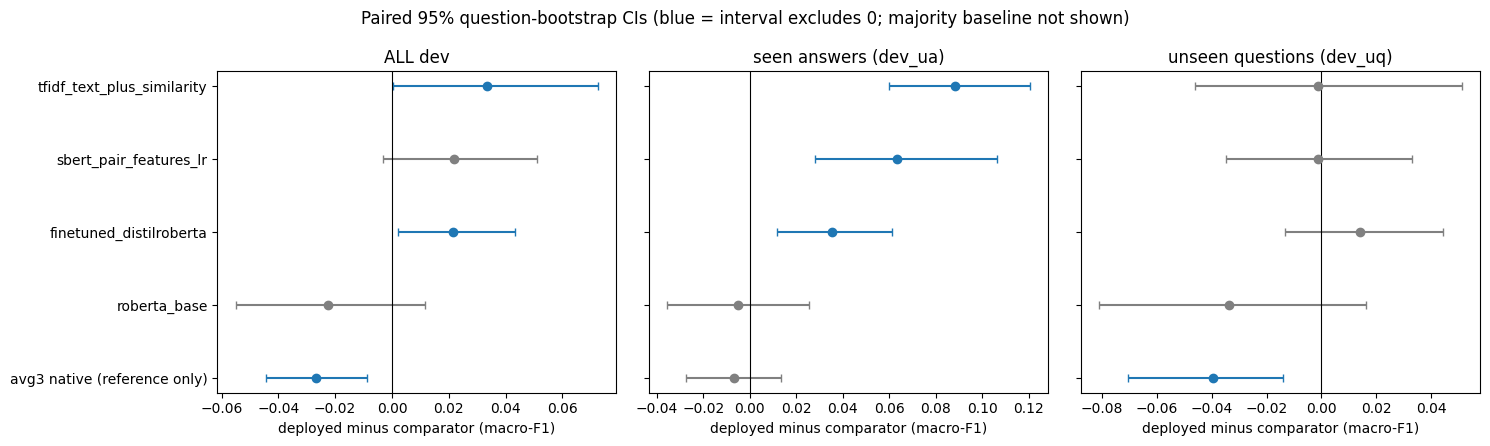

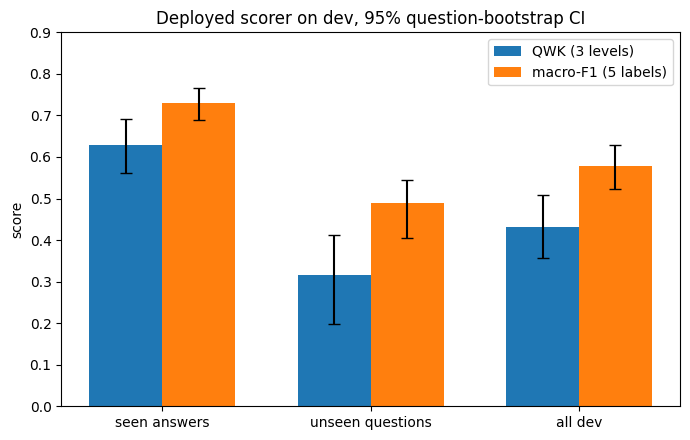

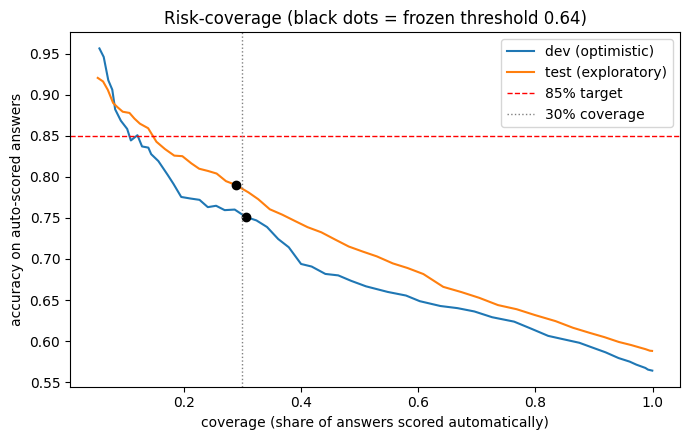

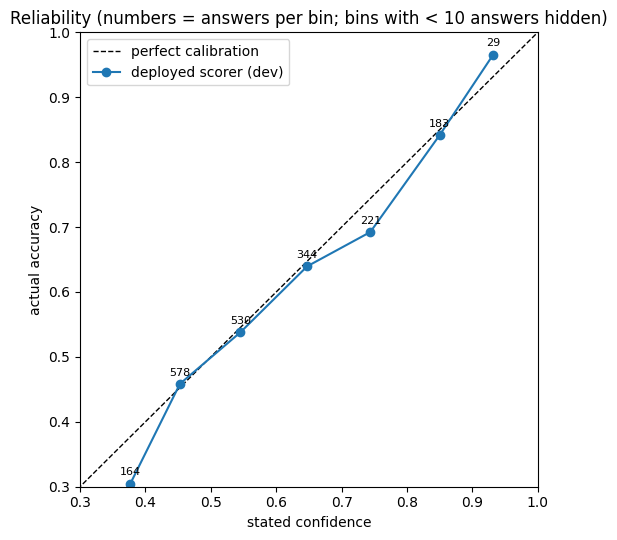

Saved: ['fig1_paired_differences.png', 'fig2_seen_vs_unseen.png', 'fig3_risk_coverage.png', 'fig4_reliability.png']


In [ ]:
import os, sys, json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
FIG = f"{V2}/figures_v2"
os.makedirs(FIG, exist_ok=True)
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)

pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
A  = pd.read_csv(f"{V2}/A_deployed_metrics_ci_v2.csv")
DL = pd.read_csv(f"{V2}/A_bootstrap_ci_v2.csv")

# ---- Figure 1: paired differences (macro-F1), deployed minus comparator ----
groups = ["ALL dev", "seen answers (dev_ua)", "unseen questions (dev_uq)"]
comp = [c for c in DL[DL.metric == "macroF1_5"].comparator.unique() if c != "majority"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, g in zip(axes, groups):
    s = DL[(DL.group == g) & (DL.metric == "macroF1_5")].set_index("comparator").loc[comp]
    for i, (c, r) in enumerate(s.iterrows()):
        sig = bool(r.excludes_zero)
        ax.errorbar(r.delta, i, xerr=[[r.delta - r.ci_low], [r.ci_high - r.delta]], fmt="o", capsize=3,
                    color="tab:blue" if sig else "gray")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(len(comp)))
    ax.set_yticklabels(comp)
    ax.set_title(g)
    ax.set_xlabel("deployed minus comparator (macro-F1)")
fig.suptitle("Paired 95% question-bootstrap CIs (blue = interval excludes 0; majority baseline not shown)")
fig.tight_layout(); fig.savefig(f"{FIG}/fig1_paired_differences.png", dpi=160); plt.show()

# ---- Figure 2: seen vs unseen questions, deployed scorer ----
order = ["seen answers (dev_ua)", "unseen questions (dev_uq)", "ALL dev"]
fig, ax = plt.subplots(figsize=(7, 4.5))
w = 0.35
for k, (m, lab) in enumerate([("qwk_3level", "QWK (3 levels)"), ("macroF1_5", "macro-F1 (5 labels)")]):
    s = A[A.metric == m].set_index("group").loc[order]
    ax.bar(np.arange(3) + k * w, s.point, w, yerr=[s.point - s.ci_low, s.ci_high - s.point], capsize=4, label=lab)
ax.set_xticks(np.arange(3) + w / 2); ax.set_xticklabels(["seen answers", "unseen questions", "all dev"])
ax.set_ylim(0, 0.9); ax.set_ylabel("score"); ax.legend()
ax.set_title("Deployed scorer on dev, 95% question-bootstrap CI")
fig.tight_layout(); fig.savefig(f"{FIG}/fig2_seen_vs_unseen.png", dpi=160); plt.show()

# ---- data for figures 3 and 4 ----
D = pd.read_parquet(f"{V2}/A_deployed_dev_probs_v2.parquet")
p3d = A_predict._to3(D[[f"d_p{j}" for j in range(5)]].values)
dev = pd.DataFrame({"conf": p3d.max(1), "pred": p3d.argmax(1), "y": D.score_ours.values.astype(int)})
TS = pd.read_parquet(f"{V2}/A_test_scored_v2.parquet")
tst = pd.DataFrame({"conf": TS.confidence.values, "pred": TS.pred_score.values.astype(int), "y": TS.score_ours.values.astype(int)})
def rc(df, t):
    m = df.conf >= t
    return float(m.mean()), (float((df.pred[m] == df.y[m]).mean()) if m.any() else np.nan)

# ---- Figure 3: risk-coverage ----
ths = np.arange(0.34, 0.96, 0.01)
fig, ax = plt.subplots(figsize=(7, 4.5))
for df, lab in [(dev, "dev (optimistic)"), (tst, "test (exploratory)")]:
    pts = [rc(df, t) for t in ths]
    pts = [(c, a) for c, a in pts if c >= 0.05]
    ax.plot([p[0] for p in pts], [p[1] for p in pts], label=lab)
    c0, a0 = rc(df, pol["confidence_threshold"])
    ax.plot(c0, a0, "o", color="k")
ax.axhline(0.85, ls="--", color="r", lw=1, label="85% target")
ax.axvline(0.30, ls=":", color="gray", lw=1, label="30% coverage")
ax.set_xlabel("coverage (share of answers scored automatically)"); ax.set_ylabel("accuracy on auto-scored answers")
ax.set_title(f"Risk-coverage (black dots = frozen threshold {pol['confidence_threshold']})"); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIG}/fig3_risk_coverage.png", dpi=160); plt.show()

# ---- Figure 4: reliability diagram on dev ----
ok = (dev.pred == dev.y).values
b = np.minimum((dev.conf.values * 10).astype(int), 9)
xs, ys, ns = [], [], []
for i in range(10):
    m = b == i
    if m.sum() >= 10:
        xs.append(dev.conf.values[m].mean()); ys.append(ok[m].mean()); ns.append(int(m.sum()))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.plot(xs, ys, "o-", label="deployed scorer (dev)")
for x, y, n in zip(xs, ys, ns):
    ax.annotate(str(n), (x, y), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax.set_xlim(0.3, 1); ax.set_ylim(0.3, 1)
ax.set_xlabel("stated confidence"); ax.set_ylabel("actual accuracy"); ax.legend()
ax.set_title("Reliability (numbers = answers per bin; bins with < 10 answers hidden)")
fig.tight_layout(); fig.savefig(f"{FIG}/fig4_reliability.png", dpi=160); plt.show()

print("Saved:", sorted(os.listdir(FIG)))

### Block 49: results summary, v2 package and status

In [ ]:
import os, sys, json, shutil, hashlib, datetime, glob
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, V2, DEMO = f"{ROOT}/interim", f"{ROOT}/reports_v2", f"{ROOT}/demo"
PKG = f"{ROOT}/project_s_qa_v2_package"
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()
def size(p):
    if os.path.isdir(p):
        return sum(os.path.getsize(os.path.join(d, f)) for d, _, fs in os.walk(p) for f in fs)
    return os.path.getsize(p) if os.path.exists(p) else None

pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
dep = json.load(open(f"{V2}/A_deployed_scorer_v2.json"))
A, TR = pd.read_csv(f"{V2}/A_deployed_metrics_ci_v2.csv"), pd.read_csv(f"{V2}/A_test_results_v2.csv")
tlog = json.load(open(f"{V2}/A_test_access_log_v2.json"))
parity = json.load(open(f"{V2}/A_demo_parity_v2.json")) if os.path.exists(f"{V2}/A_demo_parity_v2.json") else {"status": "missing"}
seed_ok = os.path.exists(f"{V2}/A_seed_summary_v2.csv")
status = "FINAL" if parity.get("status") == "pass" else "DRAFT"

# ---- 1. checklist ----
need = ["A_predict.py", "A_stats.py", "A_predict_contract_v2.json", "A_abstain_policy_v2.json", "A_deployed_scorer_v2.json",
        "A_deployed_metrics_ci_v2.csv", "A_bootstrap_ci_v2.csv", "A_test_results_v2.csv", "A_test_scored_v2.parquet",
        "A_test_access_log_v2.json", "A_demo_reference_outputs_v2.json", "A_demo_cases_summary_v2.csv", "A_final_tables_v2.md"]
missing = [n for n in need if not os.path.exists(f"{V2}/{n}")]
figs = sorted(glob.glob(f"{V2}/figures_v2/*.png"))
print("Required files missing:", missing or "none")
print("Figures:", len(figs), "| policy:", pol["status"], "| demo parity:", parity.get("status"),
      "| seed summary:", "present" if seed_ok else "pending", "| test evaluations on record:", tlog["total_test_evaluations"])
assert not missing, "run the earlier blocks first"

# ---- 2. results summary (numbers read from the saved files) ----
def g(group, metric):
    r = A[(A.group == group) & (A.metric == metric)].iloc[0]
    return f"{r.point:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]"
al = TR[TR.group == "ALL test"].iloc[0]
S = f"""# Project S, Q&A branch: v2 results summary
Status: {status} (demo parity: {parity.get('status')}; 3-seed summary: {'present' if seed_ok else 'pending'})
Created: {datetime.datetime.now().isoformat(timespec='seconds')}

## System
Pooled scorer ({dep['mode']}): average of a fine-tuned DistilRoBERTa, an SBERT pair-feature logistic regression and an NLI-feature
logistic regression, mapped to 3 levels (incorrect, partial, correct). Teacher-review flag when confidence is below
{pol['confidence_threshold']} (temperature {pol['temperature']:.2f}; contradiction flag {'on' if pol['use_contradiction_flag'] else 'off'}).
It does not need the dataset name, so it can score a new question.

## Dev results (selection was done on dev, so these are optimistic; 95% question-bootstrap CI)
- All dev: QWK {g('ALL dev','qwk_3level')}, macro-F1 {g('ALL dev','macroF1_5')}
- Seen answers: QWK {g('seen answers (dev_ua)','qwk_3level')}, macro-F1 {g('seen answers (dev_ua)','macroF1_5')}
- Unseen questions: QWK {g('unseen questions (dev_uq)','qwk_3level')}, macro-F1 {g('unseen questions (dev_uq)','macroF1_5')}

## Exploratory test (test sets were already scored once in v1; evaluations on record: {tlog['total_test_evaluations']})
- All test: macro-F1 {al.macroF1_5:.3f} [{al.macroF1_5_lo:.3f}, {al.macroF1_5_hi:.3f}], QWK {al.qwk:.3f} [{al.qwk_lo:.3f}, {al.qwk_hi:.3f}]
- Review rule: coverage {al.coverage:.3f}, accuracy on auto-scored answers {al.acc_auto:.3f} [{al.acc_auto_lo:.3f}, {al.acc_auto_hi:.3f}]
- The 85% accuracy target at 30% coverage is NOT met.

## Limitations
- Public English science and electricity answers only. Nothing here shows performance on CBSE answers or Indian children.
- The 3-level scheme is custom, so QWK is not comparable with published 3-way results.
- Unseen-question results rest on few questions (27 dev, 24 test), so intervals are wide.
- The pooled scorer is weaker than the dataset-aware ensemble (paired dev difference about -0.025 macro-F1).
- NLI "concepts" are reference-answer sentences, not expert-written concepts; a negation of one item in a list can be missed.
- The 15 hand-written demo cases are a sanity check, not an evaluation.
- Dev numbers are optimistic because the scorer, calibration and threshold were chosen on dev.
"""
open(f"{V2}/RESULTS_SUMMARY_v2.md", "w").write(S)

# ---- 3. package ----
if os.path.exists(PKG):
    shutil.rmtree(PKG)
for sub in ["reports_v2", "figures_v2", "demo"]:
    os.makedirs(f"{PKG}/{sub}")
copy = need + [os.path.basename(p) for p in glob.glob(f"{V2}/A_table_*_v2.csv")] \
      + [n for n in ["A_seed_summary_v2.csv", "A_seed_summary_v2.json", "A_demo_parity_v2.csv", "A_demo_parity_v2.json"]
         if os.path.exists(f"{V2}/{n}")]
for n in copy:
    shutil.copy(f"{V2}/{n}", f"{PKG}/reports_v2/{n}")
for p in figs:
    shutil.copy(p, f"{PKG}/figures_v2/")
for n in ["A_predict.py", "example_inputs.json", "demo_outputs.json", "demo_outputs.csv"]:
    if os.path.exists(f"{DEMO}/{n}"):
        shutil.copy(f"{DEMO}/{n}", f"{PKG}/demo/{n}")
shutil.copy(f"{V2}/RESULTS_SUMMARY_v2.md", f"{PKG}/RESULTS_SUMMARY_v2.md")

files = {os.path.relpath(os.path.join(d, f), PKG): {"sha256": sha(os.path.join(d, f)), "bytes": os.path.getsize(os.path.join(d, f))}
         for d, _, fs in os.walk(PKG) for f in fs}
external = {n: size(f"{INTERIM}/{n}") for n in ["ft_distilroberta_v1", "pooled_lr_v2.joblib", "stack_features_v1.parquet",
                                                "nli_features_v1.parquet", "rb_probs_v2.parquet"]}
manifest = {"created": datetime.datetime.now().isoformat(timespec="seconds"), "status": status,
            "demo_parity": parity.get("status"), "seed_summary": "present" if seed_ok else "pending",
            "test_evaluations_on_record": tlog["total_test_evaluations"],
            "test_note": "v2 test numbers are exploratory (test sets were scored in v1)",
            "policy": {k: pol[k] for k in ["status", "temperature", "confidence_threshold", "use_contradiction_flag"]},
            "files": files,
            "external_artifacts_not_in_zip_bytes": external}
json.dump(manifest, open(f"{PKG}/A_v2_manifest.json", "w"), indent=2)
shutil.copy(f"{PKG}/A_v2_manifest.json", f"{V2}/A_v2_manifest.json")
zp = shutil.make_archive(PKG, "zip", PKG)

print(f"\nPackage status: {status}")
print("Files in package:", len(files), "| zip:", zp, f"({os.path.getsize(zp)/1e6:.1f} MB)")
print("External artifacts (kept in Drive, not zipped):", external)
if status == "DRAFT":
    print("\nDRAFT because demo parity is not PASS yet. Re-run Blocks 45 and 49 after Vishwajeet's demo_outputs file arrives.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Required files missing: none
Figures: 4 | policy: final | demo parity: pass | seed summary: pending | test evaluations on record: 3

Package status: FINAL
Files in package: 29 | zip: /content/drive/MyDrive/project_s_qa/project_s_qa_v2_package.zip (0.4 MB)
External artifacts (kept in Drive, not zipped): {'ft_distilroberta_v1': 332061710, 'pooled_lr_v2.joblib': 63625, 'stack_features_v1.parquet': 1644342, 'nli_features_v1.parquet': 739730, 'rb_probs_v2.parquet': 72707}


# Phase 10 — Extensions and closure

## Group 17: Concept evidence, control set, stronger LLM

### Block 50: concepts and per-concept NLI

In [ ]:
import os, sys, json, glob, importlib
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)

hits = glob.glob(f"{ROOT}/**/rubrics_v1.json", recursive=True)
assert hits, "rubrics_v1.json not found (saved by Block 12)"
rub = json.load(open(hits[0]))
ref = json.load(open(f"{V2}/A_demo_reference_outputs_v2.json"))
print("Rubric entries:", len(rub), "| file:", os.path.relpath(hits[0], ROOT))

# 1. auto-draft concepts for every public question: one idea per reference sentence
for r in rub.values():
    r["required_concepts"] = [c.strip() for c in A_predict._concepts(r["reference_answer"]) if c.strip()]
    r["concepts_status"] = "auto_draft_unreviewed (reference split into sentences)"

# 2. hand-written atomic concepts for the demo questions
DEMO_CONCEPTS = {
    "Why does a metal spoon left in hot soup get hot?":
        ["Heat moves from the hot soup into the spoon.", "The heat is transferred by conduction."],
    "What do plants need to make their food?":
        ["Plants need sunlight to make food.", "Plants need water to make food.",
         "Plants need carbon dioxide to make food."],
    "Why does the bulb light when the switch is closed?":
        ["A closed switch completes the circuit.", "Current flows through the bulb."]}
demo_ref = {c["question"]: c["reference_answer"] for c in ref["cases"]}
assert set(demo_ref) == set(DEMO_CONCEPTS), "demo questions changed: update DEMO_CONCEPTS"
for i, (q, cs) in enumerate(DEMO_CONCEPTS.items(), 1):
    rub[f"DEMO-{i:02d}"] = {"question_id": f"DEMO-{i:02d}", "dataset": "demo", "question_text": q,
        "reference_answer": demo_ref[q], "required_concepts": cs,
        "concepts_status": "hand_written_unreviewed (needs a second person)", "status": "demo"}
json.dump(rub, open(f"{V2}/A_rubrics_v2.json", "w"), indent=2)

# 3. review sheet: 20 random public questions per dataset for a human to fix
rng = np.random.RandomState(42)
rows = []
for ds in ["beetle", "scientsbank"]:
    ids = [k for k, v in rub.items() if v["dataset"] == ds]
    for k in rng.choice(ids, min(20, len(ids)), replace=False):
        v = rub[k]
        rows.append(dict(question_id=k, dataset=ds, question=v["question_text"], reference=v["reference_answer"],
                         auto_concepts=" || ".join(v["required_concepts"]), reviewed_concepts="", reviewer="", ok=""))
pd.DataFrame(rows).to_csv(f"{V2}/A_concepts_review_sheet_v2.csv", index=False)

# 4. per-concept evidence with the NLI model
THR = 0.5     # (P) simple cut-off, not tuned
def evidence(answer, concepts):
    P = A_predict._nli([(answer, c) for c in concepts])        # columns: entail, contradict, neutral
    out = []
    for c, p in zip(concepts, P):
        st = "contradicted" if p[1] >= THR else ("present" if p[0] >= THR else "missing")
        out.append(dict(concept=c, status=st))
    return out

rows = []
for c in ref["cases"]:
    ev = evidence(c["student_answer"], DEMO_CONCEPTS[c["question"]])
    cnt = {s: sum(e["status"] == s for e in ev) for s in ("present", "missing", "contradicted")}
    whole = c["output"]["nli"]["contradict"]
    rows.append(dict(case=c["case_id"], kind=c["kind"], expected=c["expected_score"], scorer=c["output"]["pred_score"],
                     present=cnt["present"], missing=cnt["missing"], contradicted=cnt["contradicted"],
                     whole_ref_contra=round(whole, 3), concept_flag=cnt["contradicted"] > 0, whole_flag=whole >= THR,
                     detail=" | ".join(f'{e["status"]}:{e["concept"][:26]}' for e in ev)))
E = pd.DataFrame(rows)
print(E.drop(columns="detail").to_string(index=False))
neg = E[E.kind.isin(["negated", "contradictory"])]
oth = E[~E.kind.isin(["negated", "contradictory"])]
print(f"\nNegated or contradictory cases: {len(neg)} | caught by whole-reference NLI: {int(neg.whole_flag.sum())}"
      f" | caught by concept-level NLI: {int(neg.concept_flag.sum())}")
print(f"Other cases flagged wrongly: whole-reference {int(oth.whole_flag.sum())}/{len(oth)}"
      f" | concept-level {int(oth.concept_flag.sum())}/{len(oth)}")
E.to_csv(f"{V2}/A_concept_evidence_demo_v2.csv", index=False)
print("\nSaved A_rubrics_v2.json, A_concepts_review_sheet_v2.csv, A_concept_evidence_demo_v2.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rubric entries: 248 | file: processed/rubrics_v1.json


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

case          kind  expected  scorer  present  missing  contradicted  whole_ref_contra  concept_flag  whole_flag
 c01       correct         2       2        2        0             0             0.000         False       False
 c02       partial         1       1        1        1             0             0.003         False       False
 c03       negated         0       0        0        0             2             0.997          True        True
 c04    irrelevant         0       0        1        1             0             0.001         False       False
 c05         vague         0       0        0        2             0             0.000         False       False
 c06       correct         2       2        1        2             0             0.000         False       False
 c07       partial         1       2        0        1             2             0.001          True       False
 c08       negated         0       2        0        2             1             0.318          

### Block 51: negation, paraphrase and spelling control set

In [ ]:
import os, sys, json, importlib
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)
dep = json.load(open(f"{V2}/A_deployed_scorer_v2.json"))

# (question, reference, paraphrase, negation, spelling errors). Hand-written controls, NOT an evaluation set.
FACTS = [
 ("What do plants need to make their food?", "Plants need sunlight to make food.",
  "Plants use light from the sun to make their food.", "Plants do not need sunlight to make food.", "Plants need sunlite to make food."),
 ("What happens to water when it is heated enough?", "Water boils and turns into steam when it is heated enough.",
  "When water gets hot enough it turns into steam.", "Water does not turn into steam when it is heated.", "Water bois and turns into steem when it is heated enough."),
 ("Why does the bulb light?", "The bulb lights because the circuit is closed.",
  "The circuit is complete, so the bulb lights up.", "The bulb lights because the circuit is open.", "The bulb lights becuase the circut is closed."),
 ("What does a magnet attract?", "A magnet attracts iron.",
  "Iron is pulled toward a magnet.", "A magnet does not attract iron.", "A magnit attracts iron."),
 ("What happens to metal when it is heated?", "Metal expands when it is heated.",
  "When metal gets hot it gets bigger.", "Metal does not expand when it is heated.", "Metal expandes when it is heted."),
 ("How do fish breathe?", "Fish breathe using gills.",
  "Gills are what fish use to breathe.", "Fish cannot breathe with gills.", "Fish breath using gils."),
 ("What causes day and night?", "The Earth spins on its axis, which causes day and night.",
  "Day and night happen because the Earth rotates.", "The Earth does not rotate, so there is no day and night.", "The Earth spins on its axsis, which causes day and nite."),
 ("What do we call a material that lets electricity pass through?", "A conductor lets electricity pass through it.",
  "Electricity can flow through a conductor.", "A conductor does not let electricity pass through it.", "A conducter lets electricty pass through it."),
 ("What does a seed need to start growing?", "A seed needs water to start growing.",
  "Water is needed for a seed to begin to grow.", "A seed does not need water to start growing.", "A seed needs watter to start groing."),
 ("What happens to ice when it gets warm?", "Ice melts when it gets warm.",
  "When ice is warmed it turns into water.", "Ice does not melt when it gets warm.", "Ice melts when it gets warrm."),
 ("Which part of the plant takes in water?", "The roots take in water from the soil.",
  "Plants absorb water from the soil through their roots.", "The roots do not take in water from the soil.", "The rotes take in watter from the soil."),
 ("What makes a shadow?", "A shadow forms when an object blocks light.",
  "When something stops the light, a shadow is made.", "A shadow does not form when an object blocks light.", "A shadow forms when an object blocs light.")]

items, meta = [], []
for i, (q, r, para, neg, spell) in enumerate(FACTS, 1):
    for kind, ans, exp in [("paraphrase", para, 2), ("negation", neg, 0), ("spelling", spell, 2)]:
        items.append(dict(question=q, reference_answer=r, student_answer=ans))
        meta.append((f"n{i:02d}-{kind[:3]}", kind, exp, ans))
out = A_predict.predict_batch(items, dataset=dep["mode"])

R = pd.DataFrame([dict(id=m[0], kind=m[1], expected=m[2], pred=o["pred_score"], conf=o["confidence"],
                       review=o["needs_teacher_review"], nli_contra=o["nli"]["contradict"], answer=m[3])
                  for m, o in zip(meta, out)])
R["exact"] = R.expected == R.pred
R["safe"] = R.exact | R.review
R["silent"] = ~R.exact & ~R.review

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

rows = []
for kind, g in R.groupby("kind"):
    lo, hi = wilson(int(g.exact.sum()), len(g))
    rows.append(dict(kind=kind, n=len(g), exact=int(g.exact.sum()), exact_ci=f"{lo:.2f} to {hi:.2f}",
                     safe=int(g.safe.sum()), silent_failures=int(g.silent.sum()), mean_conf=round(g.conf.mean(), 3)))
print(pd.DataFrame(rows).to_string(index=False))
neg = R[R.kind == "negation"]
print(f"\nNegations flagged by the whole-reference NLI contradiction signal (>= 0.5): {int((neg.nli_contra >= 0.5).sum())}/{len(neg)}")
print("\nFailures (wrong predictions):")
print(R[~R.exact][["id", "kind", "expected", "pred", "conf", "review", "answer"]].to_string(index=False))
R.to_csv(f"{V2}/A_negation_paraphrase_v2.csv", index=False)
print("\nSaved A_negation_paraphrase_v2.csv. These 36 hand-written controls are a sanity check, not an evaluation.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

      kind  n  exact     exact_ci  safe  silent_failures  mean_conf
  negation 12      3 0.09 to 0.53    12                0      0.526
paraphrase 12     12 0.76 to 1.00    12                0      0.631
  spelling 12     12 0.76 to 1.00    12                0      0.612

Negations flagged by the whole-reference NLI contradiction signal (>= 0.5): 12/12

Failures (wrong predictions):
     id     kind  expected  pred   conf  review                                              answer
n01-neg negation         0     2 0.5696    True           Plants do not need sunlight to make food.
n02-neg negation         0     2 0.4398    True   Water does not turn into steam when it is heated.
n03-neg negation         0     2 0.5589    True        The bulb lights because the circuit is open.
n04-neg negation         0     2 0.5838    True                     A magnet does not attract iron.
n05-neg negation         0     2 0.6227    True            Metal does not expand when it is heated.
n06-neg negati

### Block 52: ML/DL-only audit

In [ ]:
import os, sys, json, glob, datetime
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict

dep = json.load(open(f"{V2}/A_deployed_scorer_v2.json"))
pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
lines = open(f"{V2}/A_predict.py").read().splitlines()

# 1. deployed code must not call a hosted model or web service
BANNED = ["anthropic", "openai", "api_key", "requests.", "urllib", "http://", "https://"]
hits = [(i + 1, l.strip()[:110]) for i, l in enumerate(lines) if any(b in l.lower() for b in BANNED)]
hard = [h for i, l in enumerate(lines) for h in [(i + 1, l)] if any(b in l.lower() for b in ("anthropic", "openai", "api_key"))]
print("Lines in A_predict.py that mention a URL or hosted service:", len(hits))
for n, t in hits: print("  line", n, ":", t)
assert not hard, "A_predict.py references an external API"

# 2. what the deployed code loads
loads = [(i + 1, l.strip()[:120]) for i, l in enumerate(lines)
         if any(k in l for k in ("from_pretrained(", "SentenceTransformer(", "joblib.load("))]
print("\nModels and estimators loaded:")
for n, t in loads: print("  line", n, ":", t)

# 3. side results that exist but are not part of the system
side = sorted(os.path.relpath(p, ROOT) for p in glob.glob(f"{ROOT}/**/*llm*", recursive=True))[:20]
print("\nFiles with 'llm' in the name (side result, excluded):", side or "none")

rec = {"created": datetime.datetime.now().isoformat(timespec="seconds"),
       "model_version": A_predict.MODEL_VERSION, "scorer_mode": dep["mode"], "rule": dep.get("rule"),
       "deployed_components": ["fine-tuned DistilRoBERTa 5-way classifier",
                               "SBERT embeddings + logistic regression",
                               "NLI cross-encoder features + logistic regression",
                               "temperature scaling and a confidence threshold fitted on dev"],
       "policy": {k: pol[k] for k in ["temperature", "confidence_threshold", "use_contradiction_flag"]},
       "external_api_in_deployed_code": False, "url_mentions": hits, "loads": loads,
       "excluded_from_system": ["Block 17: prompted Qwen2.5-3B-Instruct side result (not trained here)",
                                "Block 17 API option (BACKEND was local)",
                                "regex question tags and rule-based negation flag (descriptive only)"],
       "files_with_llm_in_name": side}
json.dump(rec, open(f"{V2}/A_ml_only_audit_v2.json", "w"), indent=2)
print("\nPASS: deployed code has no API reference. Saved A_ml_only_audit_v2.json")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Lines in A_predict.py that mention a URL or hosted service: 0

Models and estimators loaded:
  line 26 : nli = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).to(dev).eval()
  line 30 : ft_tok=AutoTokenizer.from_pretrained(FT_DIR),
  line 31 : ft=AutoModelForSequenceClassification.from_pretrained(FT_DIR).to(dev).eval(),
  line 32 : nli_tok=AutoTokenizer.from_pretrained(NLI_NAME), nli=nli,
  line 34 : st=SentenceTransformer(ST_NAME, device=dev),
  line 35 : base=joblib.load(INTERIM + "/combiner_v1.joblib")["base_models"])
  line 106 : _S["pooled"] = joblib.load(INTERIM + "/pooled_lr_v2.joblib")

Files with 'llm' in the name (side result, excluded): ['interim/llm_Qwen2.5-3B-Instruct_beetle_dev_ua_n250.parquet', 'interim/llm_Qwen2.5-3B-Instruct_beetle_dev_uq_n250.parquet', 'interim/llm_Qwen2.5-3B-Instruct_beetle_test_ua_n100.parquet', 'interim/llm_Q

### Block 53: generalization by question cluster (dev only)

In [ ]:
import os, sys, json
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, cohen_kappa_score

ROOT = "/content/drive/MyDrive/project_s_qa"
PROC, V2 = f"{ROOT}/processed", f"{ROOT}/reports_v2"
pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
T, thr = pol["temperature"], pol["confidence_threshold"]

Dv = pd.read_parquet(f"{V2}/A_deployed_dev_probs_v2.parquet")
P5 = Dv[[f"d_p{j}" for j in range(5)]].values
p3 = np.c_[P5[:, [1, 3, 4]].sum(1), P5[:, 2], P5[:, 0]]
q = np.clip(p3, 1e-9, 1) ** (1.0 / T); p3c = q / q.sum(1, keepdims=True)
pred, conf, y = p3c.argmax(1), p3c.max(1), Dv.score_ours.values.astype(int)
auto = conf >= thr

data = pd.read_parquet(f"{PROC}/sra_unified_splits_v1.parquet")
qt = data.drop_duplicates("question_id").set_index("question_id")["question"]
qds = Dv.drop_duplicates("question_id").set_index("question_id")["dataset"]
qids = Dv.question_id.unique()
emb = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2").encode(
    [qt[i] for i in qids], normalize_embeddings=True, show_progress_bar=False)

best = None
for k in range(3, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(emb)
    s = silhouette_score(emb, km.labels_)
    print(f"k={k}: silhouette {s:.3f}")
    if best is None or s > best[0]: best = (s, k, km)
s, K, km = best
print(f"\nChosen k={K} (silhouette {s:.3f}; low values mean the clusters are loose)")
qcl = dict(zip(qids, km.labels_))
dist = km.transform(emb)

def met(ix):
    yy, pp = y[ix], pred[ix]
    qwk = cohen_kappa_score(yy, pp, weights="quadratic", labels=[0, 1, 2]) if len(set(yy)) > 1 else np.nan
    return qwk, float((yy == pp).mean())

rng, rows = np.random.RandomState(42), []
for c in range(K):
    qs = [i for i in qids if qcl[i] == c]
    G = [np.where(Dv.question_id.values == i)[0] for i in qs]
    ix = np.concatenate(G)
    qwk, acc = met(ix)
    bq, ba = [], []
    for _ in range(1000):
        jj = np.concatenate([G[p] for p in rng.randint(0, len(G), len(G))])
        a, b = met(jj); bq.append(a); ba.append(b)
    near = [qt[qids[i]][:60] for i in np.argsort(dist[:, c])[:2]]
    rows.append(dict(cluster=c, questions=len(qs), answers=len(ix),
                     beetle_share=round(float(np.mean([qds[i] == "beetle" for i in qs])), 2),
                     QWK=round(qwk, 3), QWK_lo=round(float(np.nanpercentile(bq, 2.5)), 3),
                     QWK_hi=round(float(np.nanpercentile(bq, 97.5)), 3), acc3=round(acc, 3),
                     coverage=round(float(auto[ix].mean()), 3),
                     acc_auto=round(float((pred[ix] == y[ix])[auto[ix]].mean()), 3) if auto[ix].any() else np.nan,
                     examples=" | ".join(near)))
out = pd.DataFrame(rows)
print(out.to_string(index=False))
out.to_csv(f"{V2}/A_cluster_breakdown_v2.csv", index=False)
pd.DataFrame({"question_id": qids, "cluster": [qcl[i] for i in qids]}).to_csv(f"{V2}/A_question_clusters_v2.csv", index=False)
print("\nDev only, 177 questions. Small clusters have wide intervals. Saved A_cluster_breakdown_v2.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

k=3: silhouette 0.112
k=4: silhouette 0.111
k=5: silhouette 0.118
k=6: silhouette 0.127
k=7: silhouette 0.127
k=8: silhouette 0.141

Chosen k=8 (silhouette 0.141; low values mean the clusters are loose)
 cluster  questions  answers  beetle_share   QWK  QWK_lo  QWK_hi  acc3  coverage  acc_auto                                                                                                                    examples
       0         12       79          0.00 0.493   0.336   0.762 0.722     0.114     0.778 Look at the 2 solar water heaters shown here. The black tria | Cory and Rachael set up 3 solar water heaters to see which w
       1         49      417          0.00 0.344   0.204   0.498 0.508     0.247     0.699 Jim used a solid and water to make Mixture one (one spoon of | Jim used a solid and water to make Mixtures one (one spoon o
       2         15      317          1.00 0.404   0.343   0.539 0.603     0.388     0.813 Explain why you got a voltage reading of 1.5 for terminal 1  

## Group 18: Generalization and extension studies

### Block 54: learned deferral vs the threshold (study only, grouped CV)

In [ ]:
import os, sys, json
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, V2 = f"{ROOT}/interim", f"{ROOT}/reports_v2"
NLI_COLS = ["f_ent_mean", "f_ent_min", "f_con_max", "f_neu_mean", "r_ent", "r_con", "r_neu"]
pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
T, thr = pol["temperature"], pol["confidence_threshold"]

Dv = pd.read_parquet(f"{V2}/A_deployed_dev_probs_v2.parquet")
P5 = Dv[[f"d_p{j}" for j in range(5)]].values
p3 = np.c_[P5[:, [1, 3, 4]].sum(1), P5[:, 2], P5[:, 0]]
q = np.clip(p3, 1e-9, 1) ** (1.0 / T); p3c = q / q.sum(1, keepdims=True)
pred, conf, y = p3c.argmax(1), p3c.max(1), Dv.score_ours.values.astype(int)
ok, groups = pred == y, Dv.question_id.values

nf = pd.read_parquet(f"{INTERIM}/nli_features_v1.parquet").set_index("uid")
ent = lambda p: -(p * np.log(np.clip(p, 1e-9, 1))).sum(1)
srt = np.sort(p3c, 1)
X = np.c_[conf, srt[:, -1] - srt[:, -2], ent(p3c), ent(P5), p3c, P5, nf.loc[Dv.uid, NLI_COLS].values]
wrong = (~ok).astype(int)

models = {"logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
          "gradient_boosting": HistGradientBoostingClassifier(max_depth=3, max_iter=150, learning_rate=0.05, random_state=42)}
oof = {m: np.zeros(len(Dv)) for m in models}
for tr, te in GroupKFold(5).split(X, wrong, groups):
    for m, mdl in models.items():
        oof[m][te] = mdl.fit(X[tr], wrong[tr]).predict_proba(X[te])[:, 1]

auto_base = conf >= thr
cov0 = float(auto_base.mean())
print(f"Deployed threshold policy on dev: coverage {cov0:.3f}, accuracy on auto-scored {ok[auto_base].mean():.3f}")

def boot_diff(a, b, B=1000):
    rng = np.random.RandomState(42)
    G = [np.where(groups == g)[0] for g in np.unique(groups)]
    d = []
    for _ in range(B):
        ix = np.concatenate([G[i] for i in rng.randint(0, len(G), len(G))])
        x = ok[ix][a[ix]].mean() if a[ix].any() else np.nan
        z = ok[ix][b[ix]].mean() if b[ix].any() else np.nan
        d.append(x - z)
    d = np.array(d)
    return float(np.nanmean(d)), float(np.nanpercentile(d, 2.5)), float(np.nanpercentile(d, 97.5))

verdict = {}
for m in models:
    a = oof[m] <= np.quantile(oof[m], cov0)              # same coverage as the threshold policy
    dm, lo, hi = boot_diff(a, auto_base)
    verdict[m] = dict(coverage=round(float(a.mean()), 3), acc_auto=round(float(ok[a].mean()), 3),
                      diff_vs_threshold=round(dm, 3), ci_low=round(lo, 3), ci_high=round(hi, 3),
                      adopt=bool(dm >= 0.01 and lo > 0))
    print(m, verdict[m])

rows = []
for cov in [0.20, 0.25, 0.30, 0.35, 0.40]:
    r = dict(coverage=cov, confidence=ok[conf >= np.quantile(conf, 1 - cov)].mean())
    for m in models: r[m] = ok[oof[m] <= np.quantile(oof[m], cov)].mean()
    rows.append(r)
sweep = pd.DataFrame(rows).round(3)
print("\nAccuracy on auto-scored answers at equal coverage (grouped CV):")
print(sweep.to_string(index=False))
hit = [(m, c) for m in ["confidence"] + list(models) for c in sweep.coverage
      if c >= 0.30 and float(sweep.loc[sweep.coverage == c, m].iloc[0]) >= 0.85]
print("\n85% accuracy at 30% coverage reached:", bool(hit), hit)
print("Deployed policy is UNCHANGED. A_predict.py does not implement a learned deferral; this is a study.")
sweep.to_csv(f"{V2}/A_learned_deferral_cv_v2.csv", index=False)
json.dump({"rule": "adopt only if gain >= 0.01 and paired CI low > 0 at equal coverage",
           "results": verdict, "deployed_policy_changed": False,
           "note": "baseline threshold was chosen on all dev rows, so it has an in-sample advantage"},
          open(f"{V2}/A_learned_deferral_verdict_v2.json", "w"), indent=2)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Deployed threshold policy on dev: coverage 0.306, accuracy on auto-scored 0.751
logistic {'coverage': 0.306, 'acc_auto': 0.804, 'diff_vs_threshold': 0.055, 'ci_low': -0.017, 'ci_high': 0.123, 'adopt': False}
gradient_boosting {'coverage': 0.306, 'acc_auto': 0.815, 'diff_vs_threshold': 0.064, 'ci_low': 0.002, 'ci_high': 0.128, 'adopt': True}

Accuracy on auto-scored answers at equal coverage (grouped CV):
 coverage  confidence  logistic  gradient_boosting
     0.20       0.776     0.844              0.873
     0.25       0.764     0.828              0.838
     0.30       0.754     0.805              0.815
     0.35       0.734     0.781              0.798
     0.40       0.694     0.768              0.777

85% accuracy at 30% coverage reached: False []
Deployed policy is UNCHANGED. A_predict.py does not implement a learned deferral; this is a study.


### Block 55, deployed policy has no hand rule

In [ ]:
import os, glob, json, datetime
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
dep = json.load(open(f"{V2}/A_deployed_scorer_v2.json"))
assert pol["status"] == "final" and dep["mode"] == "pooled", "run Blocks 38 to 40 first"
assert pol["use_contradiction_flag"] is False, "the deployed policy still uses the hand-set contradiction flag"

print("Deployed review rule: send to a teacher when calibrated confidence is below", pol["confidence_threshold"])
print("Temperature:", pol["temperature"], "| both values were fitted on dev data (Blocks 39 and 40), not written by hand")
print("Stored but switched off: contradiction_nli_threshold =", pol.get("contradiction_nli_threshold"),
      "| use_contradiction_flag =", pol["use_contradiction_flag"])

v1 = sorted(glob.glob(f"{ROOT}/**/abstain_config*.json", recursive=True))
print("\nv1 abstain config file:", os.path.relpath(v1[0], ROOT) if v1 else "not found")
v1cfg = json.load(open(v1[0])) if v1 else {}
print({k: v for k, v in v1cfg.items() if not isinstance(v, (dict, list))})

rec = {"created": datetime.datetime.now().isoformat(timespec="seconds"),
       "deployed_review_rule": f"calibrated confidence below {pol['confidence_threshold']}",
       "fitted_on": "dev data (risk-coverage and grouped CV)",
       "hand_set_rules_in_deployed_policy": [],
       "v1_hand_rules_superseded": ["contradiction flag", "model-disagreement flag"],
       "v1_config_file": os.path.relpath(v1[0], ROOT) if v1 else None}
json.dump(rec, open(f"{V2}/A_v1_rule_supersession_v2.json", "w"), indent=2)
print("\nPASS: the deployed policy has no hand-set rule. Saved A_v1_rule_supersession_v2.json")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Deployed review rule: send to a teacher when calibrated confidence is below 0.64
Temperature: 1.0000000000000004 | both values were fitted on dev data (Blocks 39 and 40), not written by hand
Stored but switched off: contradiction_nli_threshold = 0.5 | use_contradiction_flag = False

v1 abstain config file: reports/abstain_config_v1.json
{'version': 'v1', 'created': '2026-10-30T08:19:28', 'confidence_threshold': 0.75, 'policy': 'A: confidence only', 'contradiction_nli_threshold': 0.5, 'target_accuracy': 0.85, 'min_coverage': 0.3, 'max_review_rate': 0.5, 'chosen_on': 'dev out-of-fold predictions only', 'rule': 'apply unchanged to the locked test splits in Group 8; do not retune'}

PASS: the deployed policy has no hand-set rule. Saved A_v1_rule_supersession_v2.json


### Block 56: withdrawn
Adaptive question selection (BM25 retrieval plus an Elo difficulty update) is not part of this project: both parts are hand-written formulas, not trained models, and the block never ran. It is listed as future work.

### Block 57, ML-derived question descriptors

In [ ]:
import os, json
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
PROC, V2 = f"{ROOT}/processed", f"{ROOT}/reports_v2"
data = pd.read_parquet(f"{PROC}/sra_unified_splits_v1.parquet")

# statistics from TRAIN answers only, so no dev or test labels leak into the descriptors
tr = data[data.split == "train"]
stat = (tr.groupby("question_id")
          .agg(n_train_answers=("uid", "size"),
               contradiction_share=("label5", lambda s: float((s == "contradictory").mean())),
               pct_correct_train=("score_ours", lambda s: float((s == 2).mean())))
          .reset_index())

qb = (data.drop_duplicates("question_id")[["question_id", "dataset", "question"]]
          .merge(stat, on="question_id", how="left"))
qb["descriptor_basis"] = np.where(qb.n_train_answers.notna(), "train answers",
                                  "no train answers (held-out question)")

cl_path = f"{V2}/A_question_clusters_v2.csv"                 # written by Block 53 (dev questions only)
if os.path.exists(cl_path):
    qb = qb.merge(pd.read_csv(cl_path).rename(columns={"cluster": "embedding_cluster"}),
                  on="question_id", how="left")
else:
    print("Block 53 has not run, so no embedding cluster column.")

qb.round(3).to_csv(f"{V2}/A_question_descriptors_v2.csv", index=False)
print("Questions:", len(qb), "| with train statistics:", int(qb.n_train_answers.notna().sum()))
print(qb.groupby("dataset")[["contradiction_share", "pct_correct_train"]].describe().round(2).T.to_string())
print("\nThese values are statistics from labelled answers and embeddings, not hand-written rules.")
print("They supersede question_type (Block 8) and negation_sensitive (Block 9) for reporting. Saved A_question_descriptors_v2.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Questions: 248 | with train statistics: 152
dataset                    beetle  scientsbank
contradiction_share count   37.00       115.00
                    mean     0.26         0.10
                    std      0.14         0.12
                    min      0.05         0.00
                    25%      0.18         0.00
                    50%      0.22         0.03
                    75%      0.32         0.16
                    max      0.66         0.71
pct_correct_train   count   37.00       115.00
                    mean     0.46         0.40
                    std      0.20         0.21
                    min      0.04         0.03
                    25%      0.28         0.23
                    50%      0.49         0.39
                    75%      0.62         0.56
                    max      0.87         0.82

These values are statistics

### Block 58: closure and zip

In [ ]:
import os, glob, json, hashlib, zipfile, datetime
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
INTERIM, V2, DEMO = f"{ROOT}/interim", f"{ROOT}/reports_v2", f"{ROOT}/demo"
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()
has = lambda n, b=V2: os.path.exists(f"{b}/{n}")
pol = json.load(open(f"{V2}/A_abstain_policy_v2.json"))
par = json.load(open(f"{V2}/A_demo_parity_v2.json")) if has("A_demo_parity_v2.json") else {}

S = [("Scorer function and policy", all(has(n) for n in ["A_predict.py", "A_deployed_scorer_v2.json", "A_abstain_policy_v2.json"]) and has("pooled_lr_v2.joblib", INTERIM), "Blocks 32 to 40"),
     ("Dev metrics with intervals", has("A_deployed_metrics_ci_v2.csv"), "Block 41"),
     ("Exploratory test run (test already seen in v1)", has("A_test_results_v2.csv"), "Block 43"),
     ("Negation, paraphrase, spelling controls", has("A_negation_paraphrase_v2.csv"), "Block 51"),
     ("Concept evidence", has("A_concept_evidence_demo_v2.csv"), "Block 50"),
     ("ML/DL-only audit", has("A_ml_only_audit_v2.json"), "Block 52"),
     ("Cluster breakdown", has("A_cluster_breakdown_v2.csv"), "Block 53 (optional)"),
     ("Learned deferral study", has("A_learned_deferral_cv_v2.csv"), "Block 54 (optional)")]
st = pd.DataFrame([dict(item=a, status="DONE" if ok else f"MISSING: run {b}") for a, ok, b in S])
st.loc[len(st)] = dict(item="Demo parity (Block 45)", status=str(par.get("status", "missing")).upper())
print(st.to_string(index=False))

for f in ["A_deployed_metrics_ci_v2.csv", "A_test_results_v2.csv"]:
    if has(f):
        print(f"\n--- {f} ---"); print(pd.read_csv(f"{V2}/{f}").round(3).to_string(index=False))

print("\nStatements for the panel (read from saved files):")
print("- Final scorer: pooled average of fine-tuned DistilRoBERTa, SBERT+LR and NLI+LR. No hosted model or API.")
print("- 85% accuracy at 30% coverage target met:", pol.get("target_met"), "| grouped-CV estimate:", pol.get("grouped_cv_estimate"))
print("- Test results are exploratory because the test sets were seen in v1.")
print("- Public English science data only. No claim about CBSE or Indian schoolchildren.")

skip_name = "A_submission_manifest_v2.json"
files = [p for p in glob.glob(f"{V2}/A_*") + glob.glob(f"{DEMO}/*") if os.path.isfile(p) and os.path.getsize(p) < 50e6 and not p.endswith(skip_name)]
skipped = [p for p in glob.glob(f"{V2}/A_*") + glob.glob(f"{DEMO}/*") if os.path.isfile(p) and os.path.getsize(p) >= 50e6 and not p.endswith(skip_name)]
manifest = {"created": datetime.datetime.now().isoformat(timespec="seconds"),
            "demo_parity": par.get("status", "missing"), "files": {os.path.relpath(p, ROOT): sha(p) for p in files},
            "skipped_over_50MB": [os.path.relpath(p, ROOT) for p in skipped]}
json.dump(manifest, open(f"{V2}/A_submission_manifest_v2.json", "w"), indent=2)
with zipfile.ZipFile(f"{ROOT}/A_submission_v2.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in files + [f"{V2}/A_submission_manifest_v2.json"]:
        z.write(p, os.path.relpath(p, ROOT))
print(f"\nZipped {len(files)} files to A_submission_v2.zip. Skipped (large): {manifest['skipped_over_50MB']}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
                                          item status
                    Scorer function and policy   DONE
                    Dev metrics with intervals   DONE
Exploratory test run (test already seen in v1)   DONE
       Negation, paraphrase, spelling controls   DONE
                              Concept evidence   DONE
                              ML/DL-only audit   DONE
                             Cluster breakdown   DONE
                        Learned deferral study   DONE
                        Demo parity (Block 45)   PASS

--- A_deployed_metrics_ci_v2.csv ---
                    group     metric  n_questions  n_answers  point  ci_low  ci_high
                  ALL dev qwk_3level          177       2049  0.432   0.358    0.509
                  ALL dev  macroF1_5          177       2049  0.579   0.523    0.629
    seen answers (dev_ua) qwk_3level  

### Block 59: latency benchmark (single-answer and batch, in ms)


In [ ]:
import os, sys, json, time, importlib
import numpy as np
import torch
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"
sys.path.insert(0, V2)
import A_predict
importlib.reload(A_predict)

# Print runtime hardware
dev_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"Colab Runtime Hardware: {dev_name} (CUDA available: {torch.cuda.is_available()})")

# Load reference outputs for test inputs
ref_data = json.load(open(f"{V2}/A_demo_reference_outputs_v2.json"))
scorer_mode = ref_data.get("scorer_mode", "both")

# --- Single Answer Latency ---
q = ref_data["cases"][0]["question"]
ref = ref_data["cases"][0]["reference_answer"]
ans = ref_data["cases"][0]["student_answer"]

# Warm-up (1 run)
_ = A_predict.predict(q, ref, ans, dataset=scorer_mode)

# 20 timed runs
single_times = []
for _ in range(20):
    t0 = time.perf_counter()
    _ = A_predict.predict(q, ref, ans, dataset=scorer_mode)
    single_times.append((time.perf_counter() - t0) * 1000.0)

median_single_ms = float(np.median(single_times))

# --- Batch Latency (15 reference items) ---
batch_items = [{"question": c["question"], "reference_answer": c["reference_answer"], "student_answer": c["student_answer"]}
               for c in ref_data["cases"]]

# Warm-up (1 run)
_ = A_predict.predict_batch(batch_items, dataset=scorer_mode)

# 20 timed runs
batch_times = []
for _ in range(20):
    t0 = time.perf_counter()
    _ = A_predict.predict_batch(batch_items, dataset=scorer_mode)
    batch_times.append((time.perf_counter() - t0) * 1000.0)

median_batch_ms = float(np.median(batch_times))
median_per_item_ms = median_batch_ms / len(batch_items)

print(f"Single-answer latency (median of 20 runs): {median_single_ms:.1f} ms")
print(f"Batch latency for {len(batch_items)} items (median of 20 runs): {median_batch_ms:.1f} ms ({median_per_item_ms:.1f} ms / item)")


### Block 60: question dropdown and voice input demo (adult voices only)


In [ ]:
# Block 60: question dropdown + voice input demo (adult voices only). Writes no files.
!pip -q install gradio transformers accelerate
import os, sys, importlib
import pandas as pd, torch
from google.colab import drive
drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/project_s_qa"
sys.path.insert(0, f"{ROOT}/reports_v2")
import A_predict
importlib.reload(A_predict)
import gradio as gr
from transformers import pipeline

# 1. Question bank, read-only. Falls back to one built-in question if the CSV is missing.
QB_PATH = f"{ROOT}/processed/cbse_demo_questions_v1.csv"
if os.path.exists(QB_PATH):
    qb = pd.read_csv(QB_PATH).fillna("")
else:
    print("MISSING:", QB_PATH, "-> using one built-in question")
    qb = pd.DataFrame([{"question_id": "demo", "question_text": "Do plants need sunlight?",
                        "reference_answer": "Plants need sunlight to make food through photosynthesis."}])
LOOKUP = {f"{r['question_id']}: {r['question_text']}": (r["question_text"], r["reference_answer"])
          for _, r in qb.iterrows()}

# 2. Local open-weights speech model (no API, rule L8).
asr = pipeline("automatic-speech-recognition", model="openai/whisper-small",
               device=0 if torch.cuda.is_available() else -1, chunk_length_s=30)

def pick(label):
    return LOOKUP.get(label, ("", ""))          # dropdown fills the question and reference boxes

def transcribe(path):
    if not path:
        return ""
    # UNDERSTAND THIS: the transcript is only a draft. Any error here flows into the score.
    return asr(path, generate_kwargs={"language": "en", "task": "transcribe"})["text"].strip()

def score(question, reference, answer):
    if not (question.strip() and reference.strip() and answer.strip()):
        return "Fill the question, reference and answer boxes.", []
    # UNDERSTAND THIS: same function and default arguments as Block 45c, so demo parity still holds.
    r = A_predict.predict(question, reference, answer)
    why = (" (" + ", ".join(r["review_reasons"]) + ")") if r["review_reasons"] else ""
    text = (f"Predicted: {r['pred_label']} (score {r['pred_score']} / 2)\n"
            f"Confidence: {r['confidence']:.3f}\n"
            f"Teacher review: {'YES' if r['needs_teacher_review'] else 'no'}{why}\n"
            f"P(incorrect / partial / correct): {r['p_incorrect']:.3f} / {r['p_partial']:.3f} / {r['p_correct']:.3f}\n"
            f"NLI: entail {r['nli']['entail']:.3f}, contradict {r['nli']['contradict']:.3f}\n"
            f"Model: {r['model_version']}")
    return text, r["concepts"]

# 3. Page. Check argument names (sources=, stop_recording) against your Gradio version.
with gr.Blocks(title="Project S: Q&A scorer (v2) with voice") as demo:
    gr.Markdown("**Project S Q&A scorer (v2).** Trained on public data (SciEntsBank, Beetle). "
                "The CBSE-style questions and the voice input are untested demo features. "
                "Adult voices only; speech errors flow into the score. "
                "Review flag when confidence is below 0.64. The NLI evidence can mislead on off-topic answers.")
    dd = gr.Dropdown(choices=list(LOOKUP), label="Question bank (optional)")
    q = gr.Textbox(label="Question")
    ref = gr.Textbox(label="Reference answer")
    mic = gr.Audio(sources=["microphone"], type="filepath", label="Speak the answer (adult voice)")
    ans = gr.Textbox(label="Student answer (editable transcript)")
    out = gr.Textbox(label="Result", lines=7)
    ev = gr.JSON(label="Per-idea NLI evidence")
    dd.change(pick, dd, [q, ref])
    mic.stop_recording(transcribe, mic, ans)
    gr.Button("Score").click(score, [q, ref, ans], [out, ev])
demo.launch(debug=False)


### Block 61: component probabilities for the 12 negations (diagnostic, writes nothing)


In [ ]:
import sys, pandas as pd
from google.colab import drive; drive.mount("/content/drive")
V2="/content/drive/MyDrive/project_s_qa/reports_v2"; sys.path.insert(0,V2)
import A_predict
triples=[
("What do plants need to make their food?","Plants need sunlight to make food.","Plants do not need sunlight to make food."), ("What happens to water when it is heated enough?","Water boils and turns into steam when it is heated enough.","Water does not turn into steam when it is heated."),
("Why does the bulb light?","The bulb lights because the circuit is closed.","The bulb lights because the circuit is open."), ("What does a magnet attract?","A magnet attracts iron.","A magnet does not attract iron."),
("What happens to metal when it is heated?","Metal expands when it is heated.","Metal does not expand when it is heated."), ("How do fish breathe?","Fish breathe using gills.","Fish cannot breathe with gills."),
("What causes day and night?","The Earth spins on its axis, which causes day and night.","The Earth does not rotate, so there is no day and night."), ("What do we call a material that lets electricity pass through?","A conductor lets electricity pass through it.","A conductor does not let electricity pass through it."),
("What does a seed need to start growing?","A seed needs water to start growing.","A seed does not need water to start growing."), ("What happens to ice when it gets warm?","Ice melts when it gets warm.","Ice does not melt when it gets warm."),
("Which part of the plant takes in water?","The roots take in water from the soil.","The roots do not take in water from the soil."), ("What makes a shadow?","A shadow forms when an object blocks light.","A shadow does not form when an object blocks light.")]
df=pd.read_csv(f"{V2}/A_negation_paraphrase_v2.csv"); g=df[df["kind"]=="negation"].reset_index(drop=True)
assert all(r["answer"]==t[2] for t,r in zip(triples,g.to_dict("records")))
ids=g["id"].tolist() if "id" in g.columns else g.index.tolist()
items=[dict(question=t[0],reference_answer=t[1],student_answer=r["answer"]) for t,r in zip(triples,g.to_dict("records"))]
p=A_predict.component_probs(items,dataset="pooled")
for i,r in g.iterrows():
    print(ids[i],r["answer"],*(f"{k}={A_predict.LABEL5_ORDER[int(p[k][i].argmax())]}:{p[k][i].max():.4f}" for k in ("ft","sb","nl")))

### Block 62: stage timing (writes nothing)


In [ ]:
import sys, json, time, numpy as np, torch
from google.colab import drive; drive.mount("/content/drive")
V2="/content/drive/MyDrive/project_s_qa/reports_v2"; sys.path.insert(0,V2); import A_predict
S=A_predict._load(); sync=torch.cuda.synchronize if S["dev"]=="cuda" else (lambda: None); cases=json.load(open(f"{V2}/A_demo_reference_outputs_v2.json"))["cases"]
def med(fn,n=20):
    fn(); sync(); t=[]
    for _ in range(n):
        s=time.perf_counter(); fn(); sync(); t.append((time.perf_counter()-s)*1000)
    return float(np.median(t))
for name,rows in (("single",cases[:1]),("batch15",cases)):
    it=[{k:c[k] for k in ("question","reference_answer","student_answer")} for c in rows]
    pairs=[(x["reference_answer"],x["student_answer"]) for x in it]
    for stage,fn in (("DistilRoBERTa",lambda:A_predict._ft(it)),
                     ("NLI (whole-reference pairs only)",lambda:A_predict._nli(pairs)),
                     ("SBERT features",lambda:A_predict._sb_X(it)),
                     ("component_probs total",lambda:A_predict.component_probs(it,dataset="pooled")),
                     ("predict_batch total",lambda:A_predict.predict_batch(it,dataset="pooled"))):
        print(name,stage,f"{med(fn):.1f} ms")

### Limitations and experimental settings
- Data: public English science answers (SciEntsBank, Beetle). No claim about CBSE/NCERT or Indian schoolchildren.
- All model selection used dev splits only. The test sets were already seen in v1; the test-access log reads 3 evaluations, so test results are exploratory.
- Unseen-question QWK is 0.317 (CI 0.199 to 0.412) over only 27 questions: a weak, uncertain result.
- The 85% accuracy at 30% coverage target was not met (grouped-CV estimate about 0.748 at 0.313 coverage).
- Negated answers are scored exactly in only 3 of 12 cases, but all 12 are flagged for teacher review.
- The demo calls the same function as the notebook, so the parity check shows consistency, not independent replication.
- The RoBERTa-base comparison rows come from saved probabilities; its weights were not saved, so that row cannot be regenerated.
- A full re-run on 30 Oct 2026 reproduced the deployed scores exactly. Legacy comparison tables moved by 0.006 or less.
- v3 and adaptive question selection are future work.
- The NLI evidence panel shows entailment 0.87 to 0.96 for three of four unrelated sentences, so it cannot be presented as an explanation for off-topic answers.
- A_predict.py has the Google Drive project path (/content/drive/MyDrive/project_s_qa) hard-coded and must be overridden when executing from a differently named folder.


### Summary for the panel (loads saved files)


In [ ]:
import os, glob, json
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/project_s_qa"
V2 = f"{ROOT}/reports_v2"

# 1. A_deployed_scorer_v2.json
p_scorer = f"{V2}/A_deployed_scorer_v2.json"
if os.path.exists(p_scorer):
    print("=== Deployed Scorer ===")
    print(json.dumps(json.load(open(p_scorer)), indent=2))

# 2. A_ml_only_audit_v2.json
p_ml = f"{V2}/A_ml_only_audit_v2.json"
if os.path.exists(p_ml):
    print("\n=== ML-Only Audit ===")
    print(json.dumps(json.load(open(p_ml)), indent=2))

# 3. A_abstain_policy_v2.json
p_pol = f"{V2}/A_abstain_policy_v2.json"
if os.path.exists(p_pol):
    print("\n=== Abstain Policy ===")
    print(json.dumps(json.load(open(p_pol)), indent=2))

# 4. A_demo_parity_v2.json
p_par = f"{V2}/A_demo_parity_v2.json"
if os.path.exists(p_par):
    print("\n=== Demo Parity Status ===")
    print(json.dumps(json.load(open(p_par)), indent=2))

# 5. A_model_comparison_dev_v2.csv
p_cmp = f"{V2}/A_model_comparison_dev_v2.csv"
if os.path.exists(p_cmp):
    print("\n=== Dev Model Comparison ===")
    print(pd.read_csv(p_cmp).round(3).to_string(index=False))

# 6. A_deployed_metrics_ci_v2.csv
p_dev_ci = f"{V2}/A_deployed_metrics_ci_v2.csv"
if os.path.exists(p_dev_ci):
    print("\n=== Deployed Dev Metrics with CIs ===")
    print(pd.read_csv(p_dev_ci).round(3).to_string(index=False))

# 7. A_test_results_v2.csv
p_test = f"{V2}/A_test_results_v2.csv"
if os.path.exists(p_test):
    print("\n=== Exploratory Test Results ===")
    print(pd.read_csv(p_test).round(3).to_string(index=False))

# 8. A_negation_paraphrase_v2.csv
p_neg = f"{V2}/A_negation_paraphrase_v2.csv"
if os.path.exists(p_neg):
    print("\n=== Negation & Paraphrase Controls ===")
    print(pd.read_csv(p_neg).round(3).to_string(index=False))

# 9. Figures fig*_*.png
figs = sorted(glob.glob(f"{V2}/fig*_*.png"))
print("\n=== Saved Figures ===")
for fig in figs:
    print(f"- {os.path.basename(fig)} ({os.path.getsize(fig)} bytes)")
